In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)

Magnification = 60.733x
Object-plane sampling = 56.81 nm/pixel

Found 50 TIFF files.


BEST FOCUS RESULTS

--- Minimum FWHM ---
Step                 = +24
Nominal z            = +0.720 um
FWHM X               = 9.88 px = 561 nm
FWHM Y               = 9.80 px = 557 nm
Geometric FWHM       = 9.84 px = 559 nm
Ellipticity          = 1.0085
First-ring / peak    = 3.10 %
Central energy       = 84.79 %

--- Minimum first-ring intensity ---
Step                 = +24
Ring / peak          = 3.10 %
Geometric FWHM       = 9.84 px = 559 nm
Central energy       = 84.79 %

--- Maximum central-lobe energy ---
Step                 = -24
Central energy       = 85.28 %
Ring / peak          = 3.45 %
Geometric FWHM       = 10.12 px = 575 nm

--- Maximum fitted peak ---
Step                 = +50
Peak normalized      = 1.000
Geometric FWHM       = 10.51 px


,step,fwhm_x_px,fwhm_y_px,fwhm_geo_px,fwhm_geo_um,ellipticity,ring_peak_fraction,central_energy_fraction,peak_normalized
0,-50,9.9939,12.0454,10.9718,0.6233,1.2053,NaN,NaN,0.9809
1,-48,9.6050,12.0159,10.7430,0.6103,1.2510,NaN,NaN,0.7438
2,-46,10.1571,11.2662,10.6973,0.6077,1.1092,NaN,NaN,0.8998
3,-44,10.2347,10.8856,10.5551,0.5996,1.0636,NaN,NaN,0.9441
4,-42,10.2604,10.5983,10.4280,0.5924,1.0329,NaN,NaN,0.9064
5,-40,9.9116,10.7723,10.3330,0.5870,1.0868,NaN,NaN,0.8716
6,-38,10.2294,10.7963,10.5090,0.5970,1.0554,NaN,NaN,0.9256
7,-36,10.2084,10.4292,10.3182,0.5861,1.0216,NaN,NaN,0.8970
8,-34,11.1023,9.9147,10.4917,0.5960,1.1198,NaN,NaN,0.9309
9,-32,9.9424,11.4493,10.6692,0.6061,1.1516,NaN,NaN,0.8479


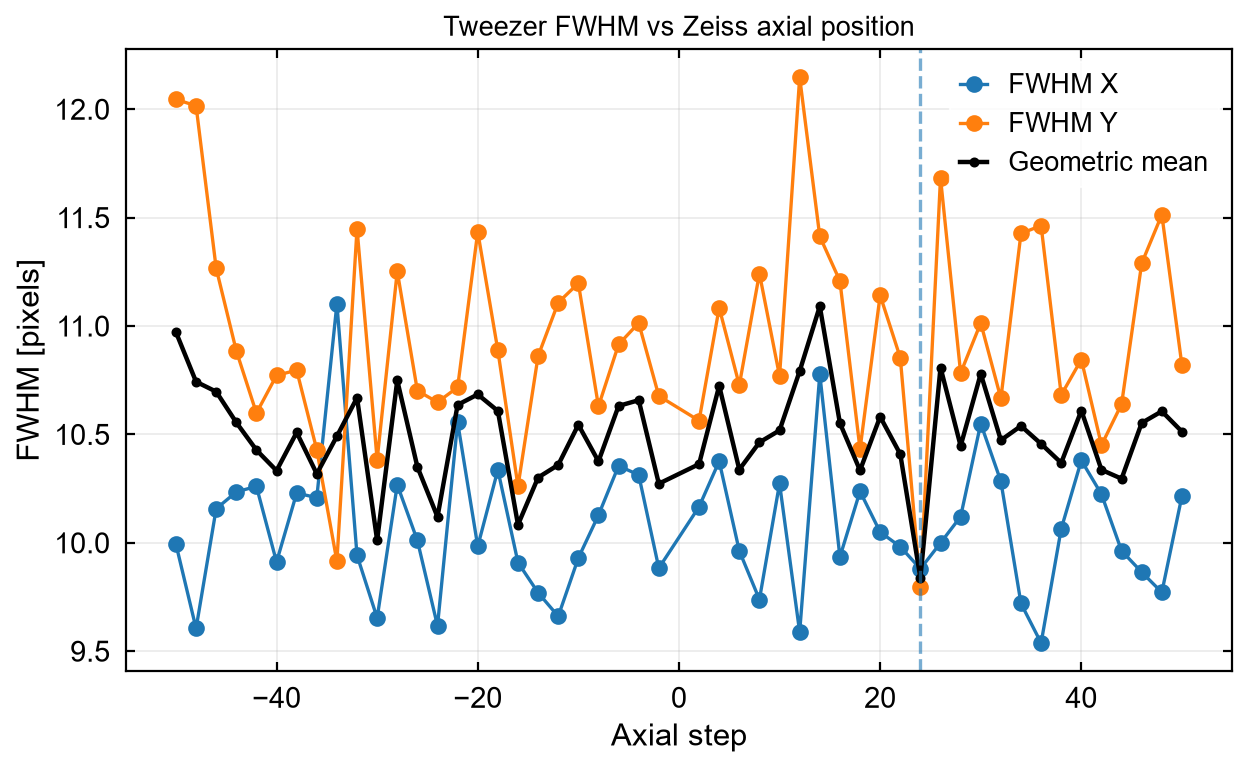

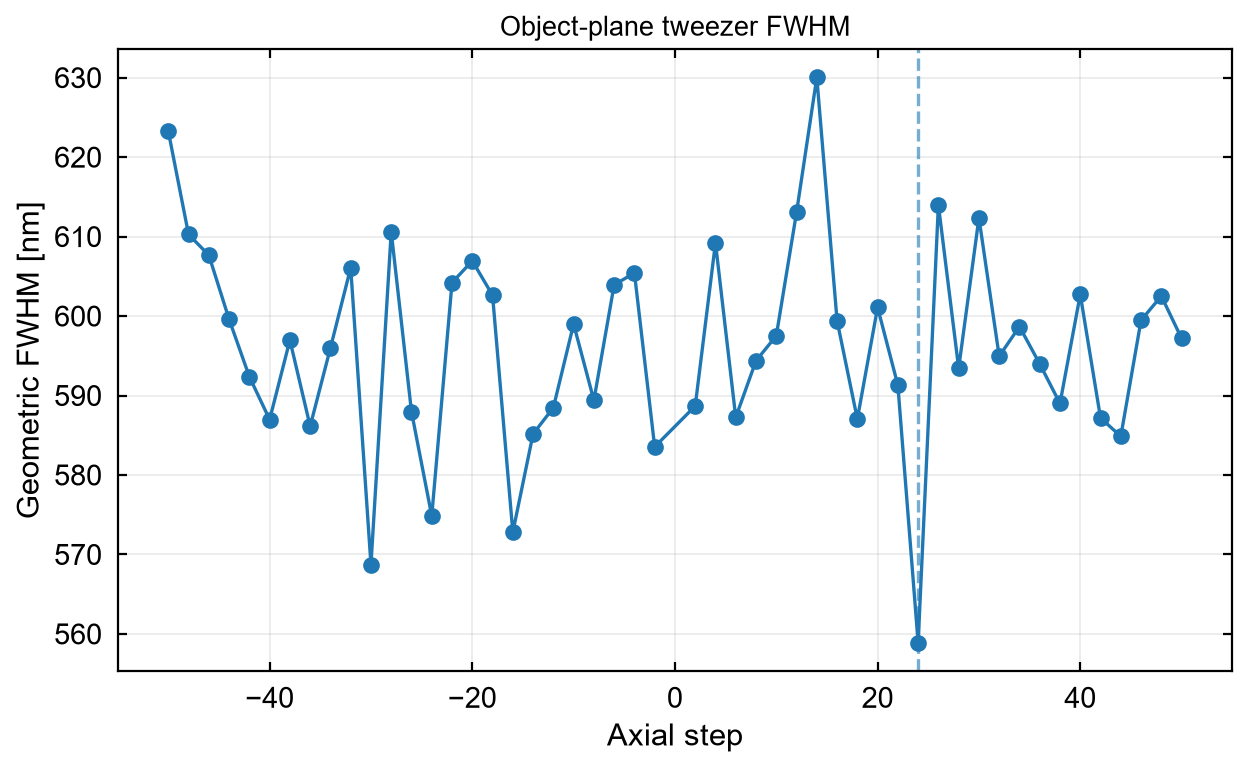

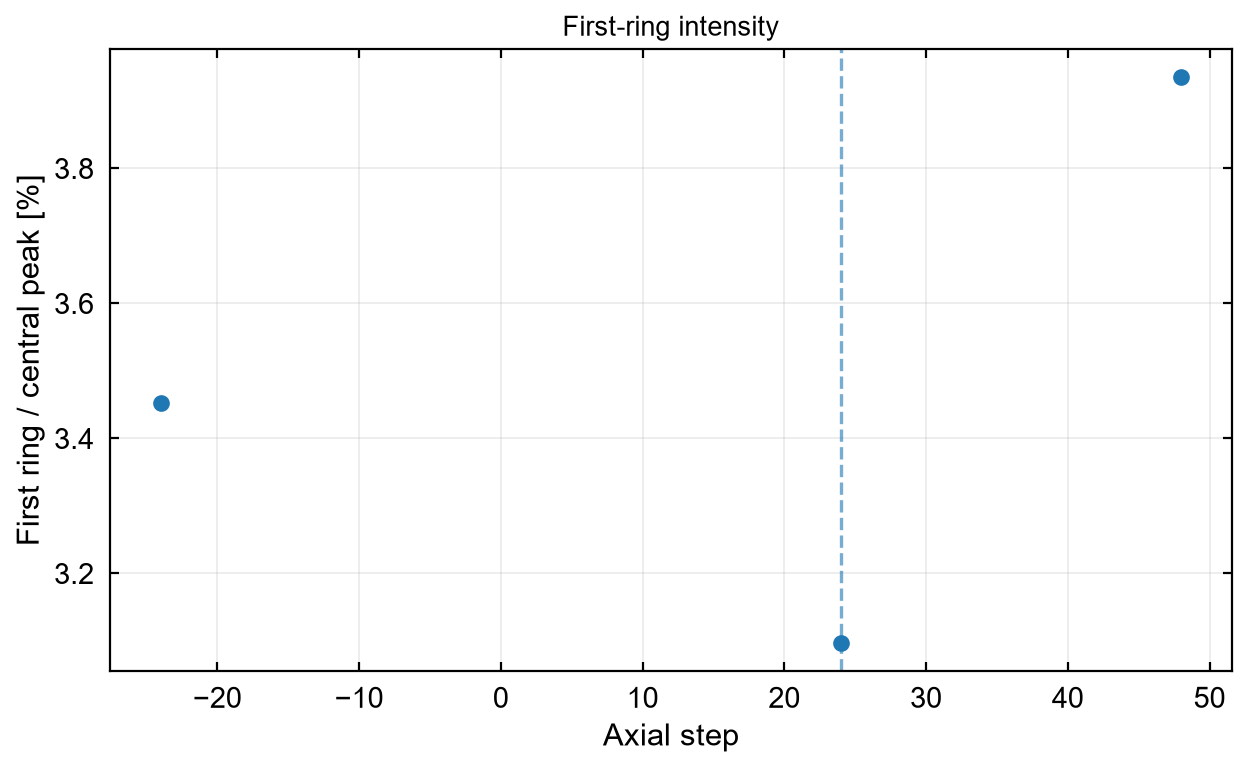

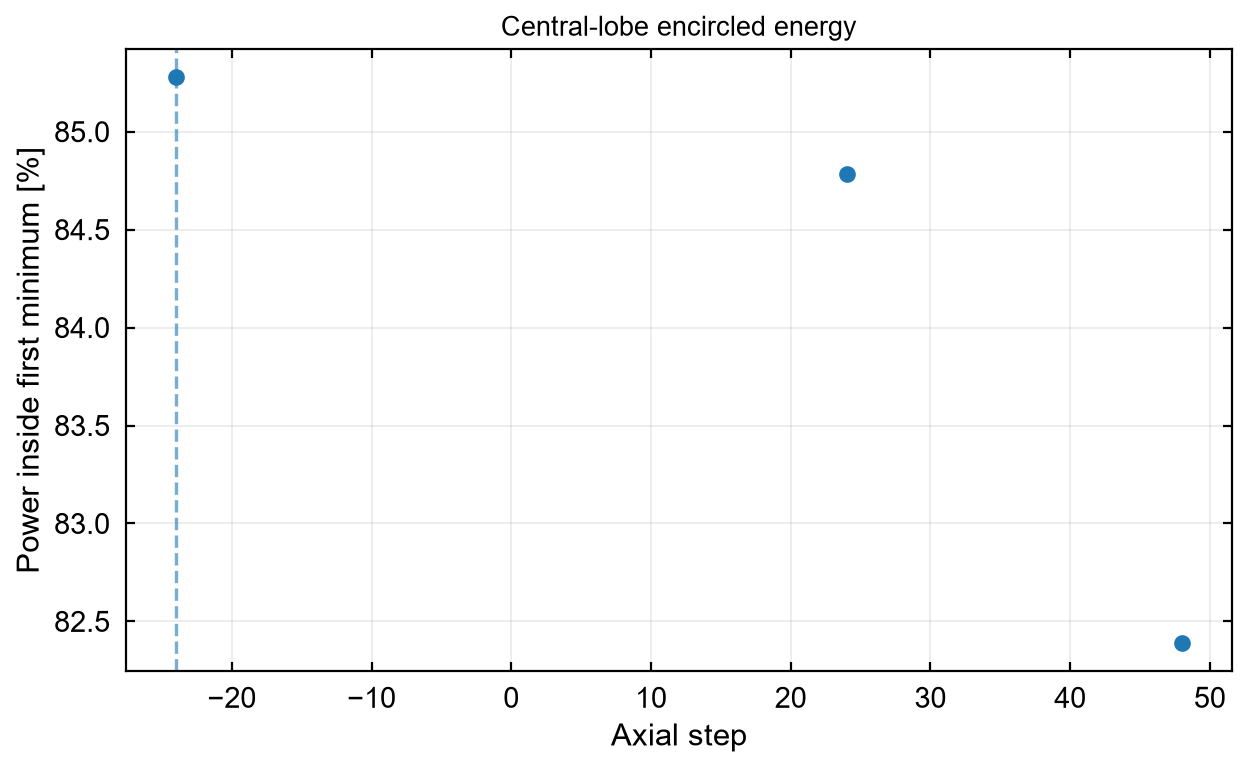

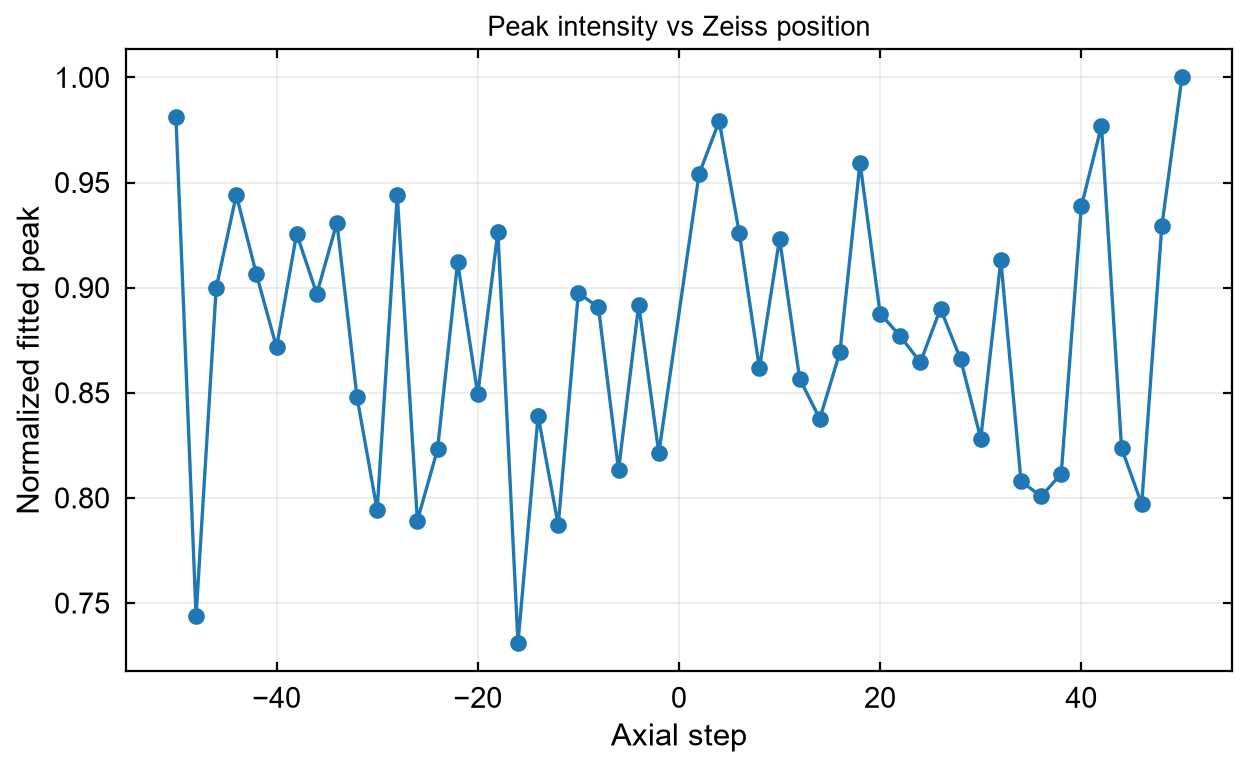

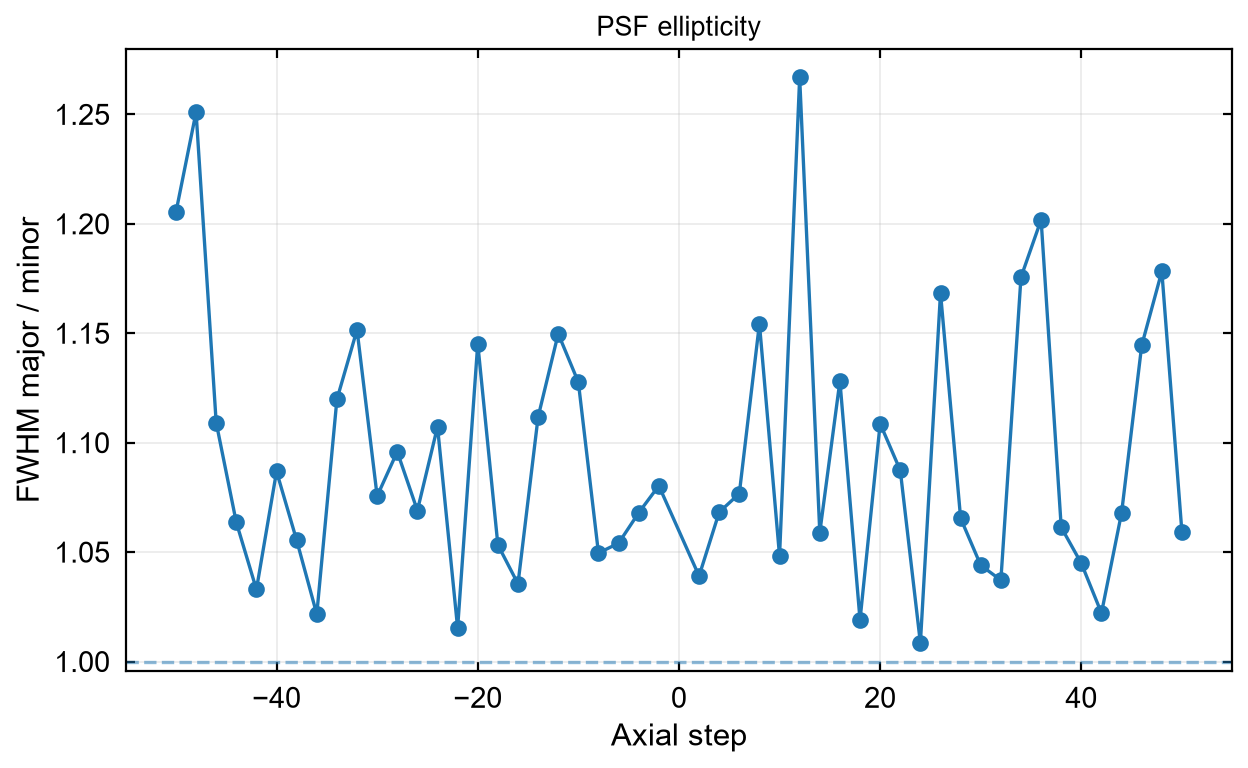

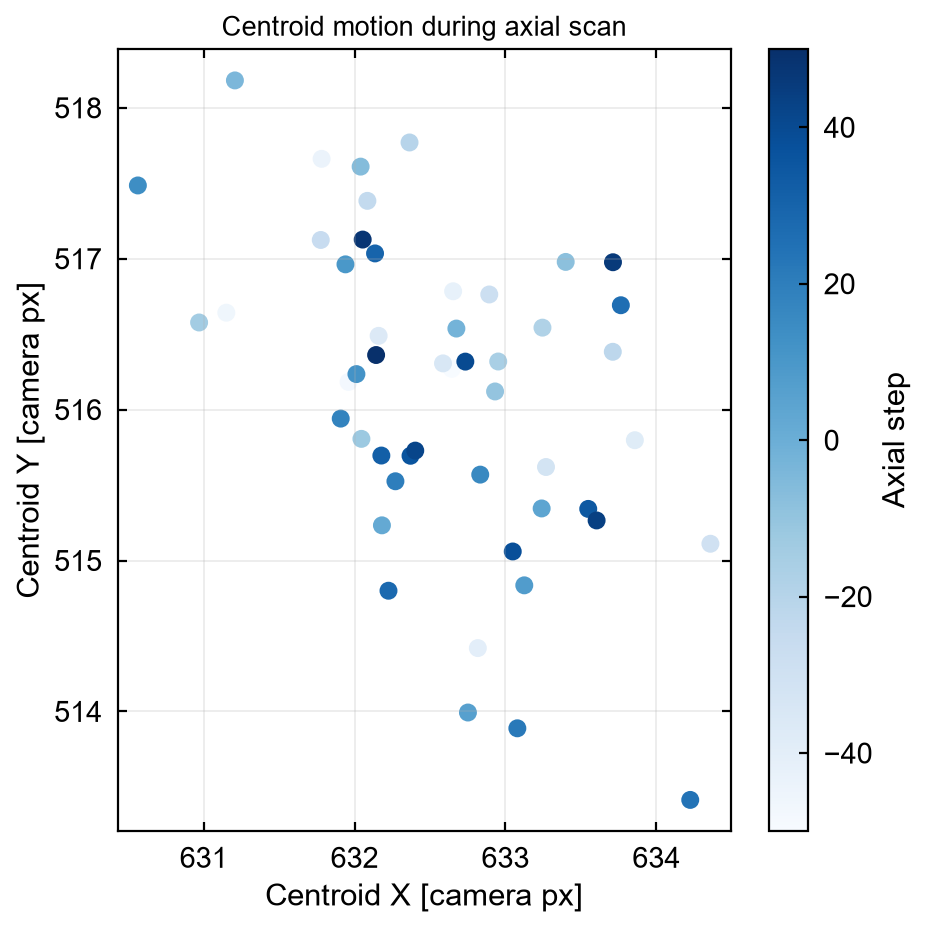



BEST OVERALL PSF
Step                 = +24
Nominal z            = +0.720 um
Geometric FWHM       = 9.84 px = 559 nm
First-ring / peak    = 3.10 %
Central-lobe energy  = 84.79 %
Ellipticity          = 1.0085


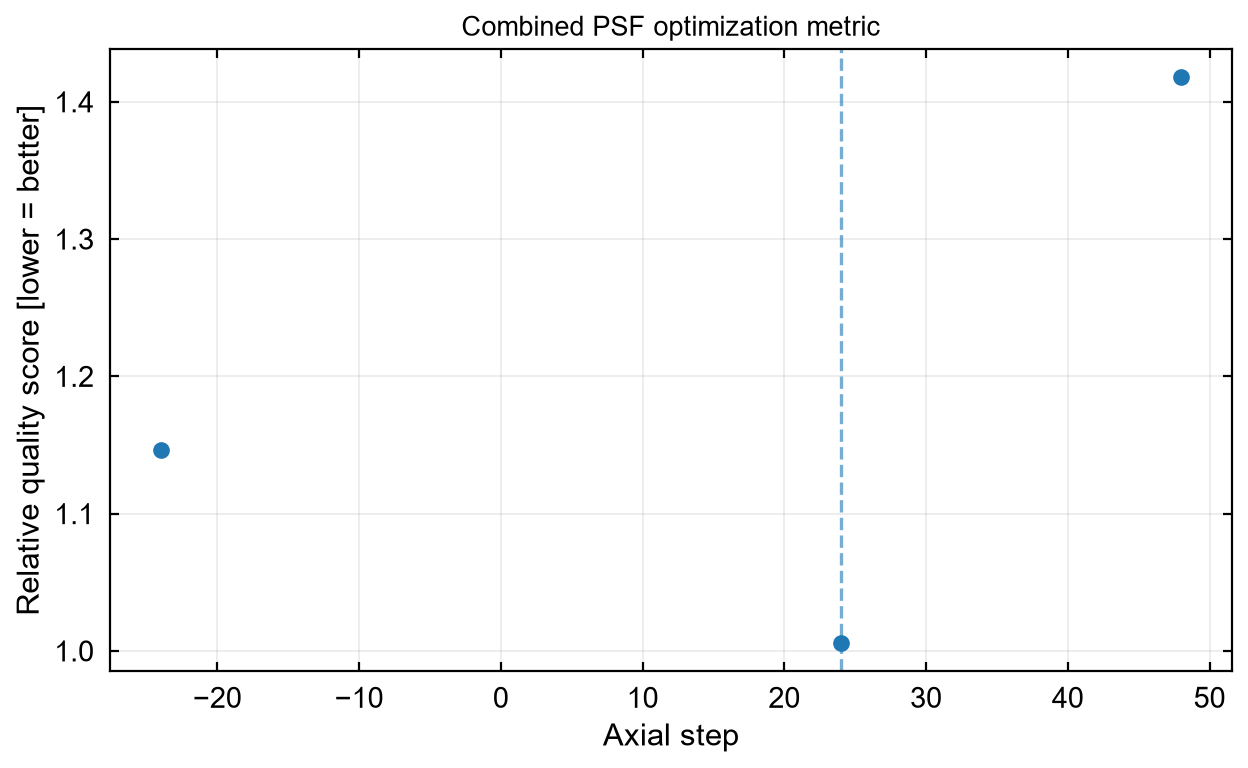


Saved results to:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data\atom array\axial scan single tweezer\axial_scan_analysis.csv


In [2]:
# ============================================================
# AXIAL SCAN ANALYSIS — SINGLE TWEEZER
# ============================================================

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tifffile import imread
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks


# ============================================================
# USER PARAMETERS
# ============================================================

FOLDER = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data\atom array\axial scan single tweezer"
)

CAMERA_PIXEL_UM = 3.45

# From your earlier calibration:
# M(300-mm tube lens) = 182.2x
# Current tube lens = 100 mm
MAGNIFICATION = 182.2 * (100.0 / 300.0)     # ~60.73x

OBJECT_PIXEL_UM = CAMERA_PIXEL_UM / MAGNIFICATION

# Optional conversion from filename "step" to physical Zeiss motion.
# If these numbers correspond to Newport Picomotor steps:
STEP_NM = 30.0       # set None if you don't want physical z conversion

# Half-width of crop around the spot.
# 100 -> 201x201 pixel ROI.
ROI_HALF_SIZE = 100

# Radius used for "total PSF power" calculation.
TOTAL_POWER_RADIUS_PX = 70

# Radius around center used for Gaussian fit.
GAUSSIAN_FIT_RADIUS_PX = 20

# Radial profile smoothing.
RADIAL_SMOOTH_SIGMA = 1.5


print(f"Magnification = {MAGNIFICATION:.3f}x")
print(f"Object-plane sampling = {OBJECT_PIXEL_UM*1000:.2f} nm/pixel")


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def parse_step(path):
    """
    Extract integer axial coordinate from filename:
    -10.tif -> -10
     24.tif -> 24
    """
    return int(path.stem)


def gaussian2d(coords, offset, amp, x0, y0, sx, sy):
    x, y = coords

    g = offset + amp * np.exp(
        -0.5 * (
            ((x - x0) / sx)**2 +
            ((y - y0) / sy)**2
        )
    )

    return g.ravel()


def crop_around_peak(image, half_size=100):
    """
    Find brightest pixel after light smoothing and crop around it.
    """
    smooth = gaussian_filter1d(
        gaussian_filter1d(image.astype(float), 2, axis=0),
        2,
        axis=1
    )

    py, px = np.unravel_index(np.argmax(smooth), smooth.shape)

    y1 = max(0, py - half_size)
    y2 = min(image.shape[0], py + half_size + 1)

    x1 = max(0, px - half_size)
    x2 = min(image.shape[1], px + half_size + 1)

    crop = image[y1:y2, x1:x2].astype(float)

    return crop, x1, y1


def estimate_background(img):
    """
    Background from border pixels.
    """
    border = np.concatenate([
        img[0:10, :].ravel(),
        img[-10:, :].ravel(),
        img[:, 0:10].ravel(),
        img[:, -10:].ravel()
    ])

    return np.median(border)


def fit_gaussian_core(img, fit_radius=20):
    """
    Fit an elliptical 2D Gaussian near the PSF core.
    """

    bg = estimate_background(img)
    work = img - bg

    work[work < 0] = 0

    py, px = np.unravel_index(np.argmax(work), work.shape)

    y, x = np.indices(work.shape)

    mask = (
        (x - px)**2 +
        (y - py)**2
    ) <= fit_radius**2

    xfit = x[mask]
    yfit = y[mask]
    zfit = img[mask]

    p0 = [
        bg,
        np.max(img) - bg,
        px,
        py,
        5,
        5
    ]

    bounds = (
        [
            0,
            0,
            px - 10,
            py - 10,
            0.5,
            0.5
        ],
        [
            np.inf,
            np.inf,
            px + 10,
            py + 10,
            30,
            30
        ]
    )

    popt, pcov = curve_fit(
        gaussian2d,
        (xfit, yfit),
        zfit.ravel(),
        p0=p0,
        bounds=bounds,
        maxfev=20000
    )

    offset, amp, x0, y0, sx, sy = popt

    conversion = 2 * np.sqrt(2 * np.log(2))

    fwhm_x = conversion * sx
    fwhm_y = conversion * sy

    return {
        "background": offset,
        "amplitude": amp,
        "x0": x0,
        "y0": y0,
        "sigma_x": sx,
        "sigma_y": sy,
        "fwhm_x_px": fwhm_x,
        "fwhm_y_px": fwhm_y
    }


def radial_profile(img, x0, y0, background):
    """
    Azimuthally averaged radial PSF profile.
    """

    data = img.astype(float) - background
    data[data < 0] = 0

    y, x = np.indices(data.shape)

    r = np.sqrt(
        (x - x0)**2 +
        (y - y0)**2
    )

    r_int = r.astype(int)

    radial_sum = np.bincount(
        r_int.ravel(),
        weights=data.ravel()
    )

    radial_count = np.bincount(
        r_int.ravel()
    )

    radial = radial_sum / np.maximum(radial_count, 1)

    return np.arange(len(radial)), radial


def get_ring_metrics(
    img,
    x0,
    y0,
    background,
    total_radius=70,
    smooth_sigma=1.5
):
    """
    Extract:
      - first radial minimum
      - first-ring maximum
      - ring / peak ratio
      - encircled-energy fraction within first minimum
    """

    r, profile = radial_profile(
        img,
        x0,
        y0,
        background
    )

    profile_s = gaussian_filter1d(
        profile,
        smooth_sigma
    )

    # Normalize to central peak
    peak = np.max(profile_s[:5])

    if peak <= 0:
        return np.nan, np.nan, np.nan, np.nan

    pn = profile_s / peak

    # --------------------------------------------------------
    # Find first minimum
    #
    # Ignore very center. Search for minima between roughly
    # r=4 and r=30 pixels.
    # --------------------------------------------------------

    minima, _ = find_peaks(
        -pn,
        distance=3
    )

    minima = minima[
        (minima >= 4) &
        (minima <= 35)
    ]

    # Prefer minimum AFTER profile has dropped below 50%
    valid = [
        m for m in minima
        if np.any(pn[2:m+1] < 0.5)
    ]

    if len(valid) == 0:
        r_min = np.nan
        ring_peak = np.nan
        ring_ratio = np.nan

    else:
        r_min = valid[0]

        # First ring maximum after first minimum
        maxima, _ = find_peaks(
            pn,
            distance=3
        )

        maxima = maxima[
            (maxima > r_min) &
            (maxima < r_min + 30)
        ]

        if len(maxima) > 0:
            r_ring = maxima[0]
            ring_peak = pn[r_ring]
            ring_ratio = ring_peak

        else:
            ring_peak = np.nan
            ring_ratio = np.nan

    # --------------------------------------------------------
    # Encircled energy
    # --------------------------------------------------------

    data = img.astype(float) - background
    data[data < 0] = 0

    yy, xx = np.indices(data.shape)

    rr = np.sqrt(
        (xx - x0)**2 +
        (yy - y0)**2
    )

    total_mask = rr <= total_radius

    total_power = np.sum(
        data[total_mask]
    )

    if np.isfinite(r_min):
        central_mask = rr <= r_min

        central_power = np.sum(
            data[central_mask]
        )

        central_fraction = (
            central_power / total_power
            if total_power > 0 else np.nan
        )

    else:
        central_fraction = np.nan

    return (
        r_min,
        ring_peak,
        ring_ratio,
        central_fraction
    )


# ============================================================
# LOAD FILES
# ============================================================

files = sorted(
    FOLDER.glob("*.tif"),
    key=parse_step
)

print(f"\nFound {len(files)} TIFF files.")

if len(files) == 0:
    raise RuntimeError("No TIFF files found.")


# ============================================================
# ANALYZE EVERY FRAME
# ============================================================

results = []

for file in files:

    step = parse_step(file)

    image = imread(file)

    if image.ndim > 2:
        image = np.squeeze(image)

    crop, x_offset, y_offset = crop_around_peak(
        image,
        half_size=ROI_HALF_SIZE
    )

    try:

        fit = fit_gaussian_core(
            crop,
            fit_radius=GAUSSIAN_FIT_RADIUS_PX
        )

        (
            r_min,
            ring_peak,
            ring_ratio,
            central_fraction
        ) = get_ring_metrics(
            crop,
            fit["x0"],
            fit["y0"],
            fit["background"],
            total_radius=TOTAL_POWER_RADIUS_PX,
            smooth_sigma=RADIAL_SMOOTH_SIGMA
        )

        fwhm_x_px = fit["fwhm_x_px"]
        fwhm_y_px = fit["fwhm_y_px"]

        fwhm_geo_px = np.sqrt(
            fwhm_x_px * fwhm_y_px
        )

        ellipticity = (
            max(fwhm_x_px, fwhm_y_px)
            /
            min(fwhm_x_px, fwhm_y_px)
        )

        peak = fit["background"] + fit["amplitude"]

        results.append({

            "step": step,

            "z_um":
                step * STEP_NM / 1000
                if STEP_NM is not None
                else np.nan,

            "x_centroid_px":
                fit["x0"] + x_offset,

            "y_centroid_px":
                fit["y0"] + y_offset,

            "fwhm_x_px":
                fwhm_x_px,

            "fwhm_y_px":
                fwhm_y_px,

            "fwhm_geo_px":
                fwhm_geo_px,

            "fwhm_x_um":
                fwhm_x_px * OBJECT_PIXEL_UM,

            "fwhm_y_um":
                fwhm_y_px * OBJECT_PIXEL_UM,

            "fwhm_geo_um":
                fwhm_geo_px * OBJECT_PIXEL_UM,

            "ellipticity":
                ellipticity,

            "peak":
                peak,

            "amplitude":
                fit["amplitude"],

            "background":
                fit["background"],

            "first_minimum_px":
                r_min,

            "ring_peak_fraction":
                ring_ratio,

            "central_energy_fraction":
                central_fraction,

            "filename":
                file.name
        })

    except Exception as e:

        print(
            f"Fit failed for {file.name}: {e}"
        )


df = pd.DataFrame(results).sort_values("step").reset_index(drop=True)


# ============================================================
# NORMALIZED PEAK
# ============================================================

df["peak_normalized"] = (
    df["amplitude"] /
    df["amplitude"].max()
)


# ============================================================
# FIND BEST FRAMES
# ============================================================

best_fwhm = df.loc[
    df["fwhm_geo_px"].idxmin()
]

best_ring = df.loc[
    df["ring_peak_fraction"].idxmin()
]

best_energy = df.loc[
    df["central_energy_fraction"].idxmax()
]

best_peak = df.loc[
    df["amplitude"].idxmax()
]


# ============================================================
# PRINT RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("BEST FOCUS RESULTS")
print("=" * 70)


print("\n--- Minimum FWHM ---")
print(
    f"Step                 = {best_fwhm['step']:+.0f}"
)

if STEP_NM is not None:
    print(
        f"Nominal z            = {best_fwhm['z_um']:+.3f} um"
    )

print(
    f"FWHM X               = {best_fwhm['fwhm_x_px']:.2f} px"
    f" = {best_fwhm['fwhm_x_um']*1000:.0f} nm"
)

print(
    f"FWHM Y               = {best_fwhm['fwhm_y_px']:.2f} px"
    f" = {best_fwhm['fwhm_y_um']*1000:.0f} nm"
)

print(
    f"Geometric FWHM       = {best_fwhm['fwhm_geo_px']:.2f} px"
    f" = {best_fwhm['fwhm_geo_um']*1000:.0f} nm"
)

print(
    f"Ellipticity          = {best_fwhm['ellipticity']:.4f}"
)

print(
    f"First-ring / peak    = "
    f"{100*best_fwhm['ring_peak_fraction']:.2f} %"
)

print(
    f"Central energy       = "
    f"{100*best_fwhm['central_energy_fraction']:.2f} %"
)


print("\n--- Minimum first-ring intensity ---")
print(
    f"Step                 = {best_ring['step']:+.0f}"
)

print(
    f"Ring / peak          = "
    f"{100*best_ring['ring_peak_fraction']:.2f} %"
)

print(
    f"Geometric FWHM       = "
    f"{best_ring['fwhm_geo_px']:.2f} px"
    f" = {best_ring['fwhm_geo_um']*1000:.0f} nm"
)

print(
    f"Central energy       = "
    f"{100*best_ring['central_energy_fraction']:.2f} %"
)


print("\n--- Maximum central-lobe energy ---")
print(
    f"Step                 = {best_energy['step']:+.0f}"
)

print(
    f"Central energy       = "
    f"{100*best_energy['central_energy_fraction']:.2f} %"
)

print(
    f"Ring / peak          = "
    f"{100*best_energy['ring_peak_fraction']:.2f} %"
)

print(
    f"Geometric FWHM       = "
    f"{best_energy['fwhm_geo_px']:.2f} px"
    f" = {best_energy['fwhm_geo_um']*1000:.0f} nm"
)


print("\n--- Maximum fitted peak ---")
print(
    f"Step                 = {best_peak['step']:+.0f}"
)

print(
    f"Peak normalized      = "
    f"{best_peak['peak_normalized']:.3f}"
)

print(
    f"Geometric FWHM       = "
    f"{best_peak['fwhm_geo_px']:.2f} px"
)


# ============================================================
# SHOW TABLE
# ============================================================

display_columns = [
    "step",
    "fwhm_x_px",
    "fwhm_y_px",
    "fwhm_geo_px",
    "fwhm_geo_um",
    "ellipticity",
    "ring_peak_fraction",
    "central_energy_fraction",
    "peak_normalized"
]

display(
    df[display_columns].round(4)
)


# ============================================================
# PLOT 1 — FWHM
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["step"],
    df["fwhm_x_px"],
    "o-",
    label="FWHM X"
)

plt.plot(
    df["step"],
    df["fwhm_y_px"],
    "o-",
    label="FWHM Y"
)

plt.plot(
    df["step"],
    df["fwhm_geo_px"],
    "k.-",
    linewidth=2,
    label="Geometric mean"
)

plt.axvline(
    best_fwhm["step"],
    linestyle="--",
    alpha=0.6
)

plt.xlabel("Axial step")
plt.ylabel("FWHM [pixels]")
plt.title("Tweezer FWHM vs Zeiss axial position")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2 — FWHM IN OBJECT PLANE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["step"],
    1000 * df["fwhm_geo_um"],
    "o-"
)

plt.axvline(
    best_fwhm["step"],
    linestyle="--",
    alpha=0.6
)

plt.xlabel("Axial step")
plt.ylabel("Geometric FWHM [nm]")
plt.title("Object-plane tweezer FWHM")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 3 — FIRST RING
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["step"],
    100 * df["ring_peak_fraction"],
    "o-"
)

plt.axvline(
    best_ring["step"],
    linestyle="--",
    alpha=0.6
)

plt.xlabel("Axial step")
plt.ylabel("First ring / central peak [%]")
plt.title("First-ring intensity")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 4 — CENTRAL ENCIRCLED ENERGY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["step"],
    100 * df["central_energy_fraction"],
    "o-"
)

plt.axvline(
    best_energy["step"],
    linestyle="--",
    alpha=0.6
)

plt.xlabel("Axial step")
plt.ylabel("Power inside first minimum [%]")
plt.title("Central-lobe encircled energy")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 5 — PEAK INTENSITY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["step"],
    df["peak_normalized"],
    "o-"
)

plt.xlabel("Axial step")
plt.ylabel("Normalized fitted peak")
plt.title("Peak intensity vs Zeiss position")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 6 — ELLIPTICITY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["step"],
    df["ellipticity"],
    "o-"
)

plt.axhline(
    1,
    linestyle="--",
    alpha=0.5
)

plt.xlabel("Axial step")
plt.ylabel("FWHM major / minor")
plt.title("PSF ellipticity")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 7 — CENTROID MOTION
# ============================================================

plt.figure(figsize=(6, 6))

sc = plt.scatter(
    df["x_centroid_px"],
    df["y_centroid_px"],
    c=df["step"],
    s=50
)

plt.colorbar(
    sc,
    label="Axial step"
)

plt.xlabel("Centroid X [camera px]")
plt.ylabel("Centroid Y [camera px]")
plt.title("Centroid motion during axial scan")
plt.axis("equal")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# COMBINED QUALITY SCORE
#
# This is NOT a Strehl ratio.
#
# Prefer:
#     small FWHM
#     small first ring
#     high central energy
#
# ============================================================

fwhm_norm = (
    df["fwhm_geo_px"] /
    df["fwhm_geo_px"].min()
)

ring_norm = (
    df["ring_peak_fraction"] /
    df["ring_peak_fraction"].min()
)

energy_norm = (
    df["central_energy_fraction"].max() /
    df["central_energy_fraction"]
)

df["quality_score"] = (
    fwhm_norm *
    ring_norm *
    energy_norm
)

best_quality = df.loc[
    df["quality_score"].idxmin()
]

print("\n")
print("=" * 70)
print("BEST OVERALL PSF")
print("=" * 70)

print(
    f"Step                 = {best_quality['step']:+.0f}"
)

if STEP_NM is not None:
    print(
        f"Nominal z            = {best_quality['z_um']:+.3f} um"
    )

print(
    f"Geometric FWHM       = "
    f"{best_quality['fwhm_geo_px']:.2f} px"
    f" = {best_quality['fwhm_geo_um']*1000:.0f} nm"
)

print(
    f"First-ring / peak    = "
    f"{100*best_quality['ring_peak_fraction']:.2f} %"
)

print(
    f"Central-lobe energy  = "
    f"{100*best_quality['central_energy_fraction']:.2f} %"
)

print(
    f"Ellipticity          = "
    f"{best_quality['ellipticity']:.4f}"
)


# ============================================================
# PLOT QUALITY SCORE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["step"],
    df["quality_score"],
    "o-"
)

plt.axvline(
    best_quality["step"],
    linestyle="--",
    alpha=0.6
)

plt.xlabel("Axial step")
plt.ylabel("Relative quality score [lower = better]")
plt.title("Combined PSF optimization metric")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# SAVE RESULTS
# ============================================================

output_csv = FOLDER / "axial_scan_analysis.csv"

df.to_csv(
    output_csv,
    index=False
)

print(f"\nSaved results to:\n{output_csv}")

Magnification = 60.733x
Object-plane sampling = 56.81 nm/pixel

Found 50 TIFF images.

AXIAL SCAN SUMMARY

SMALLEST RADIAL FWHM
--------------------
step             = +24
FWHM             = 12.66 px
                  719 nm
ring / peak      = 14.63 %
central energy   = 37.90 %

LOWEST FIRST RING
-----------------
step             = +50
ring / peak      = 11.42 %
FWHM             = 13.21 px
central energy   = 45.46 %

HIGHEST CENTRAL ENERGY
----------------------
step             = -50
central energy   = 48.49 %
ring / peak      = 15.34 %
FWHM             = 16.14 px

HIGHEST CENTRAL PEAK
--------------------
step             = +50
FWHM             = 13.21 px
ring / peak      = 11.42 %


,step,fwhm_radial_px,fwhm_radial_nm,fwhm_x_px,fwhm_y_px,ellipticity,first_minimum_px,ring_peak_fraction,central_energy_fraction,peak_normalized
0,-50,16.1446,917.1060,11.9868,12.8132,1.0689,14.00,0.1534,0.4849,0.7247
1,-48,14.5253,825.1184,11.6858,12.8601,1.1005,13.00,0.1777,0.3893,0.6975
2,-46,13.3151,756.3758,12.0376,12.5439,1.0421,13.75,0.1243,0.4520,0.9353
3,-44,13.5555,770.0286,12.1850,12.3405,1.0128,13.50,0.1265,0.4360,0.9242
4,-42,13.5336,768.7879,12.1771,12.2740,1.0080,13.25,0.1359,0.4148,0.8838
5,-40,13.9102,790.1786,11.9646,12.2013,1.0198,13.25,0.1444,0.4211,0.8155
6,-38,14.2692,810.5707,11.9918,12.2400,1.0207,14.00,0.1399,0.4450,0.8278
7,-36,13.1484,746.9029,12.1669,12.1296,1.0031,13.50,0.1328,0.4144,0.9142
8,-34,13.5799,771.4149,12.8071,11.5744,1.1065,13.50,0.1311,0.4464,0.8924
9,-32,14.7555,838.1948,11.8568,12.6955,1.0707,13.50,0.1516,0.4214,0.7600


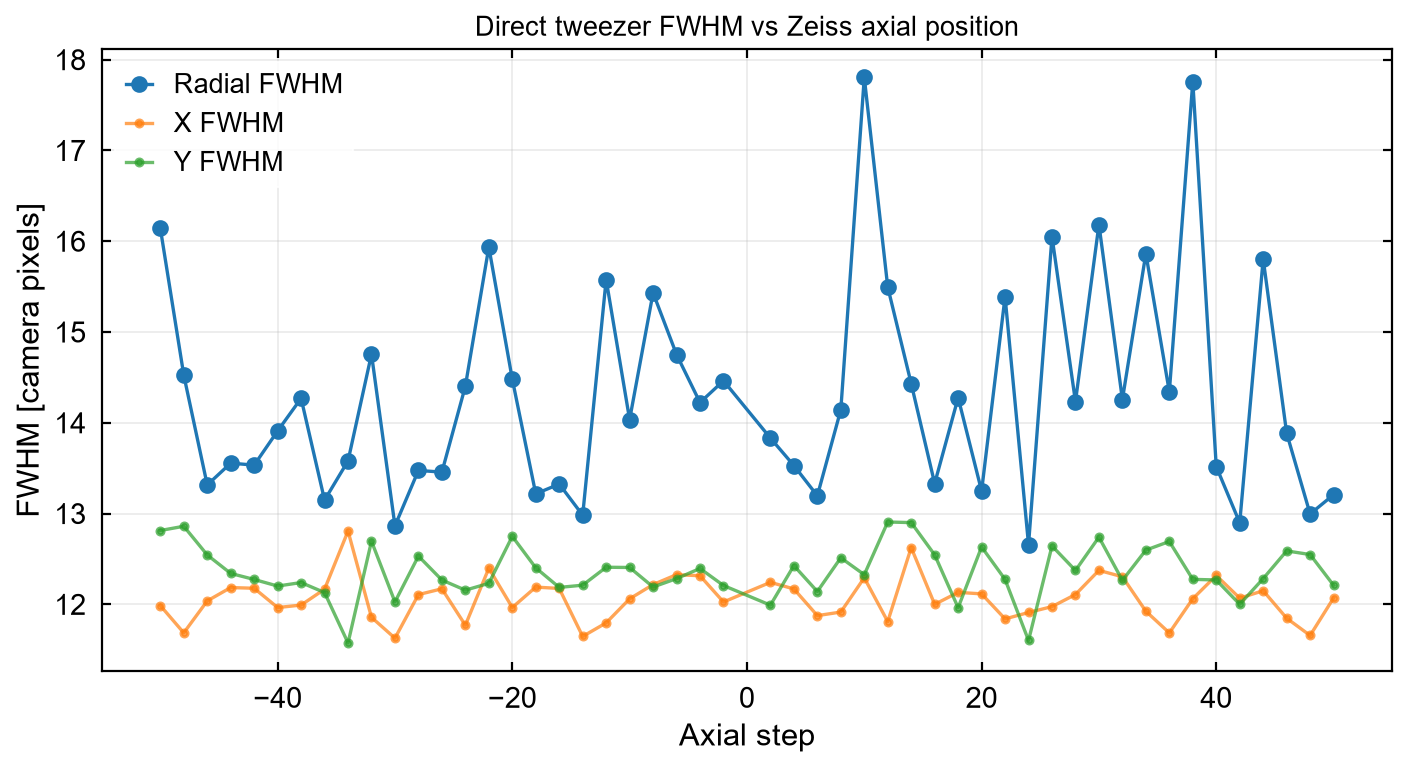

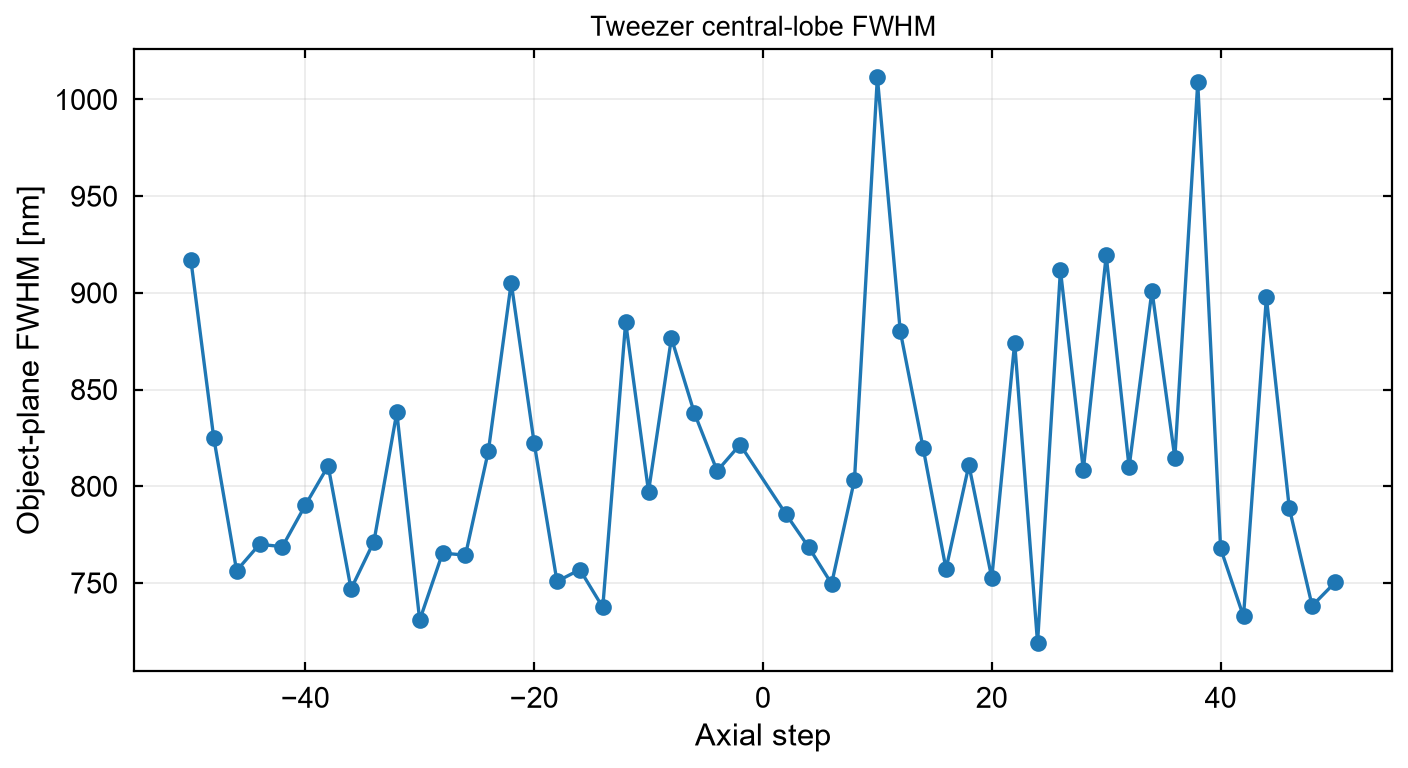

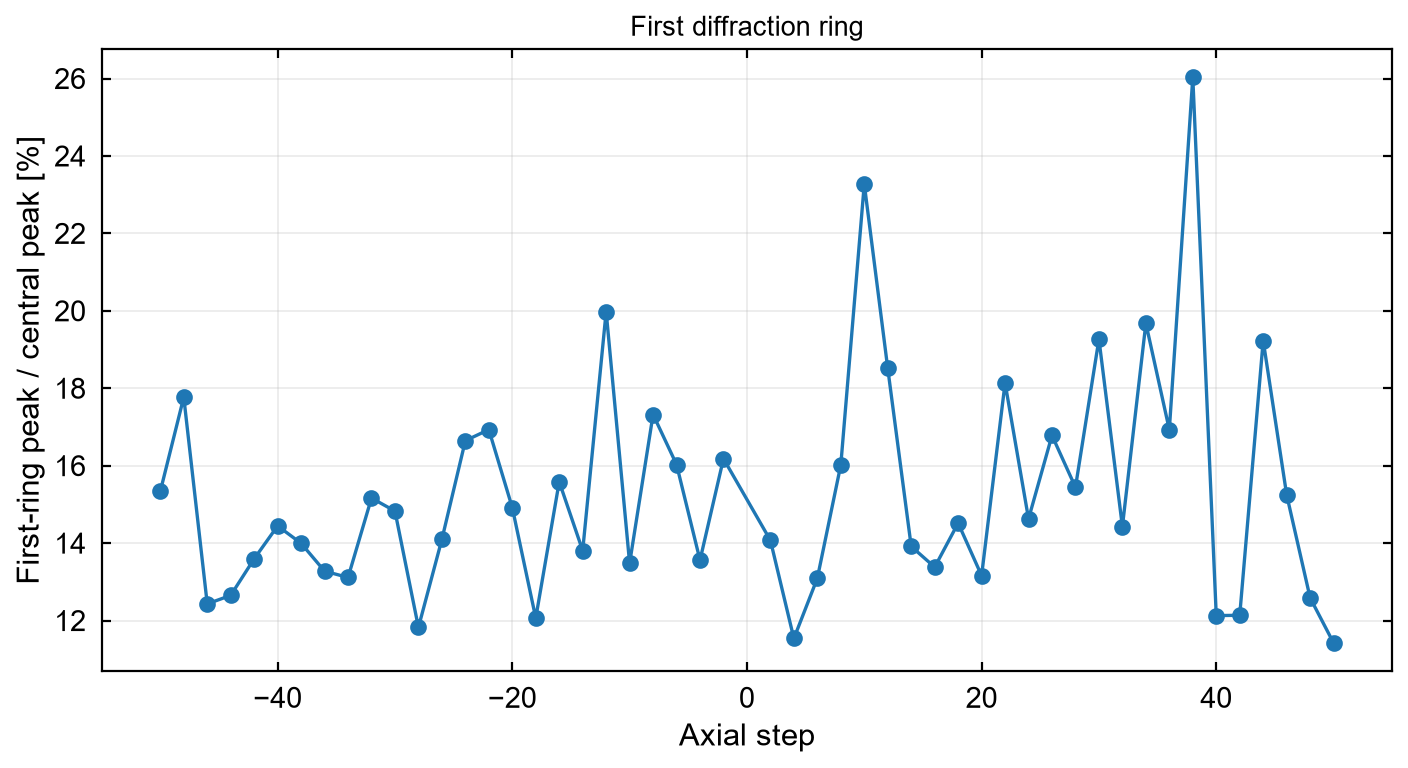

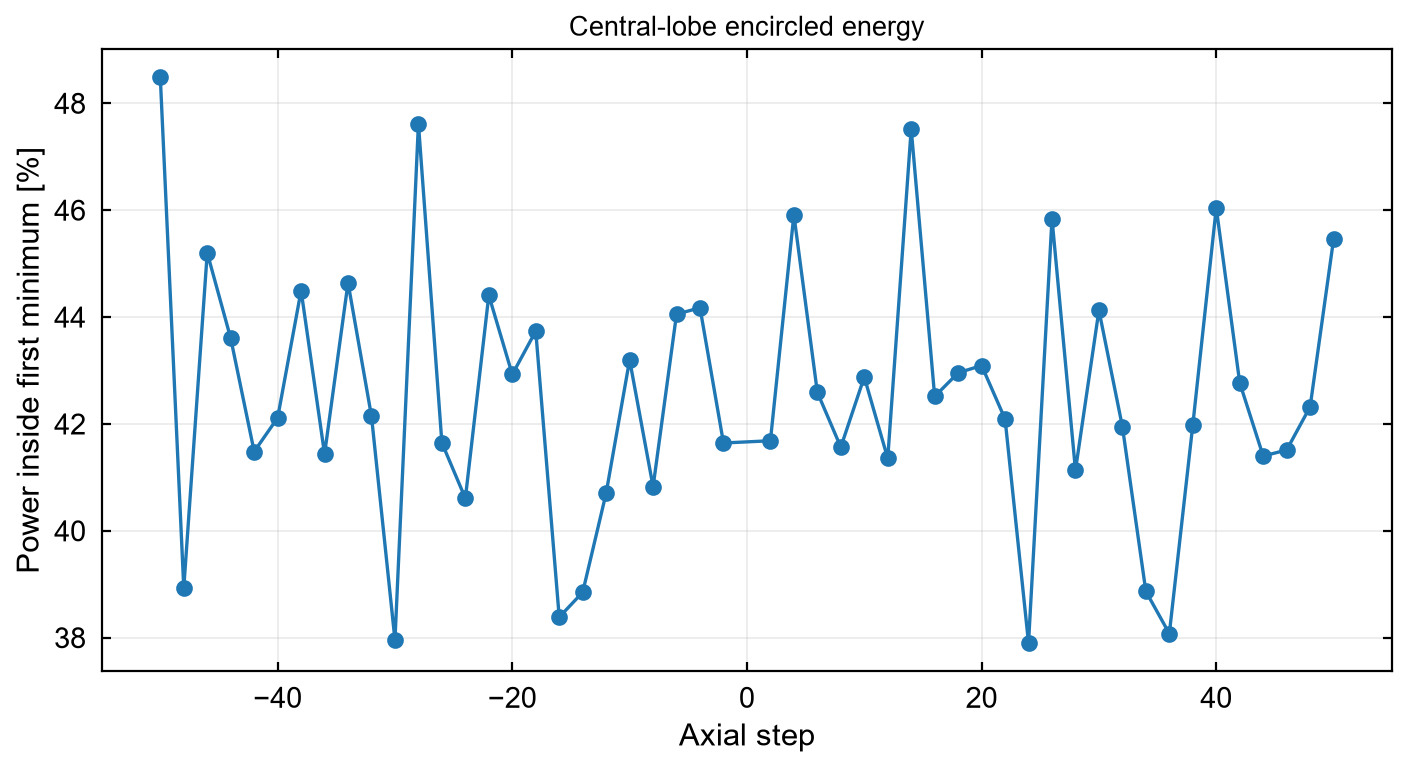

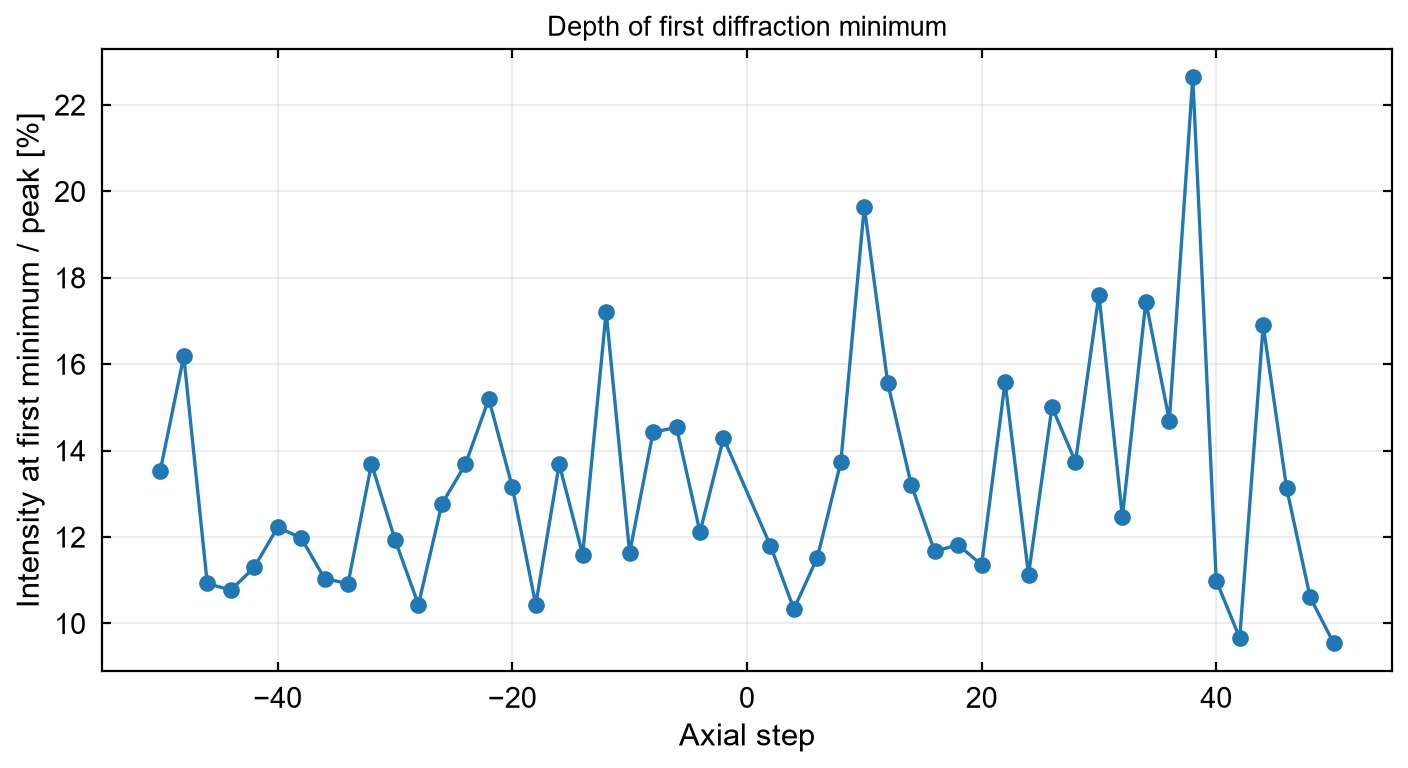

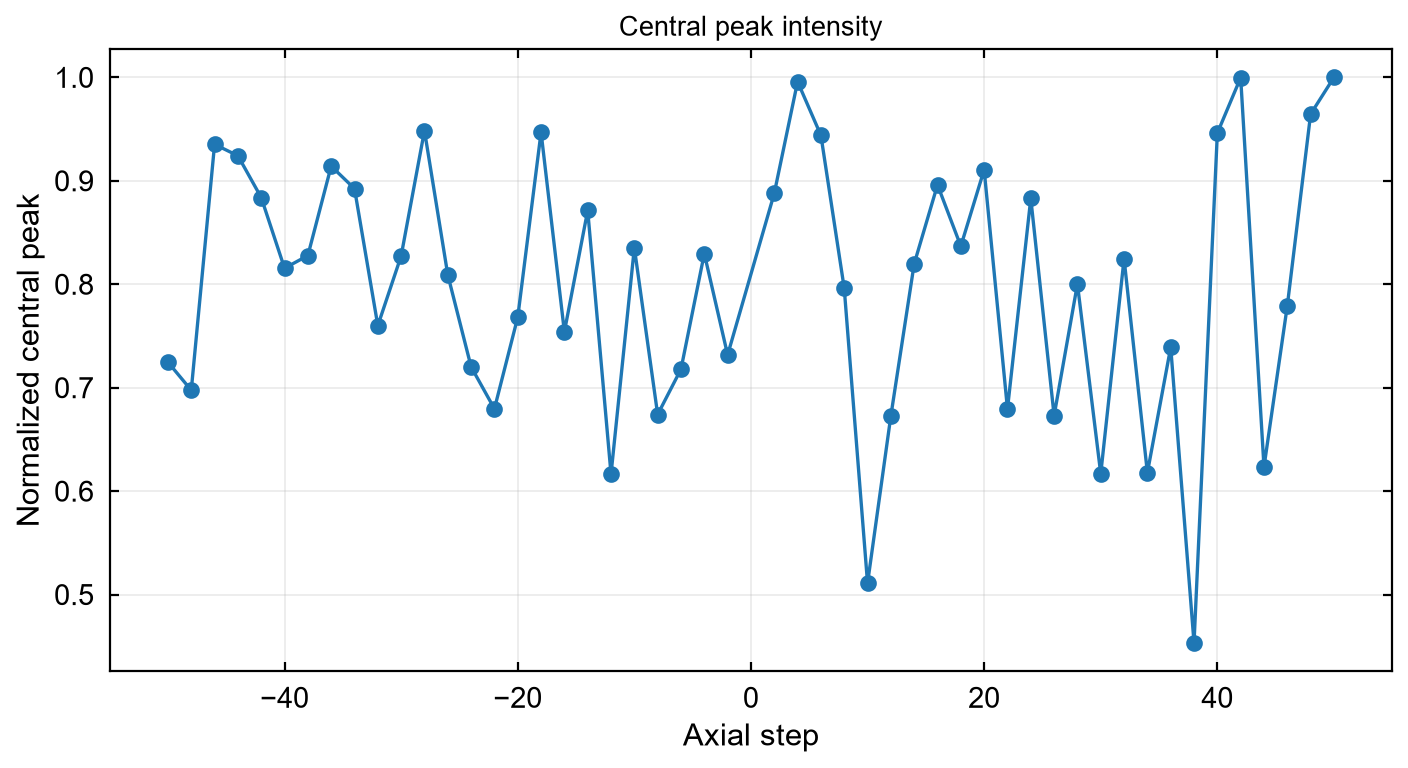

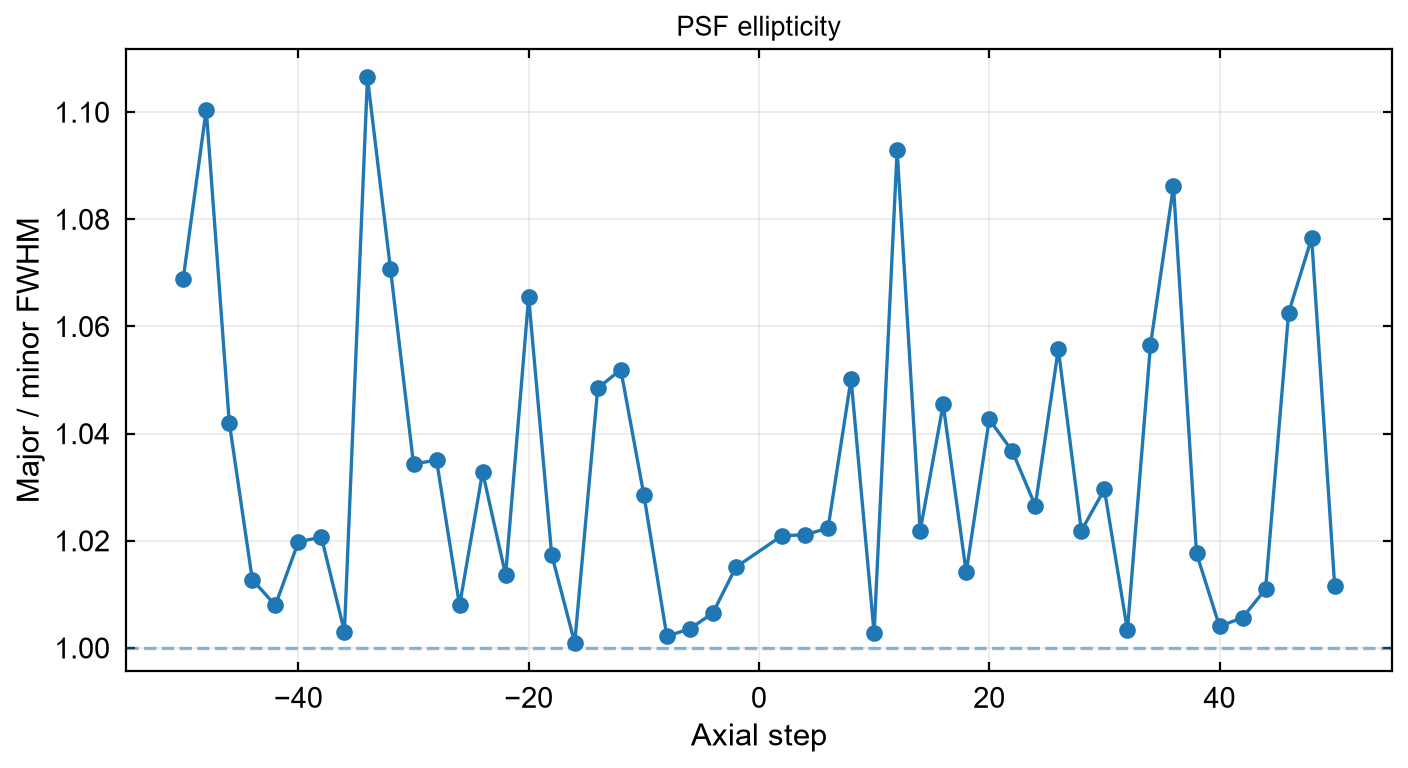

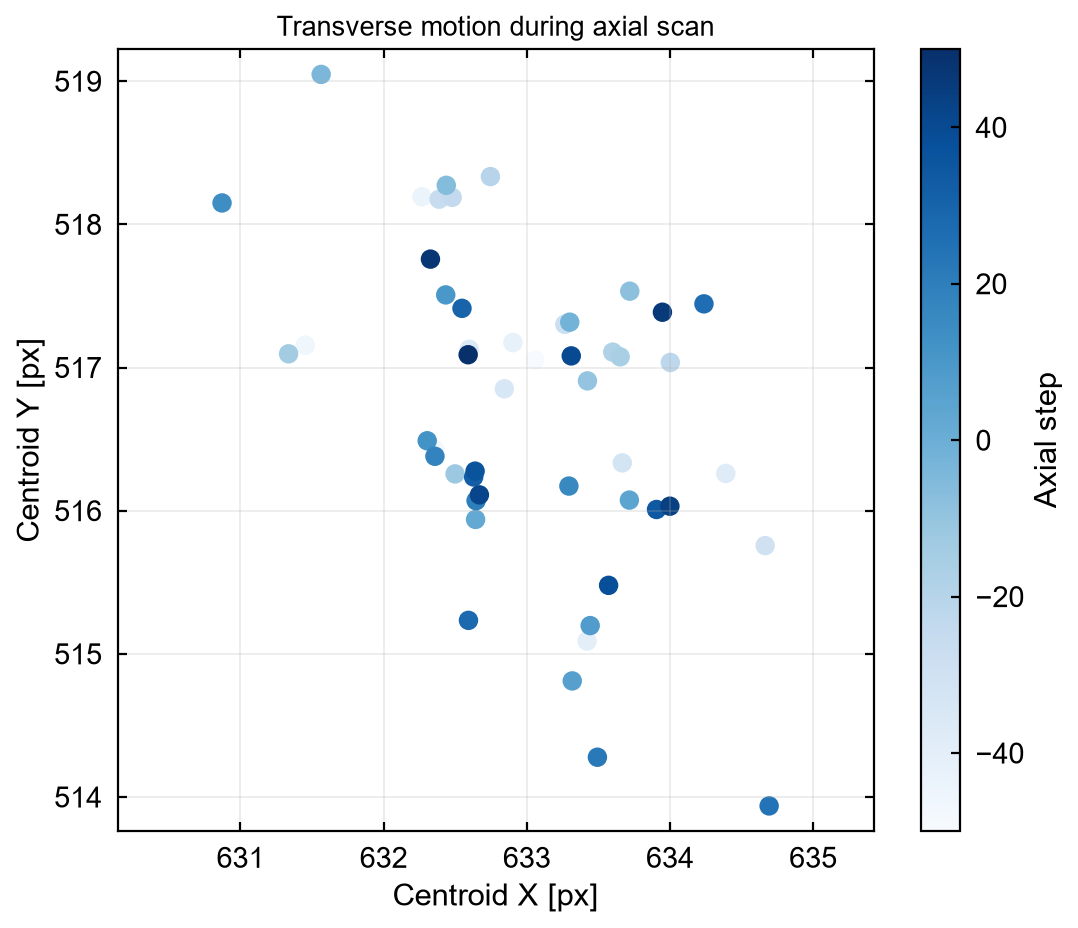

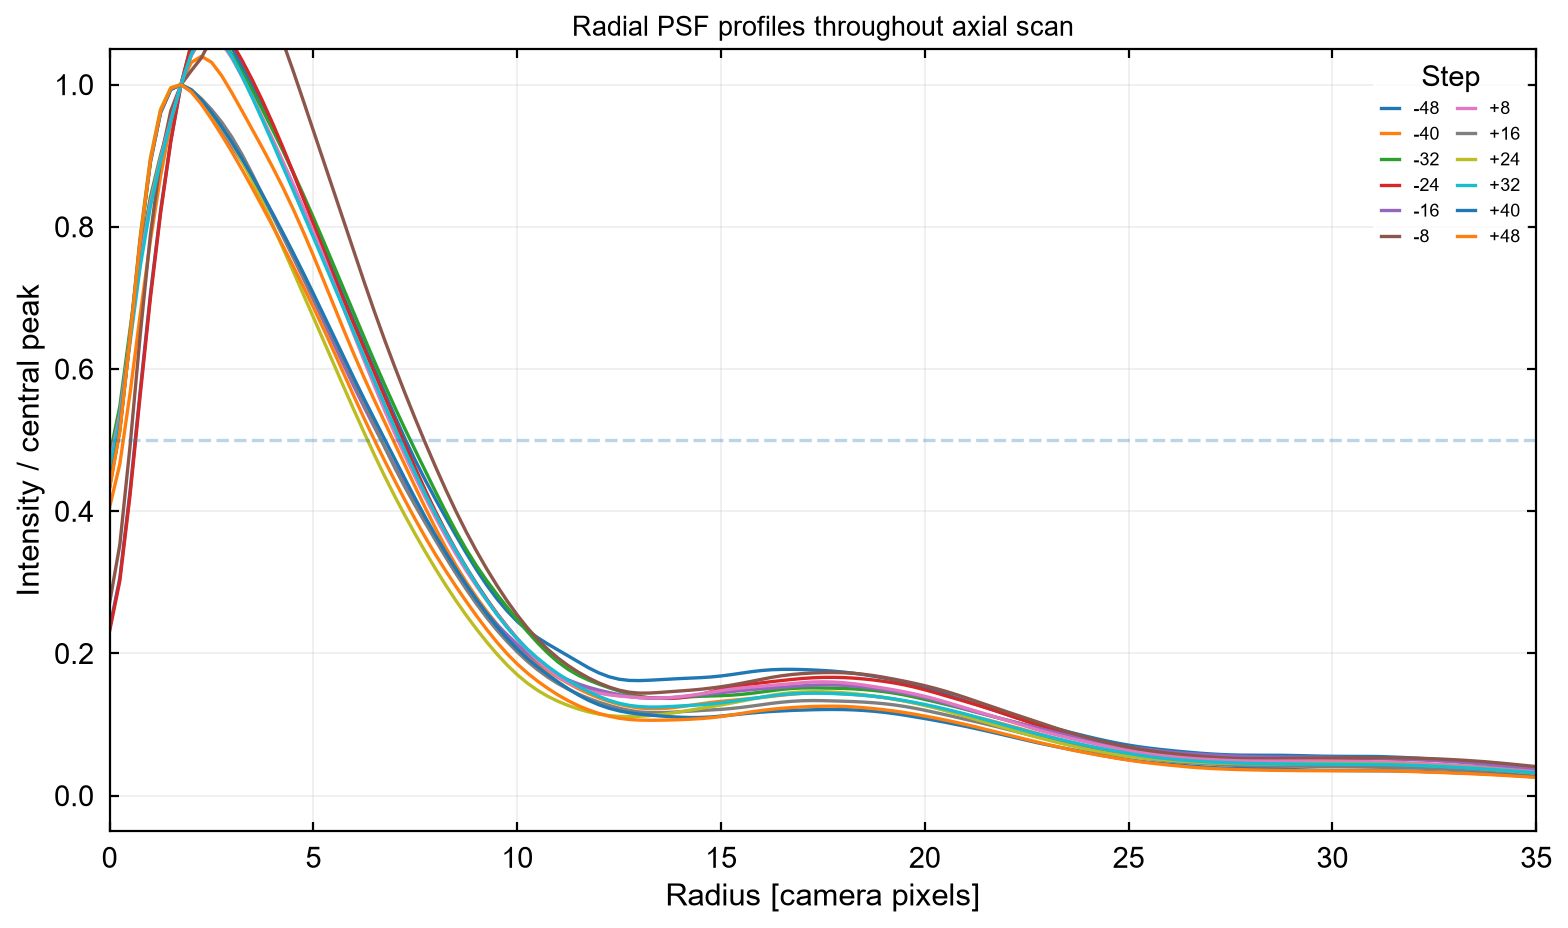

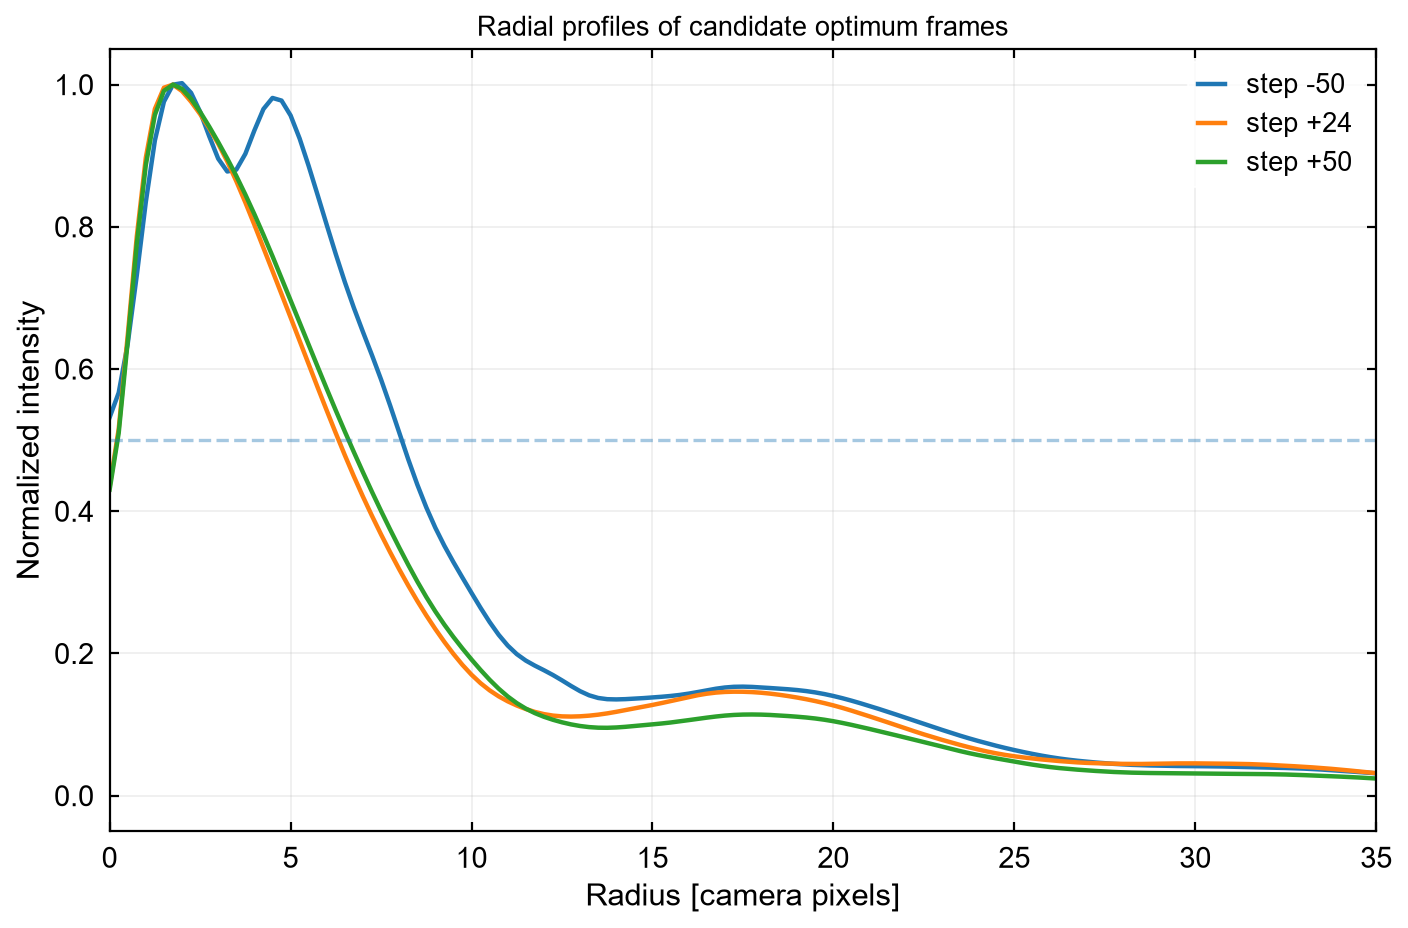


Saved:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data\atom array\axial scan single tweezer\axial_scan_analysis_robust.csv


In [3]:
# ============================================================
# ROBUST AXIAL-SCAN ANALYSIS FOR SINGLE TWEEZER PSF
#
# Designed for Airy / annular diffraction PSFs.
# Does NOT assume a Gaussian spot.
#
# Outputs:
#   - direct radial FWHM
#   - X and Y FWHM
#   - ellipticity
#   - first minimum radius
#   - first ring / central peak
#   - central encircled energy
#   - centroid motion
#   - peak intensity
#   - best axial position
#
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tifffile import imread
from scipy.ndimage import gaussian_filter, gaussian_filter1d
from scipy.signal import find_peaks


# ============================================================
# USER PARAMETERS
# ============================================================

FOLDER = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data\atom array\axial scan single tweezer"
)

CAMERA_PIXEL_UM = 3.45

# Earlier measured:
# M = 182.2x with 300-mm tube lens.
# Current tube lens = 100 mm.
MAGNIFICATION = 182.2 * 100 / 300

OBJECT_PIXEL_NM = (
    CAMERA_PIXEL_UM * 1000 / MAGNIFICATION
)

# Picomotor nominal value.
# Leave only as a nominal conversion.
STEP_NM = 30.0

# Crop half-size around spot.
ROI_HALF_SIZE = 90

# Background annulus in cropped image.
BG_R_IN = 65
BG_R_OUT = 85

# Maximum radius used for PSF total power.
TOTAL_POWER_RADIUS = 60

# Radial bin size.
RADIAL_BIN_WIDTH = 0.25

# Smoothing of radial profile.
RADIAL_SMOOTH_SIGMA_PX = 0.6

# Number of brightest pixels ignored when initially locating peak.
# Usually leave at zero.
SATURATION_THRESHOLD = None


print(f"Magnification = {MAGNIFICATION:.3f}x")
print(f"Object-plane sampling = {OBJECT_PIXEL_NM:.2f} nm/pixel")


# ============================================================
# BASIC HELPERS
# ============================================================

def parse_step(path):
    return int(path.stem)


def crop_around_spot(image, half_size=90):

    img = image.astype(float)

    # Smooth ONLY for finding the center.
    smooth = gaussian_filter(img, sigma=2)

    py, px = np.unravel_index(
        np.argmax(smooth),
        smooth.shape
    )

    y1 = max(0, py - half_size)
    y2 = min(img.shape[0], py + half_size + 1)

    x1 = max(0, px - half_size)
    x2 = min(img.shape[1], px + half_size + 1)

    crop = img[y1:y2, x1:x2]

    return crop, x1, y1


# ============================================================
# SUBPIXEL CENTER
# ============================================================

def weighted_centroid(img):

    # Rough peak.
    smooth = gaussian_filter(img, 1.5)

    py, px = np.unravel_index(
        np.argmax(smooth),
        smooth.shape
    )

    yy, xx = np.indices(img.shape)

    # Use small region around core.
    r = np.sqrt(
        (xx - px)**2 +
        (yy - py)**2
    )

    mask = r < 15

    vals = img[mask]

    # Local background estimate.
    bg = np.percentile(img, 20)

    vals = vals - bg
    vals[vals < 0] = 0

    xx_m = xx[mask]
    yy_m = yy[mask]

    total = np.sum(vals)

    if total <= 0:
        return px, py

    x0 = np.sum(xx_m * vals) / total
    y0 = np.sum(yy_m * vals) / total

    return x0, y0


# ============================================================
# BACKGROUND
# ============================================================

def estimate_background(img, x0, y0):

    yy, xx = np.indices(img.shape)

    r = np.sqrt(
        (xx - x0)**2 +
        (yy - y0)**2
    )

    mask = (
        (r >= BG_R_IN) &
        (r <= BG_R_OUT)
    )

    values = img[mask]

    if len(values) < 20:
        return np.median(img)

    return np.median(values)


# ============================================================
# HIGH-RESOLUTION RADIAL PROFILE
# ============================================================

def radial_profile(
    img,
    x0,
    y0,
    background,
    bin_width=0.25
):

    data = img.astype(float) - background

    yy, xx = np.indices(data.shape)

    r = np.sqrt(
        (xx - x0)**2 +
        (yy - y0)**2
    )

    rmax = np.max(r)

    bins = np.arange(
        0,
        rmax + bin_width,
        bin_width
    )

    indices = np.digitize(
        r.ravel(),
        bins
    )

    radial_sum = np.bincount(
        indices,
        weights=data.ravel(),
        minlength=len(bins) + 1
    )

    radial_count = np.bincount(
        indices,
        minlength=len(bins) + 1
    )

    good = radial_count > 0

    profile = np.zeros_like(
        radial_sum,
        dtype=float
    )

    profile[good] = (
        radial_sum[good] /
        radial_count[good]
    )

    radii = (
        np.arange(len(profile)) *
        bin_width
    )

    return radii, profile


# ============================================================
# INTERPOLATED HALF-MAXIMUM RADIUS
# ============================================================

def interpolate_crossing(x1, y1, x2, y2, target):

    if y2 == y1:
        return 0.5 * (x1 + x2)

    return (
        x1 +
        (target - y1)
        * (x2 - x1)
        / (y2 - y1)
    )


def find_halfmax_radius(r, p):

    peak = np.max(p[r < 2])

    if peak <= 0:
        return np.nan

    pn = p / peak

    # Search outward from center.
    for i in range(1, len(r)):

        if pn[i] <= 0.5 < pn[i - 1]:

            return interpolate_crossing(
                r[i - 1],
                pn[i - 1],
                r[i],
                pn[i],
                0.5
            )

    return np.nan


# ============================================================
# ROBUST FIRST MINIMUM + FIRST RING
# ============================================================

def diffraction_metrics(r, profile):

    # Smooth only slightly.
    smooth = gaussian_filter1d(
        profile,
        RADIAL_SMOOTH_SIGMA_PX / RADIAL_BIN_WIDTH
    )

    # Central peak:
    center_mask = r < 2.0

    peak = np.max(
        smooth[center_mask]
    )

    if peak <= 0:
        return None

    pn = smooth / peak

    # --------------------------------------------------------
    # DIRECT RADIAL FWHM
    # --------------------------------------------------------

    r_half = find_halfmax_radius(
        r,
        smooth
    )

    if not np.isfinite(r_half):
        return None

    radial_fwhm = 2 * r_half

    # --------------------------------------------------------
    # FIRST MINIMUM
    #
    # For an Airy-like PSF, first zero occurs somewhat beyond
    # the half-maximum radius.
    #
    # We therefore search adaptively, rather than using a
    # hard-coded 4...35 px window.
    # --------------------------------------------------------

    search_min = 1.30 * r_half
    search_max = 3.50 * r_half

    mask = (
        (r >= search_min) &
        (r <= search_max)
    )

    if np.sum(mask) < 5:
        return None

    rr = r[mask]
    pp = pn[mask]

    # Candidate local minima.
    local_minima, _ = find_peaks(
        -pp,
        prominence=0.002
    )

    if len(local_minima) > 0:

        # Use FIRST physically reasonable minimum.
        idx_min_local = local_minima[0]

    else:

        # Fallback: absolute minimum in search region.
        idx_min_local = np.argmin(pp)

    r_min = rr[idx_min_local]
    I_min = pp[idx_min_local]

    # --------------------------------------------------------
    # FIRST RING
    # --------------------------------------------------------

    ring_search_min = r_min + 0.5
    ring_search_max = r_min + 2.5 * r_half

    ring_mask = (
        (r >= ring_search_min) &
        (r <= ring_search_max)
    )

    rr_ring = r[ring_mask]
    pp_ring = pn[ring_mask]

    if len(pp_ring) < 3:
        return None

    ring_peaks, _ = find_peaks(
        pp_ring,
        prominence=0.001
    )

    if len(ring_peaks) > 0:

        ring_idx = ring_peaks[0]

    else:

        ring_idx = np.argmax(
            pp_ring
        )

    r_ring = rr_ring[ring_idx]
    ring_fraction = pp_ring[ring_idx]

    return {

        "peak": peak,

        "r_half_px":
            r_half,

        "fwhm_radial_px":
            radial_fwhm,

        "first_minimum_px":
            r_min,

        "minimum_fraction":
            I_min,

        "ring_radius_px":
            r_ring,

        "ring_peak_fraction":
            ring_fraction,

        "radial_r":
            r,

        "radial_profile":
            pn
    }


# ============================================================
# ENCIRCLED ENERGY
# ============================================================

def encircled_energy(
    img,
    x0,
    y0,
    background,
    central_radius,
    total_radius
):

    data = img.astype(float) - background

    # Negative background noise should not subtract energy.
    data[data < 0] = 0

    yy, xx = np.indices(
        data.shape
    )

    r = np.sqrt(
        (xx - x0)**2 +
        (yy - y0)**2
    )

    central = r <= central_radius
    total = r <= total_radius

    Pcentral = np.sum(
        data[central]
    )

    Ptotal = np.sum(
        data[total]
    )

    if Ptotal <= 0:
        return np.nan

    return Pcentral / Ptotal


# ============================================================
# X/Y DIRECT FWHM
# ============================================================

def direct_cut_fwhm(img, x0, y0, background):

    data = img.astype(float) - background

    # Bilinear-ish simple interpolation:
    # average a few rows/columns near centroid.

    xi = int(round(x0))
    yi = int(round(y0))

    ylo = max(0, yi - 1)
    yhi = min(data.shape[0], yi + 2)

    xlo = max(0, xi - 1)
    xhi = min(data.shape[1], xi + 2)

    xcut = np.mean(
        data[ylo:yhi, :],
        axis=0
    )

    ycut = np.mean(
        data[:, xlo:xhi],
        axis=1
    )

    def get_fwhm(cut, center):

        cut = gaussian_filter1d(
            cut,
            sigma=0.6
        )

        peak = np.max(
            cut[
                max(0, int(center) - 3):
                min(len(cut), int(center) + 4)
            ]
        )

        half = peak / 2

        c = int(round(center))

        # LEFT crossing
        left = np.nan

        for i in range(c, 0, -1):

            if (
                cut[i] >= half and
                cut[i - 1] < half
            ):

                left = interpolate_crossing(
                    i - 1,
                    cut[i - 1],
                    i,
                    cut[i],
                    half
                )

                break

        # RIGHT crossing
        right = np.nan

        for i in range(c, len(cut) - 1):

            if (
                cut[i] >= half and
                cut[i + 1] < half
            ):

                right = interpolate_crossing(
                    i,
                    cut[i],
                    i + 1,
                    cut[i + 1],
                    half
                )

                break

        if (
            np.isfinite(left) and
            np.isfinite(right)
        ):
            return right - left

        return np.nan

    fx = get_fwhm(
        xcut,
        x0
    )

    fy = get_fwhm(
        ycut,
        y0
    )

    return fx, fy


# ============================================================
# LOAD ALL IMAGES
# ============================================================

files = sorted(
    FOLDER.glob("*.tif"),
    key=parse_step
)

print()
print(f"Found {len(files)} TIFF images.")

if len(files) == 0:
    raise RuntimeError(
        "No TIFF files found."
    )


# ============================================================
# ANALYZE
# ============================================================

results = []

profiles = {}

for file in files:

    step = parse_step(file)

    image = imread(file)

    image = np.squeeze(image).astype(float)

    crop, x_offset, y_offset = crop_around_spot(
        image,
        ROI_HALF_SIZE
    )

    # --------------------------------------------------------
    # CENTER
    # --------------------------------------------------------

    x0, y0 = weighted_centroid(
        crop
    )

    # --------------------------------------------------------
    # BACKGROUND
    # --------------------------------------------------------

    background = estimate_background(
        crop,
        x0,
        y0
    )

    # --------------------------------------------------------
    # RADIAL PROFILE
    # --------------------------------------------------------

    r, profile = radial_profile(
        crop,
        x0,
        y0,
        background
    )

    metrics = diffraction_metrics(
        r,
        profile
    )

    if metrics is None:

        print(
            f"Could not analyze {file.name}"
        )

        continue

    # --------------------------------------------------------
    # CENTRAL ENERGY
    # --------------------------------------------------------

    central_energy = encircled_energy(

        crop,

        x0,
        y0,

        background,

        metrics["first_minimum_px"],

        TOTAL_POWER_RADIUS
    )

    # --------------------------------------------------------
    # X/Y FWHM
    # --------------------------------------------------------

    fwhm_x, fwhm_y = direct_cut_fwhm(
        crop,
        x0,
        y0,
        background
    )

    if (
        np.isfinite(fwhm_x) and
        np.isfinite(fwhm_y)
    ):

        ellipticity = (
            max(fwhm_x, fwhm_y) /
            min(fwhm_x, fwhm_y)
        )

    else:

        ellipticity = np.nan

    # --------------------------------------------------------
    # STORE
    # --------------------------------------------------------

    results.append({

        "step":
            step,

        "z_nominal_um":
            step * STEP_NM / 1000,

        "x_centroid_px":
            x0 + x_offset,

        "y_centroid_px":
            y0 + y_offset,

        "fwhm_radial_px":
            metrics["fwhm_radial_px"],

        "fwhm_radial_nm":
            metrics["fwhm_radial_px"]
            * OBJECT_PIXEL_NM,

        "fwhm_x_px":
            fwhm_x,

        "fwhm_y_px":
            fwhm_y,

        "ellipticity":
            ellipticity,

        "first_minimum_px":
            metrics["first_minimum_px"],

        "minimum_fraction":
            metrics["minimum_fraction"],

        "ring_radius_px":
            metrics["ring_radius_px"],

        "ring_peak_fraction":
            metrics["ring_peak_fraction"],

        "central_energy_fraction":
            central_energy,

        "peak":
            metrics["peak"],

        "background":
            background,

        "filename":
            file.name
    })

    profiles[step] = (
        metrics["radial_r"],
        metrics["radial_profile"]
    )


df = (
    pd.DataFrame(results)
    .sort_values("step")
    .reset_index(drop=True)
)


# ============================================================
# NORMALIZE PEAK
# ============================================================

df["peak_normalized"] = (
    df["peak"] /
    df["peak"].max()
)


# ============================================================
# SIMPLE QUALITY METRICS
# ============================================================

best_fwhm = df.loc[
    df["fwhm_radial_px"].idxmin()
]

best_ring = df.loc[
    df["ring_peak_fraction"].idxmin()
]

best_energy = df.loc[
    df["central_energy_fraction"].idxmax()
]

best_peak = df.loc[
    df["peak"].idxmax()
]


# ============================================================
# PRINT SUMMARY
# ============================================================

print()
print("=" * 72)
print("AXIAL SCAN SUMMARY")
print("=" * 72)

print()
print("SMALLEST RADIAL FWHM")
print("--------------------")
print(
    f"step             = {best_fwhm['step']:+.0f}"
)
print(
    f"FWHM             = {best_fwhm['fwhm_radial_px']:.2f} px"
)
print(
    f"                  {best_fwhm['fwhm_radial_nm']:.0f} nm"
)
print(
    f"ring / peak      = {100*best_fwhm['ring_peak_fraction']:.2f} %"
)
print(
    f"central energy   = {100*best_fwhm['central_energy_fraction']:.2f} %"
)


print()
print("LOWEST FIRST RING")
print("-----------------")
print(
    f"step             = {best_ring['step']:+.0f}"
)
print(
    f"ring / peak      = {100*best_ring['ring_peak_fraction']:.2f} %"
)
print(
    f"FWHM             = {best_ring['fwhm_radial_px']:.2f} px"
)
print(
    f"central energy   = {100*best_ring['central_energy_fraction']:.2f} %"
)


print()
print("HIGHEST CENTRAL ENERGY")
print("----------------------")
print(
    f"step             = {best_energy['step']:+.0f}"
)
print(
    f"central energy   = {100*best_energy['central_energy_fraction']:.2f} %"
)
print(
    f"ring / peak      = {100*best_energy['ring_peak_fraction']:.2f} %"
)
print(
    f"FWHM             = {best_energy['fwhm_radial_px']:.2f} px"
)


print()
print("HIGHEST CENTRAL PEAK")
print("--------------------")
print(
    f"step             = {best_peak['step']:+.0f}"
)
print(
    f"FWHM             = {best_peak['fwhm_radial_px']:.2f} px"
)
print(
    f"ring / peak      = {100*best_peak['ring_peak_fraction']:.2f} %"
)


# ============================================================
# TABLE
# ============================================================

cols = [

    "step",

    "fwhm_radial_px",
    "fwhm_radial_nm",

    "fwhm_x_px",
    "fwhm_y_px",

    "ellipticity",

    "first_minimum_px",

    "ring_peak_fraction",

    "central_energy_fraction",

    "peak_normalized"
]

display(
    df[cols].round(4)
)


# ============================================================
# PLOT 1 — DIRECT FWHM
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    df["step"],
    df["fwhm_radial_px"],
    "o-",
    label="Radial FWHM"
)

plt.plot(
    df["step"],
    df["fwhm_x_px"],
    ".-",
    alpha=0.7,
    label="X FWHM"
)

plt.plot(
    df["step"],
    df["fwhm_y_px"],
    ".-",
    alpha=0.7,
    label="Y FWHM"
)

plt.xlabel("Axial step")
plt.ylabel("FWHM [camera pixels]")

plt.title(
    "Direct tweezer FWHM vs Zeiss axial position"
)

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2 — OBJECT-PLANE FWHM
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    df["step"],
    df["fwhm_radial_nm"],
    "o-"
)

plt.xlabel("Axial step")
plt.ylabel("Object-plane FWHM [nm]")

plt.title(
    "Tweezer central-lobe FWHM"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 3 — FIRST RING
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    df["step"],
    100 * df["ring_peak_fraction"],
    "o-"
)

plt.xlabel("Axial step")
plt.ylabel(
    "First-ring peak / central peak [%]"
)

plt.title(
    "First diffraction ring"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 4 — CENTRAL ENCIRCLED ENERGY
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    df["step"],
    100 * df["central_energy_fraction"],
    "o-"
)

plt.xlabel("Axial step")

plt.ylabel(
    "Power inside first minimum [%]"
)

plt.title(
    "Central-lobe encircled energy"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 5 — FIRST MINIMUM DEPTH
#
# A good diffraction pattern should have a deep first minimum.
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    df["step"],
    100 * df["minimum_fraction"],
    "o-"
)

plt.xlabel("Axial step")

plt.ylabel(
    "Intensity at first minimum / peak [%]"
)

plt.title(
    "Depth of first diffraction minimum"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 6 — NORMALIZED PEAK
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    df["step"],
    df["peak_normalized"],
    "o-"
)

plt.xlabel("Axial step")
plt.ylabel("Normalized central peak")

plt.title(
    "Central peak intensity"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 7 — ELLIPTICITY
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    df["step"],
    df["ellipticity"],
    "o-"
)

plt.axhline(
    1.0,
    linestyle="--",
    alpha=0.5
)

plt.xlabel("Axial step")
plt.ylabel("Major / minor FWHM")

plt.title(
    "PSF ellipticity"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 8 — CENTROID MOTION
# ============================================================

plt.figure(figsize=(7, 6))

sc = plt.scatter(
    df["x_centroid_px"],
    df["y_centroid_px"],
    c=df["step"],
    s=60
)

plt.colorbar(
    sc,
    label="Axial step"
)

plt.xlabel("Centroid X [px]")
plt.ylabel("Centroid Y [px]")

plt.title(
    "Transverse motion during axial scan"
)

plt.axis("equal")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 9 — RADIAL PROFILES
#
# This is VERY IMPORTANT.
#
# It lets you visually verify that the automatic first minimum
# and first-ring finding makes sense.
# ============================================================

plt.figure(figsize=(10, 6))

for step in sorted(profiles.keys()):

    r, p = profiles[step]

    # Don't plot every single profile at full opacity.
    # Highlight every 4th step approximately.

    if step % 8 == 0:

        mask = r <= 35

        plt.plot(
            r[mask],
            p[mask],
            label=f"{step:+d}"
        )

plt.axhline(
    0.5,
    linestyle="--",
    alpha=0.3
)

plt.xlabel("Radius [camera pixels]")
plt.ylabel("Intensity / central peak")

plt.title(
    "Radial PSF profiles throughout axial scan"
)

plt.ylim(-0.05, 1.05)
plt.xlim(0, 35)

plt.grid(alpha=0.2)

plt.legend(
    title="Step",
    ncol=2,
    fontsize=8
)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 10 — BEST FEW RADIAL PROFILES
# ============================================================

candidate_steps = sorted(
    set([
        int(best_fwhm["step"]),
        int(best_ring["step"]),
        int(best_energy["step"]),
        int(best_peak["step"])
    ])
)

plt.figure(figsize=(9, 6))

for step in candidate_steps:

    r, p = profiles[step]

    mask = r <= 35

    plt.plot(
        r[mask],
        p[mask],
        linewidth=2,
        label=f"step {step:+d}"
    )

plt.axhline(
    0.5,
    linestyle="--",
    alpha=0.4
)

plt.xlabel("Radius [camera pixels]")
plt.ylabel("Normalized intensity")

plt.title(
    "Radial profiles of candidate optimum frames"
)

plt.xlim(0, 35)
plt.ylim(-0.05, 1.05)

plt.grid(alpha=0.2)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# SAVE
# ============================================================

output = FOLDER / "axial_scan_analysis_robust.csv"

df.to_csv(
    output,
    index=False
)

print()
print(f"Saved:")
print(output)

Magnification       = 60.733x
Object pixel size   = 56.806 nm/px

Centroid X = 632.590 camera px
Centroid Y = 517.089 camera px
Background = 1.000

PSF RESULTS
FWHM X              = 12.07 px = 686 nm
FWHM Y              = 12.21 px = 694 nm
Geometric FWHM      = 12.14 px = 690 nm
Ellipticity         = 1.0116
First minimum       = 13.75 px
I_min / I_peak      = 9.25 %
First ring radius   = 17.75 px
I_ring / I_peak     = 10.89 %
Central energy      = 45.46 %   (total radius = 60 px)


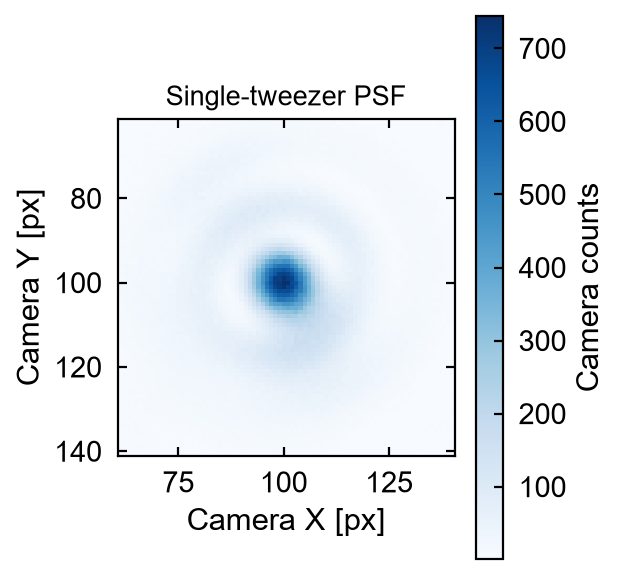

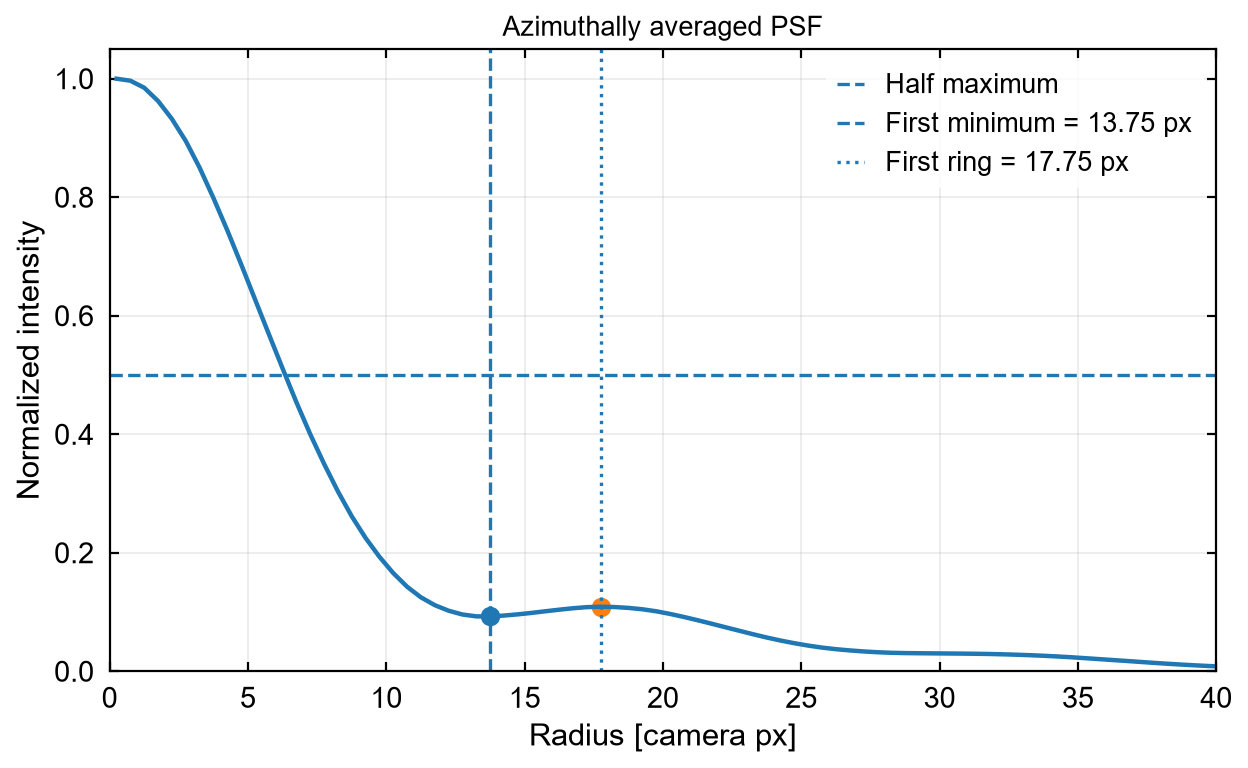

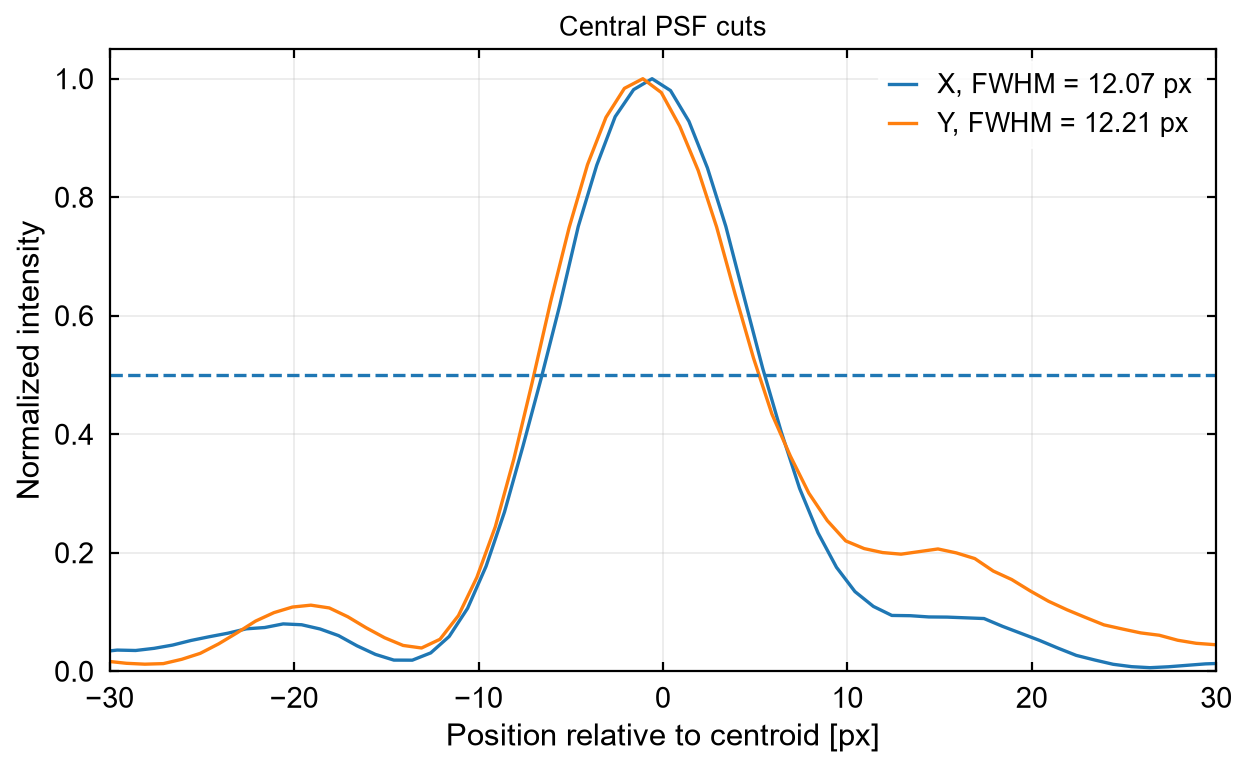

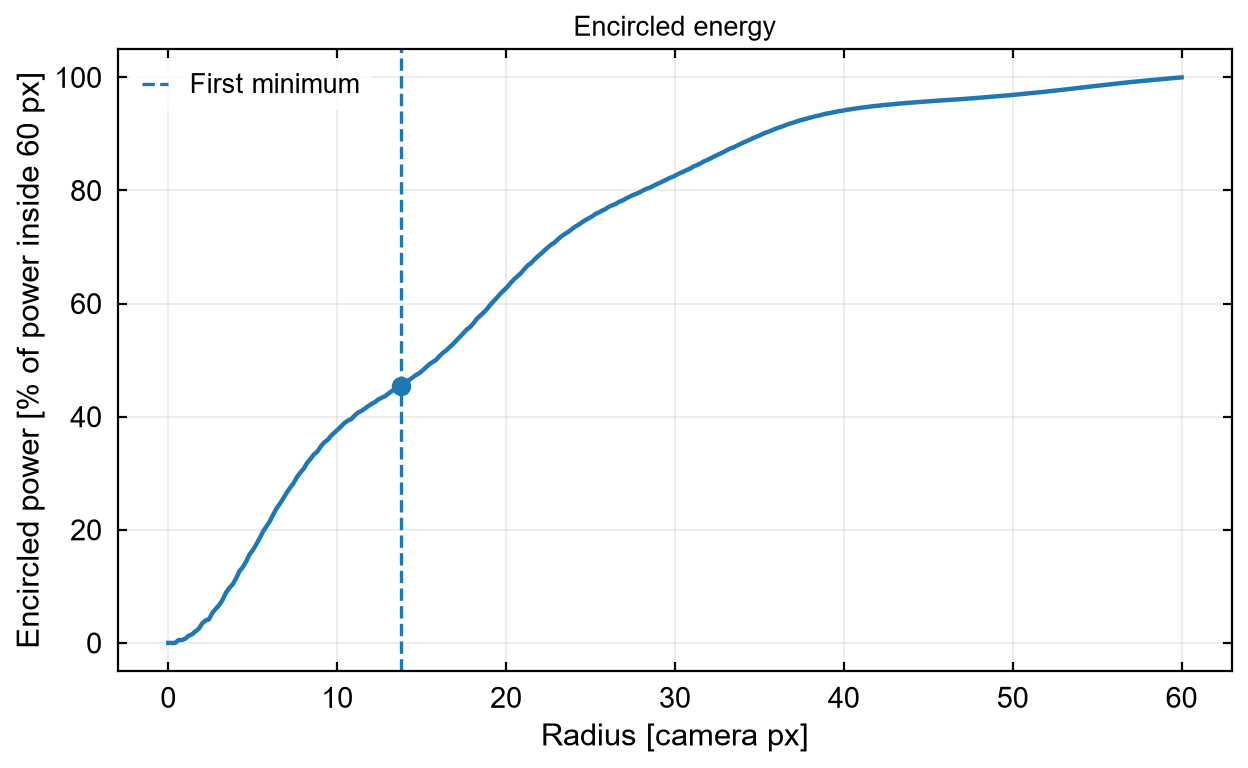

C:\Users\admin\AppData\Local\Temp\ipykernel_10152\3790020463.py:820: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(


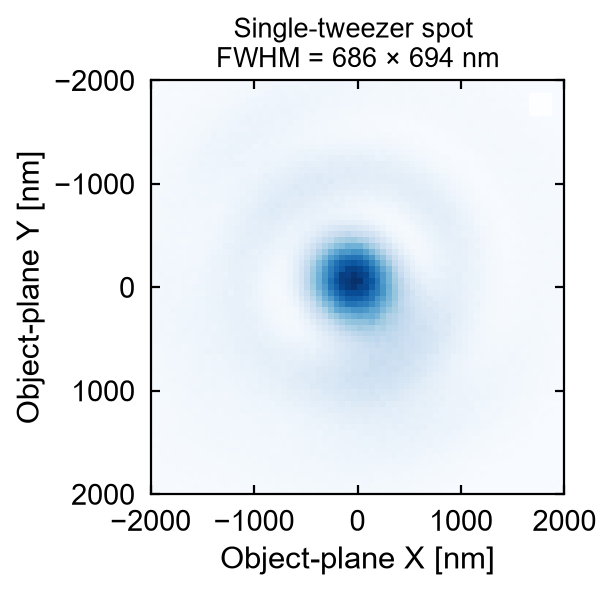

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from tifffile import imread
from scipy.ndimage import gaussian_filter, gaussian_filter1d
from scipy.signal import find_peaks


# ============================================================
# FILE
# ============================================================

FILE = r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data\atom array\axial scan single tweezer\50.tif"

# Camera / imaging calibration
CAMERA_PIXEL_UM = 3.45

# Your previous calibration:
# 182.2x with 300-mm tube lens
# current tube lens = 100 mm
MAGNIFICATION = 182.2 * 100 / 300

OBJECT_PIXEL_NM = CAMERA_PIXEL_UM * 1000 / MAGNIFICATION

print(f"Magnification       = {MAGNIFICATION:.3f}x")
print(f"Object pixel size   = {OBJECT_PIXEL_NM:.3f} nm/px")


# ============================================================
# LOAD IMAGE
# ============================================================

image = np.squeeze(imread(FILE)).astype(float)


# ============================================================
# LOCATE SPOT AND CROP
# ============================================================

smooth = gaussian_filter(image, sigma=2)

py, px = np.unravel_index(
    np.argmax(smooth),
    smooth.shape
)

HALF_SIZE = 100

y1 = max(0, py - HALF_SIZE)
y2 = min(image.shape[0], py + HALF_SIZE + 1)

x1 = max(0, px - HALF_SIZE)
x2 = min(image.shape[1], px + HALF_SIZE + 1)

crop = image[y1:y2, x1:x2]

yy, xx = np.indices(crop.shape)


# ============================================================
# SUBPIXEL CENTROID
# ============================================================

smooth_crop = gaussian_filter(crop, 1.5)

pcy, pcx = np.unravel_index(
    np.argmax(smooth_crop),
    smooth_crop.shape
)

r0 = np.sqrt(
    (xx - pcx)**2 +
    (yy - pcy)**2
)

# Estimate background from outer annulus
bg_mask = (r0 >= 70) & (r0 <= 90)

background = np.median(
    crop[bg_mask]
)

data = crop - background


# Weighted centroid using central 15-px region
centroid_mask = r0 < 15

weights = np.clip(
    data[centroid_mask],
    0,
    None
)

x0 = np.sum(
    xx[centroid_mask] * weights
) / np.sum(weights)

y0 = np.sum(
    yy[centroid_mask] * weights
) / np.sum(weights)


print()
print(f"Centroid X = {x0 + x1:.3f} camera px")
print(f"Centroid Y = {y0 + y1:.3f} camera px")
print(f"Background = {background:.3f}")


# ============================================================
# HELPER FOR INTERPOLATED CROSSING
# ============================================================

def interpolate_crossing(x1, y1, x2, y2, target):

    if y2 == y1:
        return (x1 + x2) / 2

    return (
        x1
        + (target - y1)
        * (x2 - x1)
        / (y2 - y1)
    )


# ============================================================
# DIRECT X/Y FWHM
# ============================================================

yi = int(round(y0))
xi = int(round(x0))

# Average 3 rows / columns to reduce pixel noise
xcut = np.mean(
    data[yi-1:yi+2, :],
    axis=0
)

ycut = np.mean(
    data[:, xi-1:xi+2],
    axis=1
)


def get_fwhm(cut, center):

    cut = gaussian_filter1d(
        cut,
        sigma=0.6
    )

    c = int(round(center))

    peak = np.max(
        cut[c-4:c+5]
    )

    half = peak / 2

    left = np.nan
    right = np.nan

    # Left crossing
    for i in range(c, 0, -1):

        if (
            cut[i] >= half
            and cut[i-1] < half
        ):

            left = interpolate_crossing(
                i-1,
                cut[i-1],
                i,
                cut[i],
                half
            )

            break

    # Right crossing
    for i in range(c, len(cut)-1):

        if (
            cut[i] >= half
            and cut[i+1] < half
        ):

            right = interpolate_crossing(
                i,
                cut[i],
                i+1,
                cut[i+1],
                half
            )

            break

    return (
        right-left,
        peak,
        half,
        left,
        right,
        cut
    )


(
    fwhm_x,
    peak_x,
    half_x,
    left_x,
    right_x,
    xcut_s
) = get_fwhm(xcut, x0)


(
    fwhm_y,
    peak_y,
    half_y,
    left_y,
    right_y,
    ycut_s
) = get_fwhm(ycut, y0)


fwhm_geo = np.sqrt(
    fwhm_x * fwhm_y
)

ellipticity = (
    max(fwhm_x, fwhm_y)
    /
    min(fwhm_x, fwhm_y)
)


# ============================================================
# RADIAL PROFILE
# ============================================================

rr = np.sqrt(
    (xx - x0)**2 +
    (yy - y0)**2
)


BIN_WIDTH = 0.5
RMAX = 60

edges = np.arange(
    0,
    RMAX + BIN_WIDTH,
    BIN_WIDTH
)

indices = np.digitize(
    rr.ravel(),
    edges
) - 1

nbins = len(edges) - 1

radial_sum = np.bincount(
    indices,
    weights=data.ravel(),
    minlength=nbins
)[:nbins]

radial_count = np.bincount(
    indices,
    minlength=nbins
)[:nbins]

radial = np.full(
    nbins,
    np.nan
)

good = radial_count > 0

radial[good] = (
    radial_sum[good]
    /
    radial_count[good]
)

r = 0.5 * (
    edges[:-1] +
    edges[1:]
)

# interpolate empty fine bins
valid = np.isfinite(radial)

radial = np.interp(
    r,
    r[valid],
    radial[valid]
)

radial = gaussian_filter1d(
    radial,
    sigma=0.75 / BIN_WIDTH
)


# Normalize
peak_radial = np.max(
    radial[r < 2.5]
)

radial_norm = (
    radial / peak_radial
)


# ============================================================
# RADIAL HALF MAXIMUM
# ============================================================

r_half = np.nan

for i in range(len(r)-1):

    if (
        radial_norm[i] >= 0.5
        and radial_norm[i+1] < 0.5
    ):

        r_half = interpolate_crossing(
            r[i],
            radial_norm[i],
            r[i+1],
            radial_norm[i+1],
            0.5
        )

        break


# ============================================================
# FIRST MINIMUM
# ============================================================

search = (
    (r >= 1.3*r_half)
    &
    (r <= 3.5*r_half)
)

rr_search = r[search]
pp_search = radial_norm[search]

mins, _ = find_peaks(
    -pp_search,
    prominence=0.002
)

if len(mins):

    imin = mins[0]

else:

    imin = np.argmin(
        pp_search
    )


r_min = rr_search[imin]

minimum_fraction = (
    pp_search[imin]
)


# ============================================================
# FIRST RING PEAK
# ============================================================

ring_search = (
    (r >= r_min + 0.5)
    &
    (r <= r_min + 2.5*r_half)
)

rr_ring = r[ring_search]
pp_ring = radial_norm[ring_search]

peaks, _ = find_peaks(
    pp_ring,
    prominence=0.001
)

if len(peaks):

    iring = peaks[0]

else:

    iring = np.argmax(
        pp_ring
    )


r_ring = rr_ring[iring]

ring_fraction = (
    pp_ring[iring]
)


# ============================================================
# ENCIRCLED ENERGY
# ============================================================

positive_data = np.clip(
    data,
    0,
    None
)

central_power = np.sum(
    positive_data[rr <= r_min]
)

TOTAL_RADIUS = 60

total_power = np.sum(
    positive_data[rr <= TOTAL_RADIUS]
)

central_energy = (
    central_power /
    total_power
)


# Cumulative encircled energy
r_energy = np.linspace(
    0,
    TOTAL_RADIUS,
    300
)

encircled = np.array([
    np.sum(
        positive_data[rr <= rad]
    )
    for rad in r_energy
])

encircled /= encircled[-1]


# ============================================================
# PRINT RESULTS
# ============================================================

print()
print("="*60)
print("PSF RESULTS")
print("="*60)

print(
    f"FWHM X              = {fwhm_x:.2f} px"
    f" = {fwhm_x*OBJECT_PIXEL_NM:.0f} nm"
)

print(
    f"FWHM Y              = {fwhm_y:.2f} px"
    f" = {fwhm_y*OBJECT_PIXEL_NM:.0f} nm"
)

print(
    f"Geometric FWHM      = {fwhm_geo:.2f} px"
    f" = {fwhm_geo*OBJECT_PIXEL_NM:.0f} nm"
)

print(
    f"Ellipticity         = {ellipticity:.4f}"
)

print(
    f"First minimum       = {r_min:.2f} px"
)

print(
    f"I_min / I_peak      = {100*minimum_fraction:.2f} %"
)

print(
    f"First ring radius   = {r_ring:.2f} px"
)

print(
    f"I_ring / I_peak     = {100*ring_fraction:.2f} %"
)

print(
    f"Central energy      = {100*central_energy:.2f} %"
    f"   (total radius = {TOTAL_RADIUS} px)"
)


# ============================================================
# PLOT 1 — PSF
# ============================================================

plt.figure(figsize=(4,4))

plt.imshow(
    crop,
    cmap="Blues"
)

# plt.scatter(
#     [x0],
#     [y0],
#     facecolors="none",
#     edgecolors="white",
#     s=70
# )

# circle1 = plt.Circle(
#     (x0, y0),
#     r_min,
#     fill=False,
#     linestyle="--"
# )

# circle2 = plt.Circle(
#     (x0, y0),
#     r_ring,
#     fill=False,
#     linestyle=":"
# )

# plt.gca().add_patch(circle1)
# plt.gca().add_patch(circle2)

plt.xlim(
    x0-40,
    x0+40
)

plt.ylim(
    y0+40,
    y0-40
)

plt.colorbar(
    label="Camera counts"
)

plt.title(
    "Single-tweezer PSF"
)

plt.xlabel("Camera X [px]")
plt.ylabel("Camera Y [px]")

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2 — RADIAL PROFILE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    r,
    radial_norm,
    linewidth=2
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Half maximum"
)

plt.axvline(
    r_min,
    linestyle="--",
    label=f"First minimum = {r_min:.2f} px"
)

plt.axvline(
    r_ring,
    linestyle=":",
    label=f"First ring = {r_ring:.2f} px"
)

plt.scatter(
    [r_min],
    [minimum_fraction],
    s=60
)

plt.scatter(
    [r_ring],
    [ring_fraction],
    s=60
)

plt.xlim(0, 40)
plt.ylim(0, 1.05)

plt.xlabel("Radius [camera px]")
plt.ylabel("Normalized intensity")

plt.title(
    "Azimuthally averaged PSF"
)

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 3 — X / Y CUTS
# ============================================================

plt.figure(figsize=(8, 5))

xaxis = (
    np.arange(len(xcut_s))
    - x0
)

yaxis = (
    np.arange(len(ycut_s))
    - y0
)

plt.plot(
    xaxis,
    xcut_s / np.max(xcut_s),
    label=f"X, FWHM = {fwhm_x:.2f} px"
)

plt.plot(
    yaxis,
    ycut_s / np.max(ycut_s),
    label=f"Y, FWHM = {fwhm_y:.2f} px"
)

plt.axhline(
    0.5,
    linestyle="--"
)

plt.xlim(-30, 30)
plt.ylim(0, 1.05)

plt.xlabel("Position relative to centroid [px]")
plt.ylabel("Normalized intensity")

plt.title(
    "Central PSF cuts"
)

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 4 — ENCIRCLED ENERGY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    r_energy,
    100*encircled,
    linewidth=2
)

plt.axvline(
    r_min,
    linestyle="--",
    label="First minimum"
)

plt.scatter(
    [r_min],
    [100*central_energy],
    s=60
)

plt.xlabel("Radius [camera px]")
plt.ylabel("Encircled power [% of power inside 60 px]")

plt.title(
    "Encircled energy"
)

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

# ============================================================
# PLOT 1 — PSF IN OBJECT-PLANE REAL-SPACE UNITS
# ============================================================

# Object-plane coordinates relative to fitted centroid
x_nm = (
    np.arange(crop.shape[1]) - x0
) * OBJECT_PIXEL_NM

y_nm = (
    np.arange(crop.shape[0]) - y0
) * OBJECT_PIXEL_NM


# Extent for imshow
extent_nm = [
    x_nm[0],
    x_nm[-1],
    y_nm[-1],
    y_nm[0]
]


plt.figure(figsize=(4,4))

plt.imshow(
    crop,
    cmap="Blues",
    extent=extent_nm,
    aspect="equal"
)


# ------------------------------------------------------------
# Draw first minimum and first ring in physical units
# ------------------------------------------------------------

r_min_nm = r_min * OBJECT_PIXEL_NM
r_ring_nm = r_ring * OBJECT_PIXEL_NM


circle1 = plt.Circle(
    (0, 0),
    r_min_nm,
    fill=False,
    linestyle="--",
    linewidth=1.5,
    label=f"First minimum: {r_min_nm:.0f} nm"
)

circle2 = plt.Circle(
    (0, 0),
    r_ring_nm,
    fill=False,
    linestyle=":",
    linewidth=1.5,
    label=f"First ring: {r_ring_nm:.0f} nm"
)

# plt.gca().add_patch(circle1)
# plt.gca().add_patch(circle2)


# Mark centroid
# plt.scatter(
#     [0],
#     [0],
#     facecolors="none",
#     edgecolors="white",
#     s=70
# )


# ------------------------------------------------------------
# Display window
# ------------------------------------------------------------

DISPLAY_HALF_WIDTH_NM = 2000

plt.xlim(
    -DISPLAY_HALF_WIDTH_NM,
    DISPLAY_HALF_WIDTH_NM
)

plt.ylim(
    DISPLAY_HALF_WIDTH_NM,
    -DISPLAY_HALF_WIDTH_NM
)


# plt.colorbar(
#     label="Camera counts"
# )

plt.xlabel("Object-plane X [nm]")
plt.ylabel("Object-plane Y [nm]")

plt.title(
    "Single-tweezer spot \n"
    f"FWHM = {fwhm_x*OBJECT_PIXEL_NM:.0f} × "
    f"{fwhm_y*OBJECT_PIXEL_NM:.0f} nm"
)

plt.legend(
    loc="upper right"
)

plt.tight_layout()
plt.show()

Image shape: (1080, 1440)
Min / max: 1.0 318.0
Detected 100 spots.

Integrated spot power
--------------------------------------------------
mean = 54530.7700
std  = 6447.6677
CV   = 11.824 %
min  = 37411.0000
max  = 71938.0000

Peak intensity
--------------------------------------------------
mean = 252.1772
std  = 30.6216
CV   = 12.143 %
min  = 147.3427
max  = 315.7715

Horizontal spacing [px]
--------------------------------------------------
mean = 80.5812
std  = 0.6784
CV   = 0.842 %
min  = 78.6862
max  = 82.3239

Vertical spacing [px]
--------------------------------------------------
mean = 82.0333
std  = 0.5576
CV   = 0.680 %
min  = 80.7093
max  = 83.3510

waist_x [px]
--------------------------------------------------
mean = 9.3738
std  = 0.3490
CV   = 3.723 %
min  = 8.4926
max  = 10.4489

waist_y [px]
--------------------------------------------------
mean = 10.0181
std  = 0.3490
CV   = 3.484 %
min  = 9.2054
max  = 11.0281

FWHM_x [px]
----------------------------------------

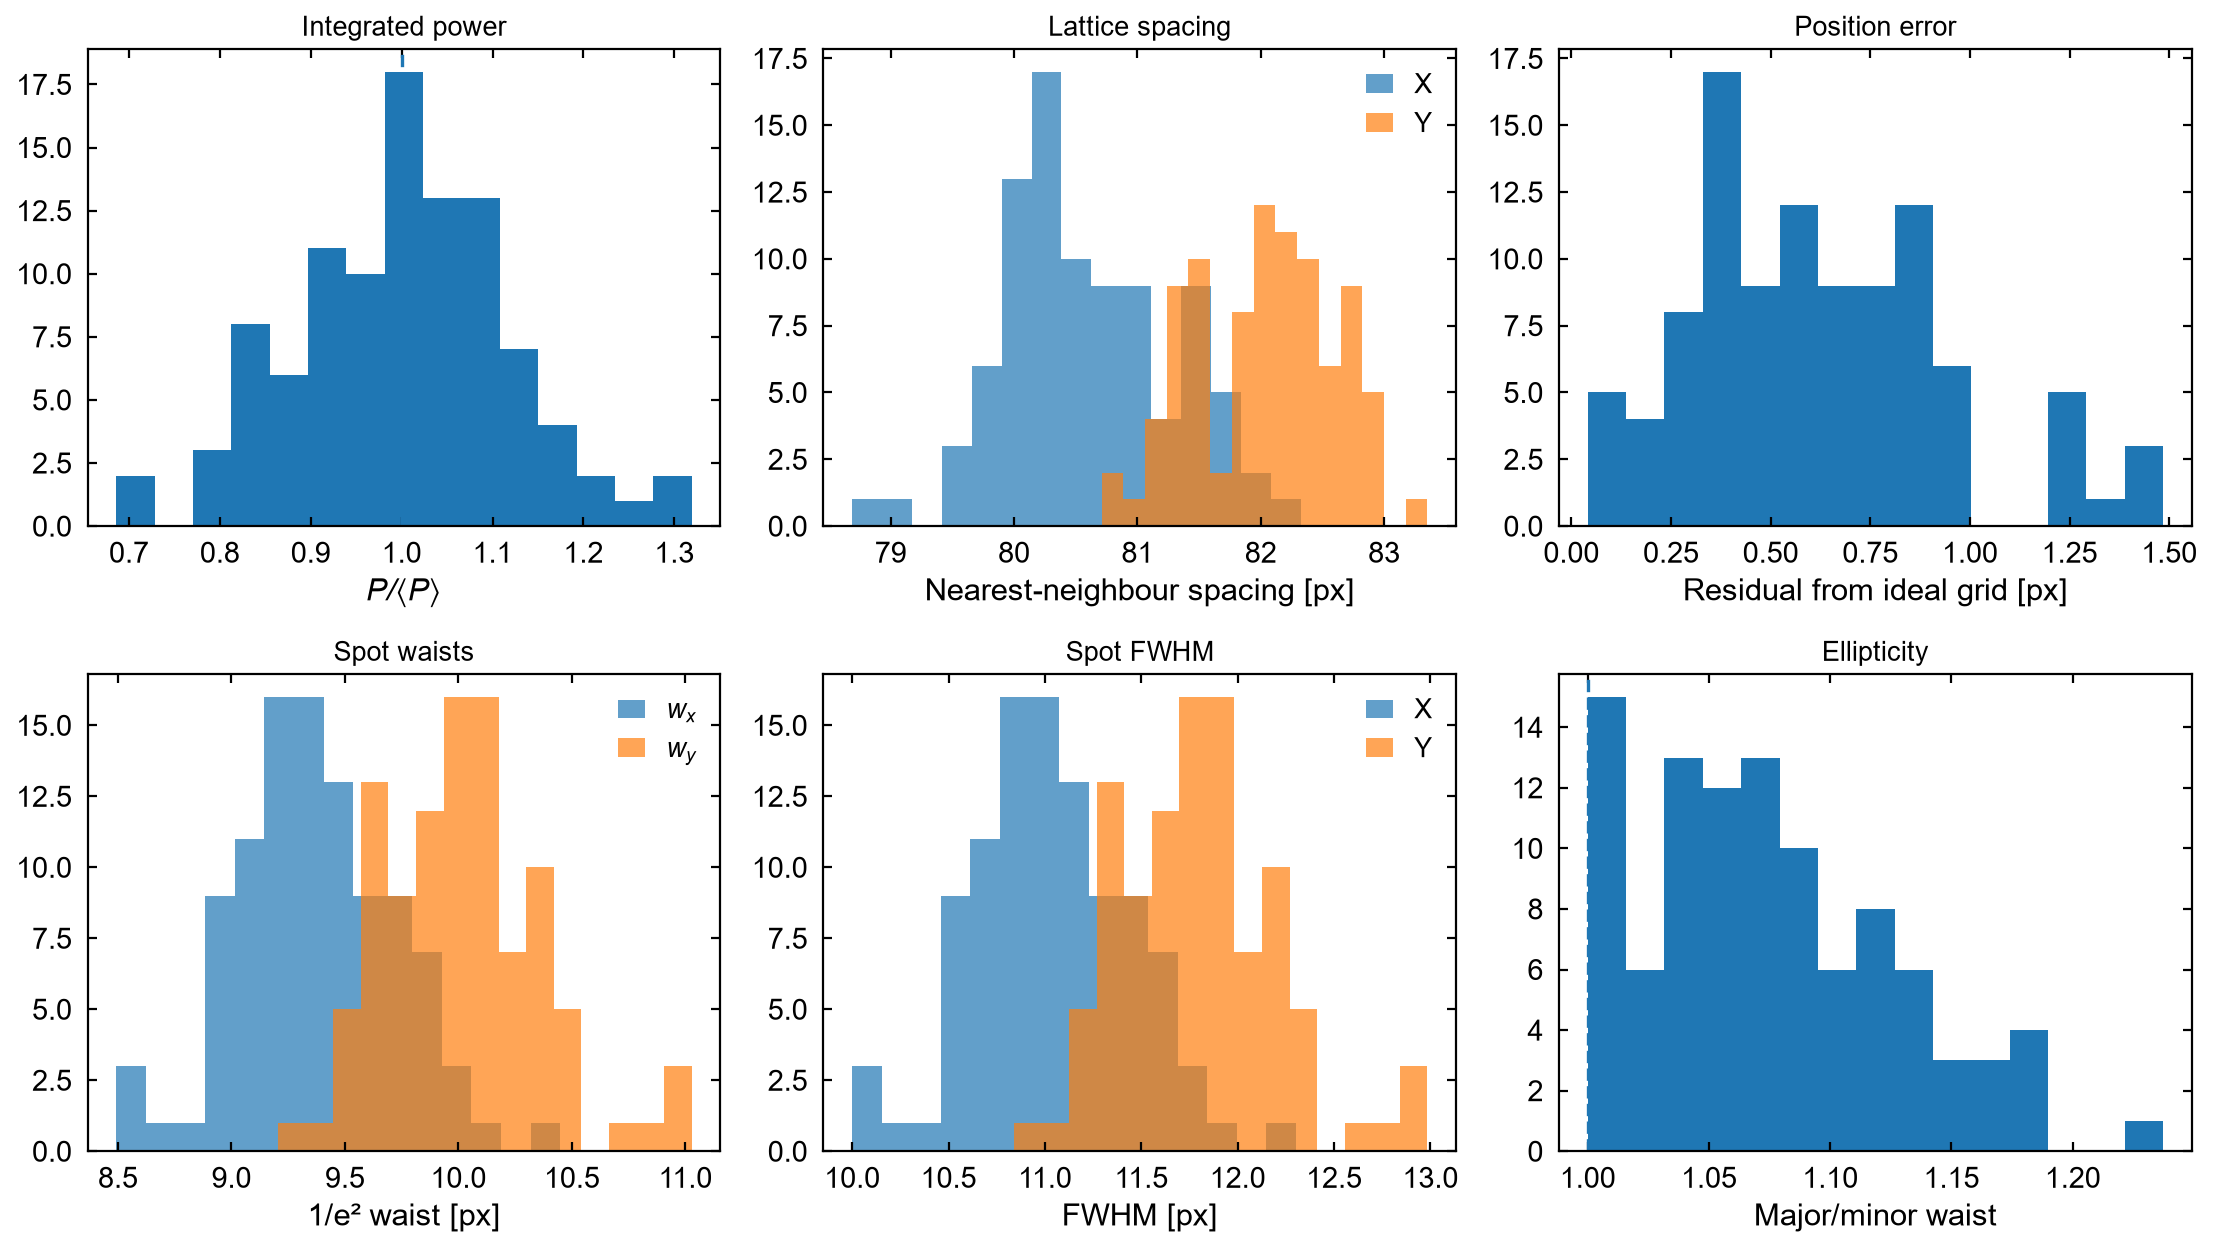

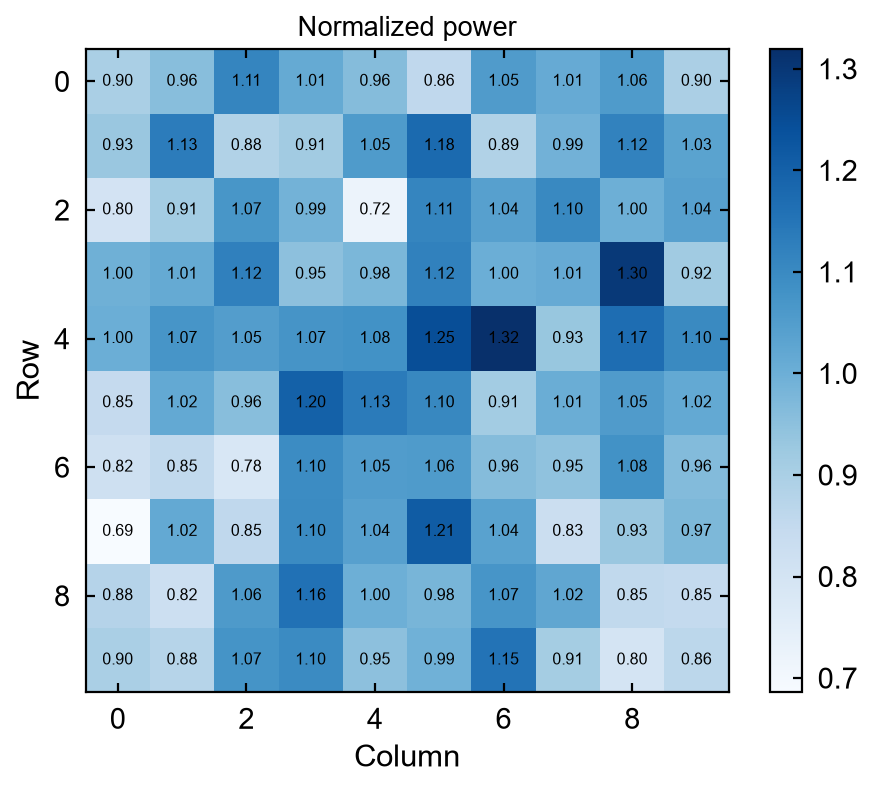

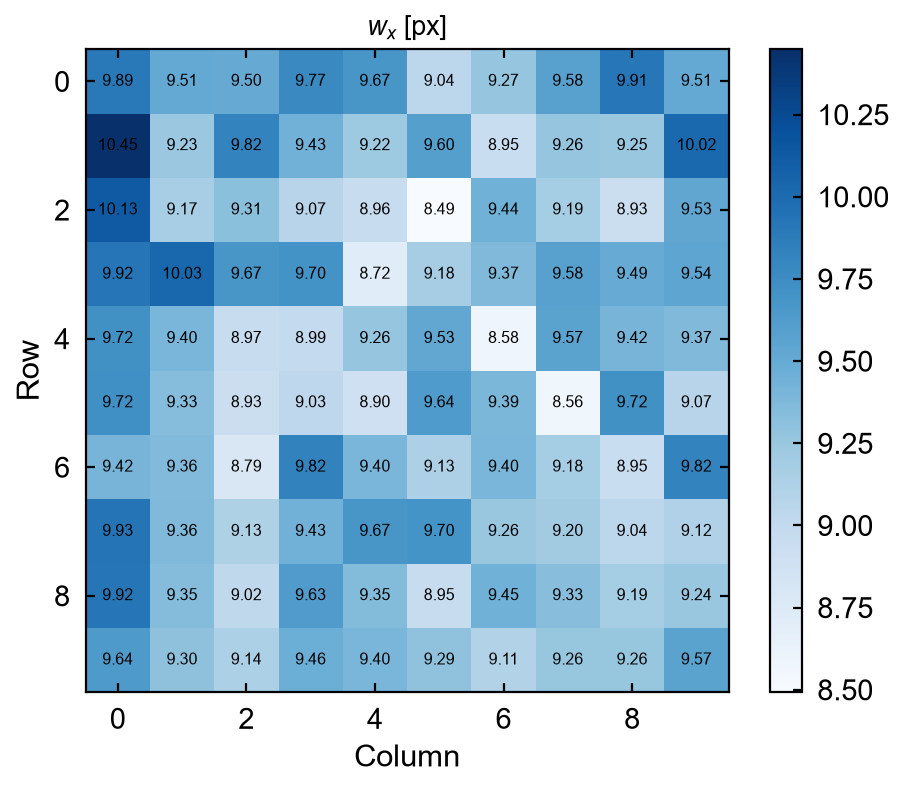

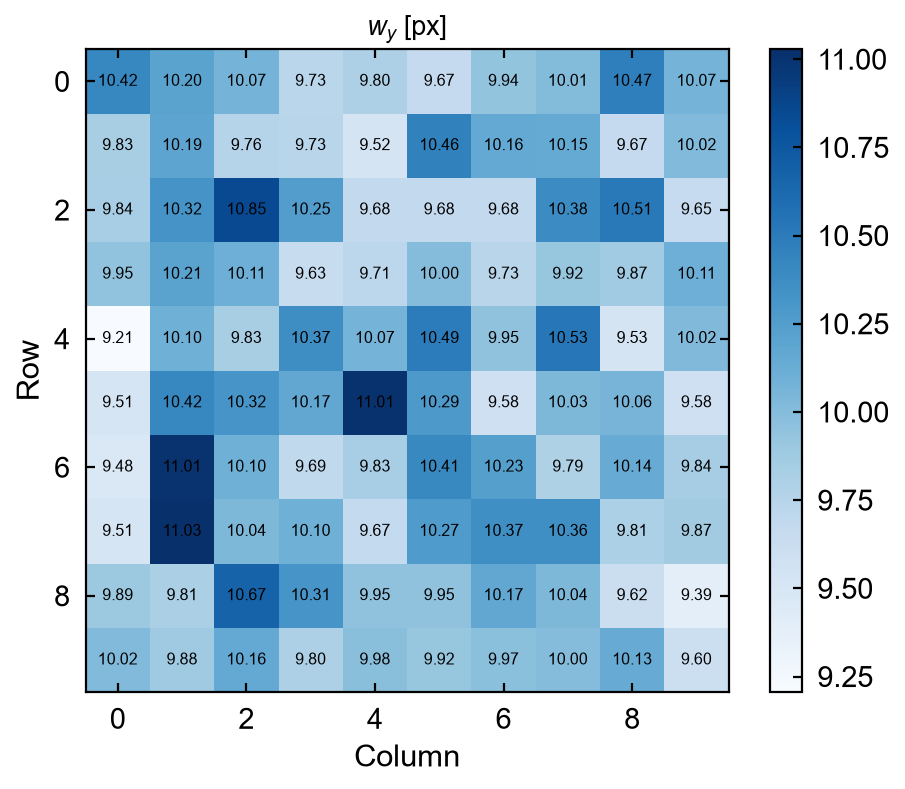

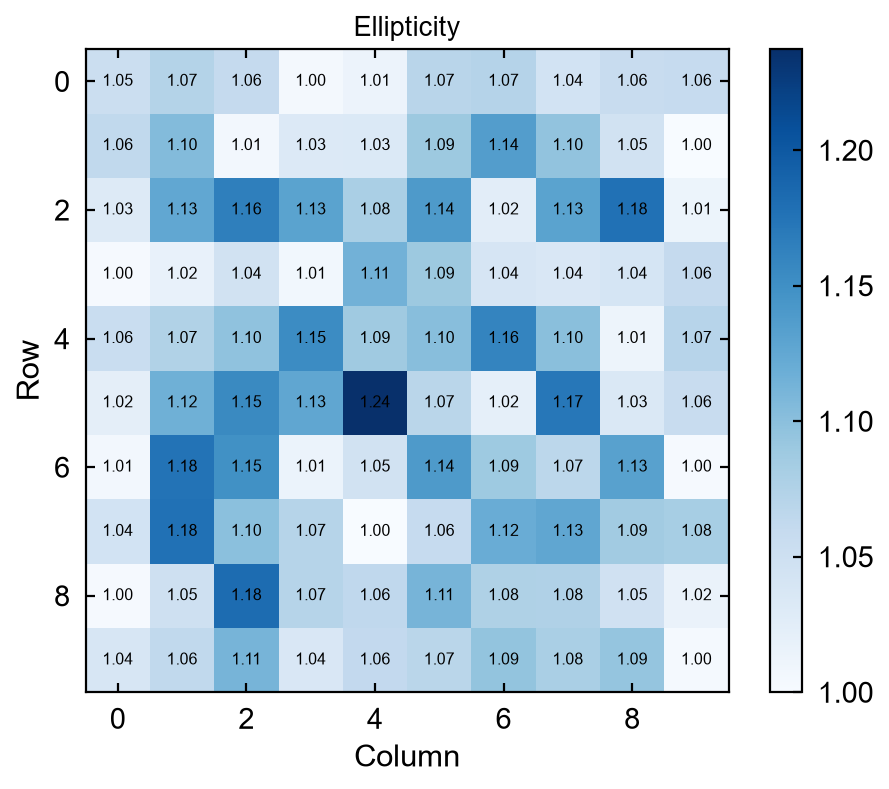

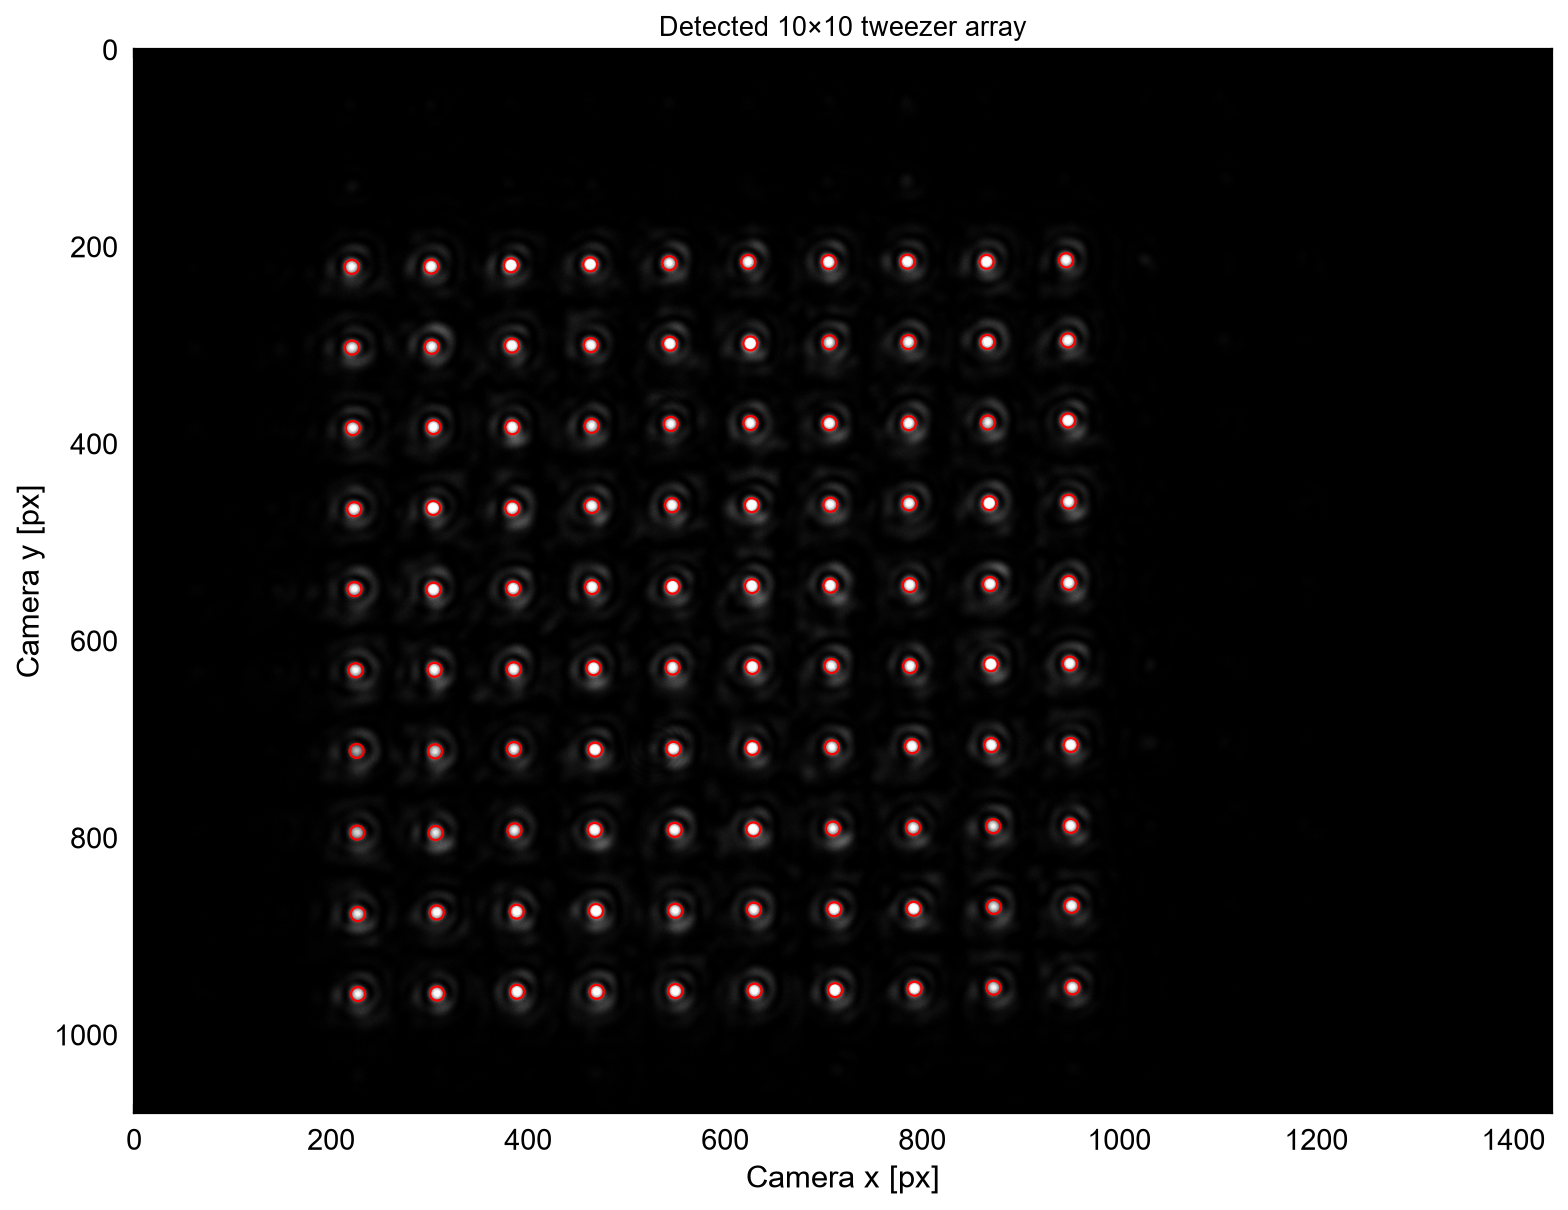


Saved per-spot results to 10x10_GS_spot_analysis.csv


In [5]:
# ============================================================
# COMPLETE 10x10 TWEEZER ARRAY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tifffile import imread
from scipy.ndimage import gaussian_filter, maximum_filter
from scipy.optimize import least_squares


# ============================================================
# USER SETTINGS
# ============================================================

FILE = r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data\atom array\10x10 after wgs kim and wgs fp and 2.5 shifted.tif"

NROWS = 10
NCOLS = 10

# Core region used for Gaussian fit.
# Keeps most of the first diffraction ring OUT of the fit.
FIT_RADIUS_PX = 10

# Local-background annulus.
BG_R1 = 28
BG_R2 = 36

# Integrated spot-power aperture.
# Includes central lobe + first diffraction ring.
POWER_RADIUS_PX = 27

# Optional object-plane conversion.
# Set to None if you only want camera pixels.
#
# For your present setup:
PIXEL_NM = 56.8057


# ============================================================
# LOAD IMAGE
# ============================================================

img = np.squeeze(
    imread(FILE)
).astype(float)

print("Image shape:", img.shape)
print("Min / max:", img.min(), img.max())


# ============================================================
# DETECT THE 100 SPOTS
# ============================================================

smooth = gaussian_filter(
    img,
    sigma=2
)

local_max = (
    smooth
    ==
    maximum_filter(
        smooth,
        size=35
    )
)

# Threshold chosen relative to image statistics.
threshold = max(
    5 * np.median(smooth),
    np.percentile(smooth, 97)
)

coords_yx = np.argwhere(
    local_max
    &
    (smooth > threshold)
)

brightness = smooth[
    coords_yx[:, 0],
    coords_yx[:, 1]
]

order = np.argsort(
    brightness
)[::-1]

coords_yx = coords_yx[
    order[:NROWS*NCOLS]
]


if len(coords_yx) != NROWS*NCOLS:
    raise RuntimeError(
        f"Detected {len(coords_yx)} spots, "
        f"expected {NROWS*NCOLS}."
    )


# convert y,x -> x,y
initial_peaks = np.column_stack([
    coords_yx[:, 1],
    coords_yx[:, 0]
])

print(
    f"Detected {len(initial_peaks)} spots."
)


# ============================================================
# FIT ONE TWEEZER
#
# Gaussian model:
#
# I = I0 exp[-1/2 (x'^2/sx^2 + y'^2/sy^2)]
#
# Therefore:
#
# FWHM = 2.35482 sigma
#
# 1/e^2 intensity waist:
#
# w = 2 sigma
# ============================================================

def fit_spot(
    image,
    x_guess,
    y_guess
):

    H, W = image.shape

    R = int(
        np.ceil(BG_R2 + 2)
    )

    xlo = max(
        0,
        int(round(x_guess)) - R
    )

    xhi = min(
        W,
        int(round(x_guess)) + R + 1
    )

    ylo = max(
        0,
        int(round(y_guess)) - R
    )

    yhi = min(
        H,
        int(round(y_guess)) + R + 1
    )


    patch = image[
        ylo:yhi,
        xlo:xhi
    ]


    yy, xx = np.indices(
        patch.shape
    )

    X = xx + xlo
    Y = yy + ylo


    rr_guess = np.sqrt(
        (X-x_guess)**2
        +
        (Y-y_guess)**2
    )


    # --------------------------------------------------------
    # LOCAL BACKGROUND
    # --------------------------------------------------------

    bg_mask = (
        (rr_guess >= BG_R1)
        &
        (rr_guess <= BG_R2)
    )

    bg = np.median(
        patch[bg_mask]
    )


    # --------------------------------------------------------
    # FIT ONLY CENTRAL CORE
    # --------------------------------------------------------

    fit_mask = (
        rr_guess <= FIT_RADIUS_PX
    )

    xv = X[fit_mask]
    yv = Y[fit_mask]

    zv = (
        patch[fit_mask]
        - bg
    )


    A0 = max(
        np.max(zv),
        1
    )


    # A, x0, y0, sx, sy, theta
    p0 = [
        A0,
        x_guess,
        y_guess,
        5,
        5,
        0
    ]


    lower = [
        0,
        x_guess-4,
        y_guess-4,
        1.5,
        1.5,
        -np.pi/4
    ]


    upper = [
        np.inf,
        x_guess+4,
        y_guess+4,
        12,
        12,
        +np.pi/4
    ]


    def model(p):

        A, x0, y0, sx, sy, theta = p

        ct = np.cos(theta)
        st = np.sin(theta)

        dx = xv-x0
        dy = yv-y0

        xp = (
            ct*dx
            +
            st*dy
        )

        yp = (
            -st*dx
            +
            ct*dy
        )

        return A*np.exp(
            -0.5 * (
                (xp/sx)**2
                +
                (yp/sy)**2
            )
        )


    result = least_squares(
        lambda p: model(p)-zv,
        p0,
        bounds=(lower, upper),
        loss="soft_l1",
        f_scale=5,
        max_nfev=2000
    )


    A, x0, y0, sx, sy, theta = (
        result.x
    )


    # --------------------------------------------------------
    # PROJECT ROTATED GAUSSIAN ONTO CAMERA X/Y
    # --------------------------------------------------------

    ct = np.cos(theta)
    st = np.sin(theta)

    sigma_x = np.sqrt(
        sx**2 * ct**2
        +
        sy**2 * st**2
    )

    sigma_y = np.sqrt(
        sx**2 * st**2
        +
        sy**2 * ct**2
    )


    FWHM_FACTOR = (
        2*np.sqrt(2*np.log(2))
    )


    fwhm_x = (
        FWHM_FACTOR
        * sigma_x
    )

    fwhm_y = (
        FWHM_FACTOR
        * sigma_y
    )


    # 1/e^2 INTENSITY WAISTS
    waist_x = 2*sigma_x
    waist_y = 2*sigma_y


    # --------------------------------------------------------
    # INTEGRATED POWER
    # --------------------------------------------------------

    rr = np.sqrt(
        (X-x0)**2
        +
        (Y-y0)**2
    )


    power_mask = (
        rr <= POWER_RADIUS_PX
    )

    power = np.sum(
        patch[power_mask]
        - bg
    )


    return {
        "x": x0,
        "y": y0,

        "peak": A,

        "background": bg,

        "sigma_x": sigma_x,
        "sigma_y": sigma_y,

        "fwhm_x": fwhm_x,
        "fwhm_y": fwhm_y,

        "waist_x": waist_x,
        "waist_y": waist_y,

        "power": power,

        "theta": theta,
    }


# ============================================================
# FIT ALL SPOTS
# ============================================================

results = []

for xg, yg in initial_peaks:

    results.append(
        fit_spot(
            img,
            xg,
            yg
        )
    )


df = pd.DataFrame(
    results
)


# ============================================================
# ASSIGN ROW / COLUMN NUMBERS
# ============================================================

order_y = np.argsort(
    df["y"].values
)

rows = np.empty(
    len(df),
    dtype=int
)

cols = np.empty(
    len(df),
    dtype=int
)


for r in range(NROWS):

    inds = order_y[
        r*NCOLS:
        (r+1)*NCOLS
    ]

    inds = inds[
        np.argsort(
            df.loc[
                inds,
                "x"
            ].values
        )
    ]

    rows[inds] = r

    cols[inds] = np.arange(
        NCOLS
    )


df["row"] = rows
df["col"] = cols


# ============================================================
# DERIVED SPOT PARAMETERS
# ============================================================

df["ellipticity"] = (
    np.maximum(
        df["waist_x"],
        df["waist_y"]
    )
    /
    np.minimum(
        df["waist_x"],
        df["waist_y"]
    )
)


df["waist_geo"] = np.sqrt(
    df["waist_x"]
    *
    df["waist_y"]
)


df["fwhm_geo"] = np.sqrt(
    df["fwhm_x"]
    *
    df["fwhm_y"]
)


df["power_norm"] = (
    df["power"]
    /
    df["power"].mean()
)


# ============================================================
# BUILD 10x10 MATRICES
# ============================================================

def matrix_from_column(name):

    M = np.full(
        (NROWS, NCOLS),
        np.nan
    )

    for _, spot in df.iterrows():

        M[
            int(spot["row"]),
            int(spot["col"])
        ] = spot[name]

    return M


X = matrix_from_column("x")
Y = matrix_from_column("y")

P = matrix_from_column("power_norm")

WX = matrix_from_column("waist_x")
WY = matrix_from_column("waist_y")

FX = matrix_from_column("fwhm_x")
FY = matrix_from_column("fwhm_y")

ELLIP = matrix_from_column(
    "ellipticity"
)


# ============================================================
# NEAREST-NEIGHBOR SPACING
# ============================================================

DX = np.sqrt(
    np.diff(X, axis=1)**2
    +
    np.diff(Y, axis=1)**2
).ravel()


DY = np.sqrt(
    np.diff(X, axis=0)**2
    +
    np.diff(Y, axis=0)**2
).ravel()


# ============================================================
# FIT AFFINE LATTICE
#
# position =
#
# origin + col*a + row*b
# ============================================================

design = np.column_stack([
    np.ones(len(df)),
    df["col"],
    df["row"]
])


coef_x = np.linalg.lstsq(
    design,
    df["x"],
    rcond=None
)[0]


coef_y = np.linalg.lstsq(
    design,
    df["y"],
    rcond=None
)[0]


a = np.array([
    coef_x[1],
    coef_y[1]
])


b = np.array([
    coef_x[2],
    coef_y[2]
])


pitch_x = np.linalg.norm(a)
pitch_y = np.linalg.norm(b)


angle_x = np.degrees(
    np.arctan2(
        a[1],
        a[0]
    )
)


angle_y = np.degrees(
    np.arctan2(
        b[1],
        b[0]
    )
)


orthogonality = (
    angle_y-angle_x
) % 180


# ------------------------------------------------------------
# POSITION RESIDUALS
# ------------------------------------------------------------

pred_x = (
    design @ coef_x
)

pred_y = (
    design @ coef_y
)


residual = np.sqrt(
    (df["x"]-pred_x)**2
    +
    (df["y"]-pred_y)**2
)


df["grid_residual"] = residual


# ============================================================
# STATISTICS FUNCTION
# ============================================================

def summary(name, values):

    values = np.asarray(
        values
    )

    mean = np.mean(values)

    std = np.std(
        values,
        ddof=1
    )

    print()
    print(name)
    print("-"*50)

    print(
        f"mean = {mean:.4f}"
    )

    print(
        f"std  = {std:.4f}"
    )

    print(
        f"CV   = {100*std/mean:.3f} %"
    )

    print(
        f"min  = {np.min(values):.4f}"
    )

    print(
        f"max  = {np.max(values):.4f}"
    )


# ============================================================
# PRINT MAIN RESULTS
# ============================================================

summary(
    "Integrated spot power",
    df["power"]
)

summary(
    "Peak intensity",
    df["peak"]
)

summary(
    "Horizontal spacing [px]",
    DX
)

summary(
    "Vertical spacing [px]",
    DY
)

summary(
    "waist_x [px]",
    df["waist_x"]
)

summary(
    "waist_y [px]",
    df["waist_y"]
)

summary(
    "FWHM_x [px]",
    df["fwhm_x"]
)

summary(
    "FWHM_y [px]",
    df["fwhm_y"]
)


print()
print("="*60)

print(
    f"Array rotation = "
    f"{angle_x:.4f} deg"
)

print(
    f"Grid angle = "
    f"{orthogonality:.4f} deg"
)

print(
    f"Mean grid residual = "
    f"{residual.mean():.3f} px"
)

print(
    f"Max grid residual = "
    f"{residual.max():.3f} px"
)


# ============================================================
# OPTIONAL REAL-SPACE VALUES
# ============================================================

if PIXEL_NM is not None:

    print()
    print("="*60)
    print("OBJECT-PLANE ESTIMATES")
    print("="*60)

    print(
        f"X spacing = "
        f"{DX.mean()*PIXEL_NM/1000:.4f} um"
    )

    print(
        f"Y spacing = "
        f"{DY.mean()*PIXEL_NM/1000:.4f} um"
    )

    print(
        f"Mean FWHM X = "
        f"{df['fwhm_x'].mean()*PIXEL_NM:.1f} nm"
    )

    print(
        f"Mean FWHM Y = "
        f"{df['fwhm_y'].mean()*PIXEL_NM:.1f} nm"
    )

    print(
        f"Mean waist X = "
        f"{df['waist_x'].mean()*PIXEL_NM:.1f} nm"
    )

    print(
        f"Mean waist Y = "
        f"{df['waist_y'].mean()*PIXEL_NM:.1f} nm"
    )


# ============================================================
# HISTOGRAMS
# ============================================================

fig, ax = plt.subplots(
    2,
    3,
    figsize=(14, 8)
)


ax[0,0].hist(
    df["power_norm"],
    bins=15
)

ax[0,0].axvline(
    1,
    linestyle="--"
)

ax[0,0].set_xlabel(
    r"$P/\langle P\rangle$"
)

ax[0,0].set_title(
    "Integrated power"
)


ax[0,1].hist(
    DX,
    bins=15,
    alpha=0.7,
    label="X"
)

ax[0,1].hist(
    DY,
    bins=15,
    alpha=0.7,
    label="Y"
)

ax[0,1].set_xlabel(
    "Nearest-neighbour spacing [px]"
)

ax[0,1].legend()

ax[0,1].set_title(
    "Lattice spacing"
)


ax[0,2].hist(
    df["grid_residual"],
    bins=15
)

ax[0,2].set_xlabel(
    "Residual from ideal grid [px]"
)

ax[0,2].set_title(
    "Position error"
)


ax[1,0].hist(
    df["waist_x"],
    bins=15,
    alpha=0.7,
    label=r"$w_x$"
)

ax[1,0].hist(
    df["waist_y"],
    bins=15,
    alpha=0.7,
    label=r"$w_y$"
)

ax[1,0].set_xlabel(
    "1/e² waist [px]"
)

ax[1,0].legend()

ax[1,0].set_title(
    "Spot waists"
)


ax[1,1].hist(
    df["fwhm_x"],
    bins=15,
    alpha=0.7,
    label="X"
)

ax[1,1].hist(
    df["fwhm_y"],
    bins=15,
    alpha=0.7,
    label="Y"
)

ax[1,1].set_xlabel(
    "FWHM [px]"
)

ax[1,1].legend()

ax[1,1].set_title(
    "Spot FWHM"
)


ax[1,2].hist(
    df["ellipticity"],
    bins=15
)

ax[1,2].axvline(
    1,
    linestyle="--"
)

ax[1,2].set_xlabel(
    "Major/minor waist"
)

ax[1,2].set_title(
    "Ellipticity"
)


plt.tight_layout()
plt.show()


# ============================================================
# HEATMAPS
# ============================================================

maps = [
    (
        P,
        "Normalized power"
    ),
    (
        WX,
        r"$w_x$ [px]"
    ),
    (
        WY,
        r"$w_y$ [px]"
    ),
    (
        ELLIP,
        "Ellipticity"
    ),
]


for data, title in maps:

    plt.figure(
        figsize=(6,5)
    )

    im = plt.imshow(
        data,
        origin="upper"
    )

    plt.colorbar(
        im
    )

    for r in range(NROWS):
        for c in range(NCOLS):

            plt.text(
                c,
                r,
                f"{data[r,c]:.2f}",
                ha="center",
                va="center",
                fontsize=7
            )

    plt.xlabel(
        "Column"
    )

    plt.ylabel(
        "Row"
    )

    plt.title(
        title
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# OVERLAY FITTED CENTERS ON ORIGINAL IMAGE
# ============================================================

plt.figure(
    figsize=(10,8)
)

plt.imshow(
    img,
    cmap="gray",
    vmin=np.percentile(img, 1),
    vmax=np.percentile(img, 99.8)
)

plt.scatter(
    df["x"],
    df["y"],
    facecolors="none",
    edgecolors="red",
    s=40
)

plt.xlabel(
    "Camera x [px]"
)

plt.ylabel(
    "Camera y [px]"
)

plt.title(
    "Detected 10×10 tweezer array"
)

plt.tight_layout()
plt.show()


# ============================================================
# SAVE NUMERICAL RESULTS
# ============================================================

df.to_csv(
    "10x10_GS_spot_analysis.csv",
    index=False
)

print(
    "\nSaved per-spot results to "
    "10x10_GS_spot_analysis.csv"
)

C:\Users\admin\AppData\Local\Temp\ipykernel_10152\3806554373.py:105: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[0].set_xticklabels([
C:\Users\admin\AppData\Local\Temp\ipykernel_10152\3806554373.py:109: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[0].set_yticklabels([


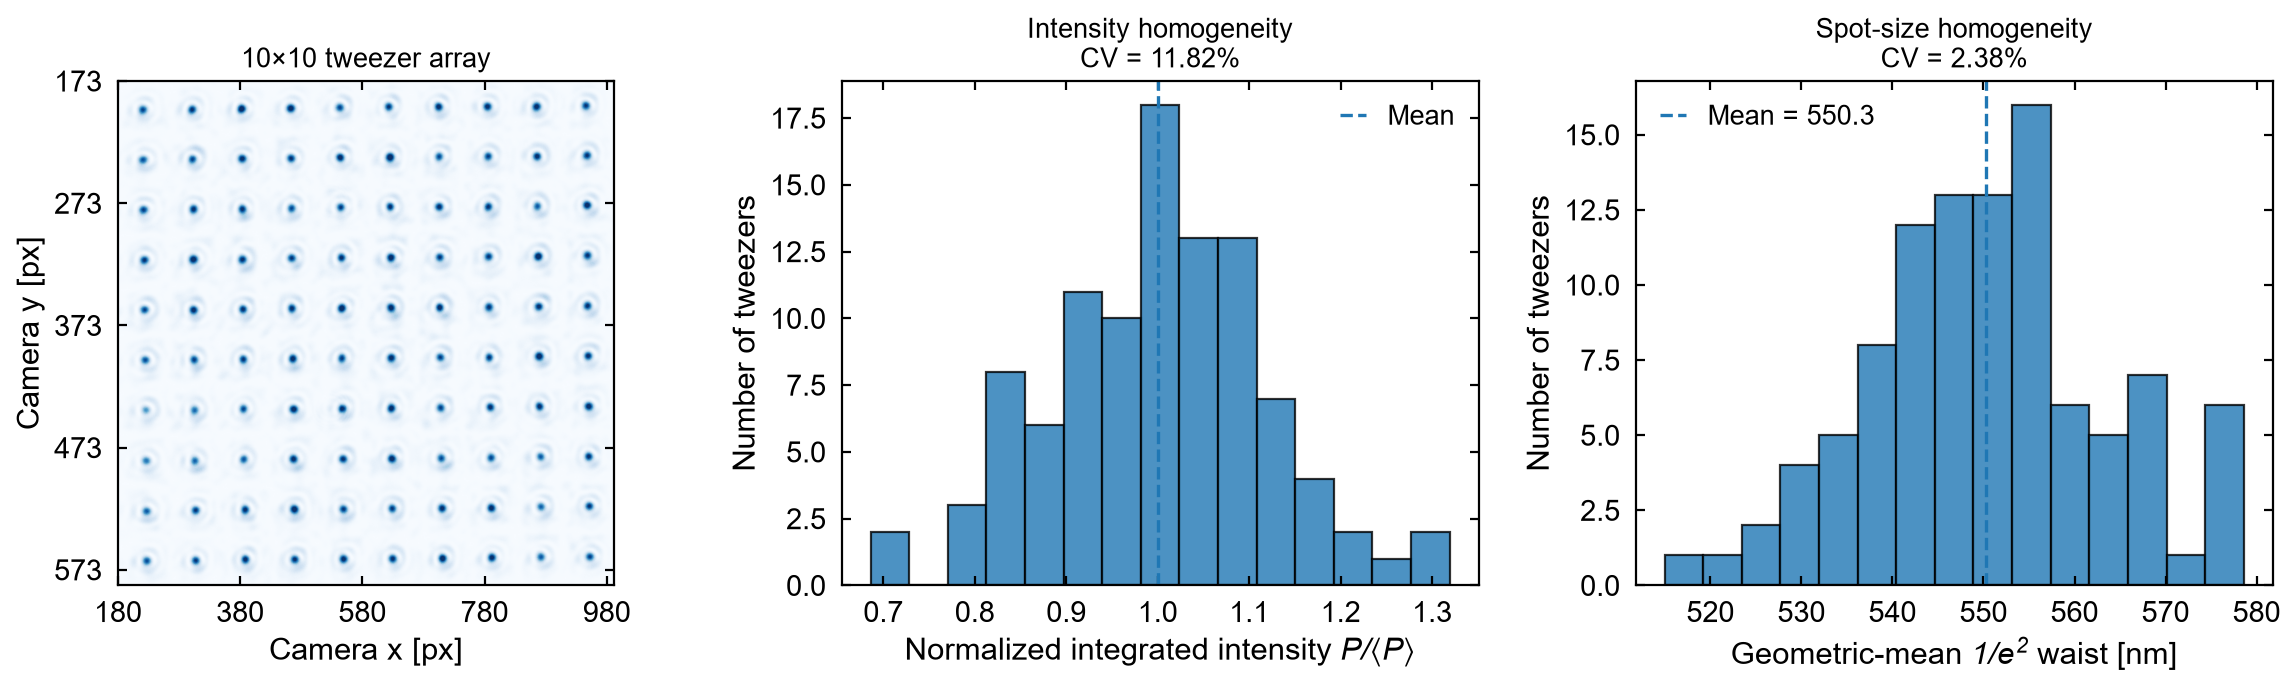

In [6]:
# ============================================================
# FINAL 3-PANEL FIGURE
#
# 1. Cropped 10x10 array in Blues
# 2. Normalized integrated-intensity histogram
# 3. Averaged (geometric-mean) waist histogram
# ============================================================

# ------------------------------------------------------------
# CROP AROUND THE 10x10 ARRAY
# ------------------------------------------------------------

CROP_MARGIN = 40   # camera pixels around outermost tweezers

xmin = max(
    0,
    int(np.floor(df["x"].min() - CROP_MARGIN))
)

xmax = min(
    img.shape[1],
    int(np.ceil(df["x"].max() + CROP_MARGIN))
)

ymin = max(
    0,
    int(np.floor(df["y"].min() - CROP_MARGIN))
)

ymax = min(
    img.shape[0],
    int(np.ceil(df["y"].max() + CROP_MARGIN))
)

crop = img[
    ymin:ymax,
    xmin:xmax
]


# ------------------------------------------------------------
# DATA FOR HISTOGRAMS
# ------------------------------------------------------------

# WGS-relevant intensity metric:
intensity = df["power_norm"].values

# Average spot waist:
# geometric mean sqrt(wx * wy)
waist_avg_px = df["waist_geo"].values

if PIXEL_NM is not None:
    waist_avg = waist_avg_px * PIXEL_NM
    waist_xlabel = r"Geometric-mean $1/e^2$ waist [nm]"
else:
    waist_avg = waist_avg_px
    waist_xlabel = r"Geometric-mean $1/e^2$ waist [px]"


# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    1,
    3,
    figsize=(15, 4.5)
)


# ============================================================
# PANEL 1 — CROPPED TWEEZER ARRAY
# ============================================================

# Slight contrast clipping only for display
vmin = np.percentile(crop, 1)
vmax = np.percentile(crop, 99.8)

ax[0].imshow(
    crop,
    cmap="Blues",
    origin="upper",
    vmin=vmin,
    vmax=vmax
)

ax[0].set_title(
    "10×10 tweezer array"
)

ax[0].set_xlabel(
    "Camera x [px]"
)

ax[0].set_ylabel(
    "Camera y [px]"
)


# Optional: make displayed coordinates correspond
# to full-camera coordinates rather than crop coordinates
xticks = ax[0].get_xticks()
yticks = ax[0].get_yticks()

ax[0].set_xticklabels([
    f"{x + xmin:.0f}" for x in xticks
])

ax[0].set_yticklabels([
    f"{y + ymin:.0f}" for y in yticks
])


# ============================================================
# PANEL 2 — INTENSITY / POWER HISTOGRAM
# ============================================================

ax[1].hist(
    intensity,
    bins=15,
    edgecolor="black",
    alpha=0.8
)

ax[1].axvline(
    1.0,
    linestyle="--",
    linewidth=1.5,
    label="Mean"
)

CV_power = (
    100
    * np.std(
        intensity,
        ddof=1
    )
    / np.mean(intensity)
)

ax[1].set_xlabel(
    r"Normalized integrated intensity $P/\langle P\rangle$"
)

ax[1].set_ylabel(
    "Number of tweezers"
)

ax[1].set_title(
    f"Intensity homogeneity\nCV = {CV_power:.2f}%"
)

ax[1].legend(
    frameon=False
)


# ============================================================
# PANEL 3 — AVERAGED WAIST HISTOGRAM
# ============================================================

ax[2].hist(
    waist_avg,
    bins=15,
    edgecolor="black",
    alpha=0.8
)

waist_mean = np.mean(
    waist_avg
)

waist_std = np.std(
    waist_avg,
    ddof=1
)

waist_CV = (
    100
    * waist_std
    / waist_mean
)

ax[2].axvline(
    waist_mean,
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {waist_mean:.1f}"
)

ax[2].set_xlabel(
    waist_xlabel
)

ax[2].set_ylabel(
    "Number of tweezers"
)

ax[2].set_title(
    f"Spot-size homogeneity\nCV = {waist_CV:.2f}%"
)

ax[2].legend(
    frameon=False
)


# ============================================================
# FINISH
# ============================================================

for a in ax:
    a.tick_params(
        direction="in"
    )

plt.tight_layout()
plt.show()

saved figures\tweezer_homogeneity.svg  (453.5 pt x 128.5 pt)
Intensity CV  = 11.8 %
Mean waist    = 550 nm
Waist CV      = 2.4 %


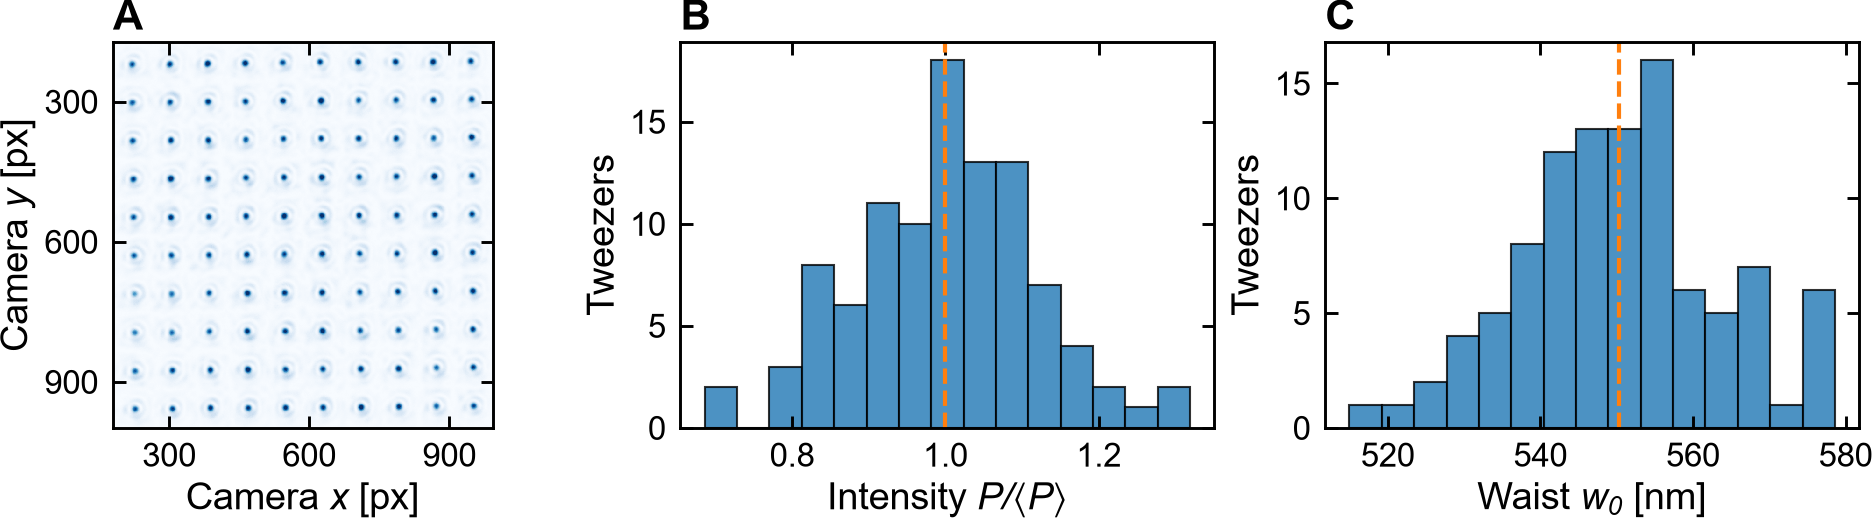

In [7]:
# ============================================================
# FINAL 3-PANEL FIGURE (thesis version)
#
# 1. Cropped 10x10 array in Blues
# 2. Normalized integrated-intensity histogram
# 3. Averaged (geometric-mean) waist histogram
#
# Needs from your analysis: img, df (columns x, y, power_norm,
# waist_geo), PIXEL_NM (or None). thesis_plot.py must be importable.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import thesis_plot as tp

tp.apply_style()   # replaces plt.style.use(".../physics.mplstyle")

# One figure spanning the text width (True), or three separate
# third-width files for a Typst grid (False)
AS_ONE_FIGURE = True
FIG_NAME = "tweezer_homogeneity"
N_BINS = 15


# ------------------------------------------------------------
# CROP AROUND THE 10x10 ARRAY  (unchanged)
# ------------------------------------------------------------

CROP_MARGIN = 40   # camera pixels around outermost tweezers

xmin = max(0, int(np.floor(df["x"].min() - CROP_MARGIN)))
xmax = min(img.shape[1], int(np.ceil(df["x"].max() + CROP_MARGIN)))
ymin = max(0, int(np.floor(df["y"].min() - CROP_MARGIN)))
ymax = min(img.shape[0], int(np.ceil(df["y"].max() + CROP_MARGIN)))

crop = img[ymin:ymax, xmin:xmax]


# ------------------------------------------------------------
# DATA FOR HISTOGRAMS  (unchanged)
# ------------------------------------------------------------

intensity = df["power_norm"].values          # P / <P>
waist_avg_px = df["waist_geo"].values        # sqrt(wx * wy)

if PIXEL_NM is not None:
    waist_avg = waist_avg_px * PIXEL_NM
    waist_unit = "nm"
else:
    waist_avg = waist_avg_px
    waist_unit = "px"

CV_power = 100 * np.std(intensity, ddof=1) / np.mean(intensity)
waist_mean = np.mean(waist_avg)
waist_CV = 100 * np.std(waist_avg, ddof=1) / waist_mean


# ------------------------------------------------------------
# CREATE FIGURE(S) at the exact printed size
# ------------------------------------------------------------

if AS_ONE_FIGURE:
    fig, ax = tp.row(ncols=3)
    figs = [fig]
else:
    figs, ax = [], []
    for _ in range(3):
        f, a = tp.panel(ncols=3)
        figs.append(f)
        ax.append(a)


# ============================================================
# PANEL 1 — CROPPED TWEEZER ARRAY
# ============================================================

vmin = np.percentile(crop, 1)       # contrast clipping for display only
vmax = np.percentile(crop, 99.8)

# extent puts full-camera coordinates on the axes directly
# (more robust than relabelling tick positions afterwards)
ax[0].imshow(
    crop,
    cmap="Blues",
    origin="upper",
    vmin=vmin,
    vmax=vmax,
    extent=(xmin - 0.5, xmax - 0.5, ymax - 0.5, ymin - 0.5),
    interpolation="nearest",
)
ax[0].set_xlabel("Camera $x$ [px]")
ax[0].set_ylabel("Camera $y$ [px]")
ax[0].xaxis.set_major_locator(mticker.MaxNLocator(nbins=3))
ax[0].yaxis.set_major_locator(mticker.MaxNLocator(nbins=3))


# ============================================================
# PANEL 2 — INTENSITY / POWER HISTOGRAM
# ============================================================

ax[1].hist(intensity, bins=N_BINS, color="C0", alpha=0.8,
           edgecolor="black", linewidth=0.5)
ax[1].axvline(1.0, linestyle="--", color="C1", linewidth=1.0)
ax[1].set_xlabel(r"Intensity $P/\langle P\rangle$")
ax[1].set_ylabel("Tweezers")


# ============================================================
# PANEL 3 — AVERAGED WAIST HISTOGRAM
# ============================================================

ax[2].hist(waist_avg, bins=N_BINS, color="C0", alpha=0.8,
           edgecolor="black", linewidth=0.5)
ax[2].axvline(waist_mean, linestyle="--", color="C1", linewidth=1.0)
ax[2].set_xlabel(f"Waist $w_0$ [{waist_unit}]")
ax[2].set_ylabel("Tweezers")


# ============================================================
# FINISH
# ============================================================

for a in ax[1:]:
    # counts are integers
    a.yaxis.set_major_locator(mticker.MaxNLocator(nbins=4, integer=True))
    a.xaxis.set_major_locator(mticker.MaxNLocator(nbins=4))

# Bold A, B, C as left-aligned titles (same in both layouts)
tp.label_panels(ax)

if AS_ONE_FIGURE:
    tp.save(figs[0], FIG_NAME, close=False)
else:
    for f, letter in zip(figs, "abc"):
        tp.save(f, f"{FIG_NAME}_{letter}", close=False)

# Numbers for the caption
print(f"Intensity CV  = {CV_power:.1f} %")
print(f"Mean waist    = {waist_mean:.0f} {waist_unit}")
print(f"Waist CV      = {waist_CV:.1f} %")

plt.show()

saved figures\tweezer_homogeneity.svg  (453.5 pt x 128.5 pt)
Magnification = 60.73x  (56.81 nm/px)
Array pitch   = 4.56 um (object plane)
Intensity CV  = 11.8 %
Mean waist    = 550 nm
Waist CV      = 2.4 %


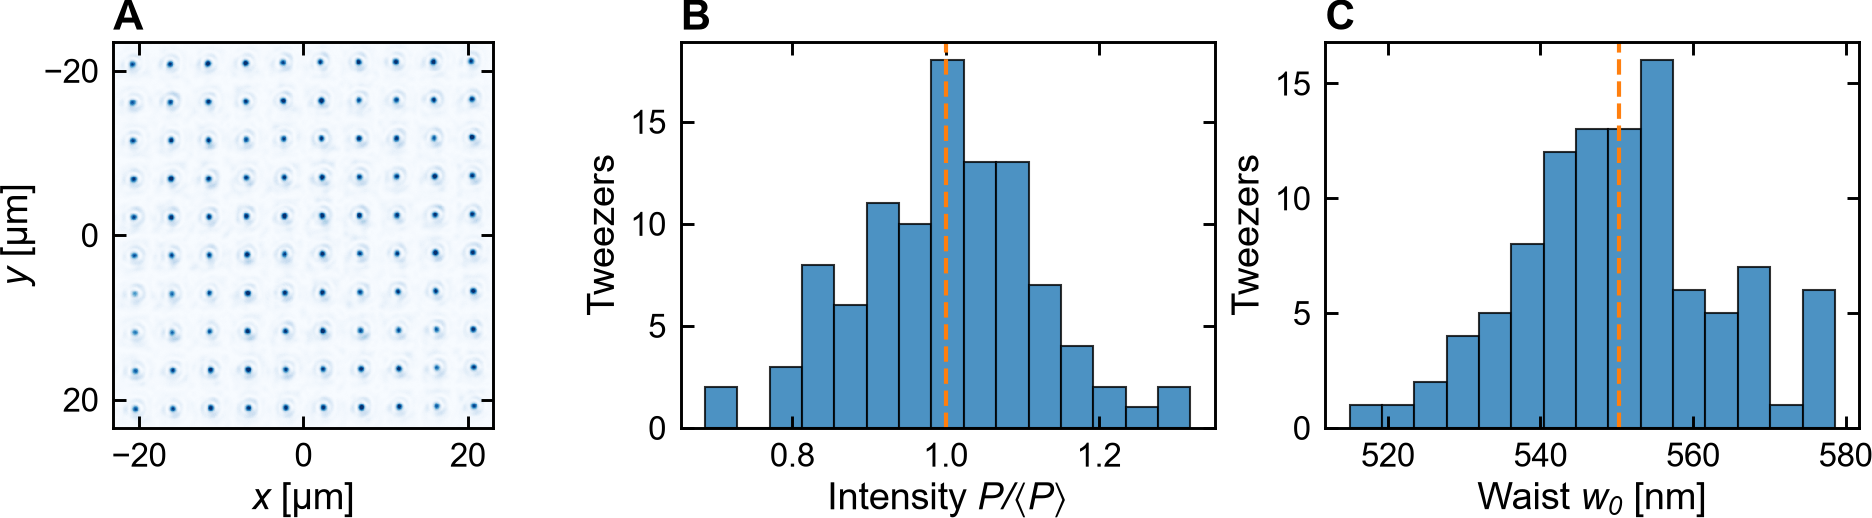

In [8]:
# ============================================================
# FINAL 3-PANEL FIGURE (thesis version)
#
# 1. Cropped 10x10 array in Blues
# 2. Normalized integrated-intensity histogram
# 3. Averaged (geometric-mean) waist histogram
#
# Needs from your analysis: img, df (columns x, y, power_norm,
# waist_geo, all in camera pixels). thesis_plot.py must be importable.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import thesis_plot as tp

tp.apply_style()   # replaces plt.style.use(".../physics.mplstyle")

# One figure spanning the text width (True), or three separate
# third-width files for a Typst grid (False)
AS_ONE_FIGURE = True
FIG_NAME = "tweezer_homogeneity"
N_BINS = 15

# ------------------------------------------------------------
# IMAGING CALIBRATION
# Zeiss 0.9 NA objective + 100 mm tube lens + Thorlabs CS165MU1
# ------------------------------------------------------------
CAMERA_PIXEL_UM = 3.45            # CS165MU1 pixel pitch
PIXEL_NM = 56.8057                # calibrated object-plane sampling
MAGNIFICATION = CAMERA_PIXEL_UM * 1e3 / PIXEL_NM   # = 60.73x
PIXEL_UM = PIXEL_NM / 1e3

# Image axes: object-plane position in um, centred on the array (True),
# or raw camera pixels (False)
IMAGE_IN_UM = True


# ------------------------------------------------------------
# CROP AROUND THE 10x10 ARRAY  (unchanged)
# ------------------------------------------------------------

CROP_MARGIN = 40   # camera pixels around outermost tweezers

xmin = max(0, int(np.floor(df["x"].min() - CROP_MARGIN)))
xmax = min(img.shape[1], int(np.ceil(df["x"].max() + CROP_MARGIN)))
ymin = max(0, int(np.floor(df["y"].min() - CROP_MARGIN)))
ymax = min(img.shape[0], int(np.ceil(df["y"].max() + CROP_MARGIN)))

crop = img[ymin:ymax, xmin:xmax]


# ------------------------------------------------------------
# DATA FOR HISTOGRAMS  (unchanged)
# ------------------------------------------------------------

intensity = df["power_norm"].values          # P / <P>
waist_avg_px = df["waist_geo"].values        # sqrt(wx * wy), camera px
waist_avg = waist_avg_px * PIXEL_NM          # object plane, nm
waist_unit = "nm"

CV_power = 100 * np.std(intensity, ddof=1) / np.mean(intensity)
waist_mean = np.mean(waist_avg)
waist_CV = 100 * np.std(waist_avg, ddof=1) / waist_mean


# ------------------------------------------------------------
# CREATE FIGURE(S) at the exact printed size
# ------------------------------------------------------------

if AS_ONE_FIGURE:
    fig, ax = tp.row(ncols=3)
    figs = [fig]
else:
    figs, ax = [], []
    for _ in range(3):
        f, a = tp.panel(ncols=3)
        figs.append(f)
        ax.append(a)


# ============================================================
# PANEL 1 — CROPPED TWEEZER ARRAY
# ============================================================

vmin = np.percentile(crop, 1)       # contrast clipping for display only
vmax = np.percentile(crop, 99.8)

# extent puts physical coordinates on the axes directly
if IMAGE_IN_UM:
    xc, yc = df["x"].mean(), df["y"].mean()          # array centre (px)
    extent = ((xmin - 0.5 - xc) * PIXEL_UM, (xmax - 0.5 - xc) * PIXEL_UM,
              (ymax - 0.5 - yc) * PIXEL_UM, (ymin - 0.5 - yc) * PIXEL_UM)
    img_xlabel, img_ylabel = "$x$ [µm]", "$y$ [µm]"
else:
    extent = (xmin - 0.5, xmax - 0.5, ymax - 0.5, ymin - 0.5)
    img_xlabel, img_ylabel = "Camera $x$ [px]", "Camera $y$ [px]"

ax[0].imshow(
    crop,
    cmap="Blues",
    origin="upper",
    vmin=vmin,
    vmax=vmax,
    extent=extent,
    interpolation="nearest",
)
ax[0].set_xlabel(img_xlabel)
ax[0].set_ylabel(img_ylabel)
ax[0].xaxis.set_major_locator(mticker.MaxNLocator(nbins=3))
ax[0].yaxis.set_major_locator(mticker.MaxNLocator(nbins=3))


# ============================================================
# PANEL 2 — INTENSITY / POWER HISTOGRAM
# ============================================================

ax[1].hist(intensity, bins=N_BINS, color="C0", alpha=0.8,
           edgecolor="black", linewidth=0.5)
ax[1].axvline(1.0, linestyle="--", color="C1", linewidth=1.0)
ax[1].set_xlabel(r"Intensity $P/\langle P\rangle$")
ax[1].set_ylabel("Tweezers")


# ============================================================
# PANEL 3 — AVERAGED WAIST HISTOGRAM
# ============================================================

ax[2].hist(waist_avg, bins=N_BINS, color="C0", alpha=0.8,
           edgecolor="black", linewidth=0.5)
ax[2].axvline(waist_mean, linestyle="--", color="C1", linewidth=1.0)
ax[2].set_xlabel(f"Waist $w_0$ [{waist_unit}]")
ax[2].set_ylabel("Tweezers")


# ============================================================
# FINISH
# ============================================================

for a in ax[1:]:
    # counts are integers
    a.yaxis.set_major_locator(mticker.MaxNLocator(nbins=4, integer=True))
    a.xaxis.set_major_locator(mticker.MaxNLocator(nbins=4))

# Bold A, B, C as left-aligned titles (same in both layouts)
tp.label_panels(ax)

if AS_ONE_FIGURE:
    tp.save(figs[0], FIG_NAME, close=False)
else:
    for f, letter in zip(figs, "abc"):
        tp.save(f, f"{FIG_NAME}_{letter}", close=False)

# Numbers for the caption
print(f"Magnification = {MAGNIFICATION:.2f}x  ({PIXEL_NM:.2f} nm/px)")
xy = df[["x", "y"]].to_numpy()
d = np.hypot(*(xy[:, None, :] - xy[None, :, :]).T)
np.fill_diagonal(d, np.inf)
pitch_px = np.median(d.min(axis=1))            # nearest-neighbour distance
print(f"Array pitch   = {pitch_px * PIXEL_UM:.2f} um (object plane)")
print(f"Intensity CV  = {CV_power:.1f} %")
print(f"Mean waist    = {waist_mean:.0f} {waist_unit}")
print(f"Waist CV      = {waist_CV:.1f} %")

plt.show()

## axial scan

In [9]:
# ============================================================
# FIX FFMPEG FOR MATPLOTLIB
# ============================================================

%pip install imageio-ffmpeg

Note: you may need to restart the kernel to use updated packages.


In [10]:
import imageio_ffmpeg
import matplotlib.pyplot as plt

ffmpeg_path = imageio_ffmpeg.get_ffmpeg_exe()

plt.rcParams["animation.ffmpeg_path"] = ffmpeg_path

print("FFmpeg executable:")
print(ffmpeg_path)

FFmpeg executable:
c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\imageio_ffmpeg\binaries\ffmpeg-win-x86_64-v7.1.exe


NameError: name 'VMIN' is not defined

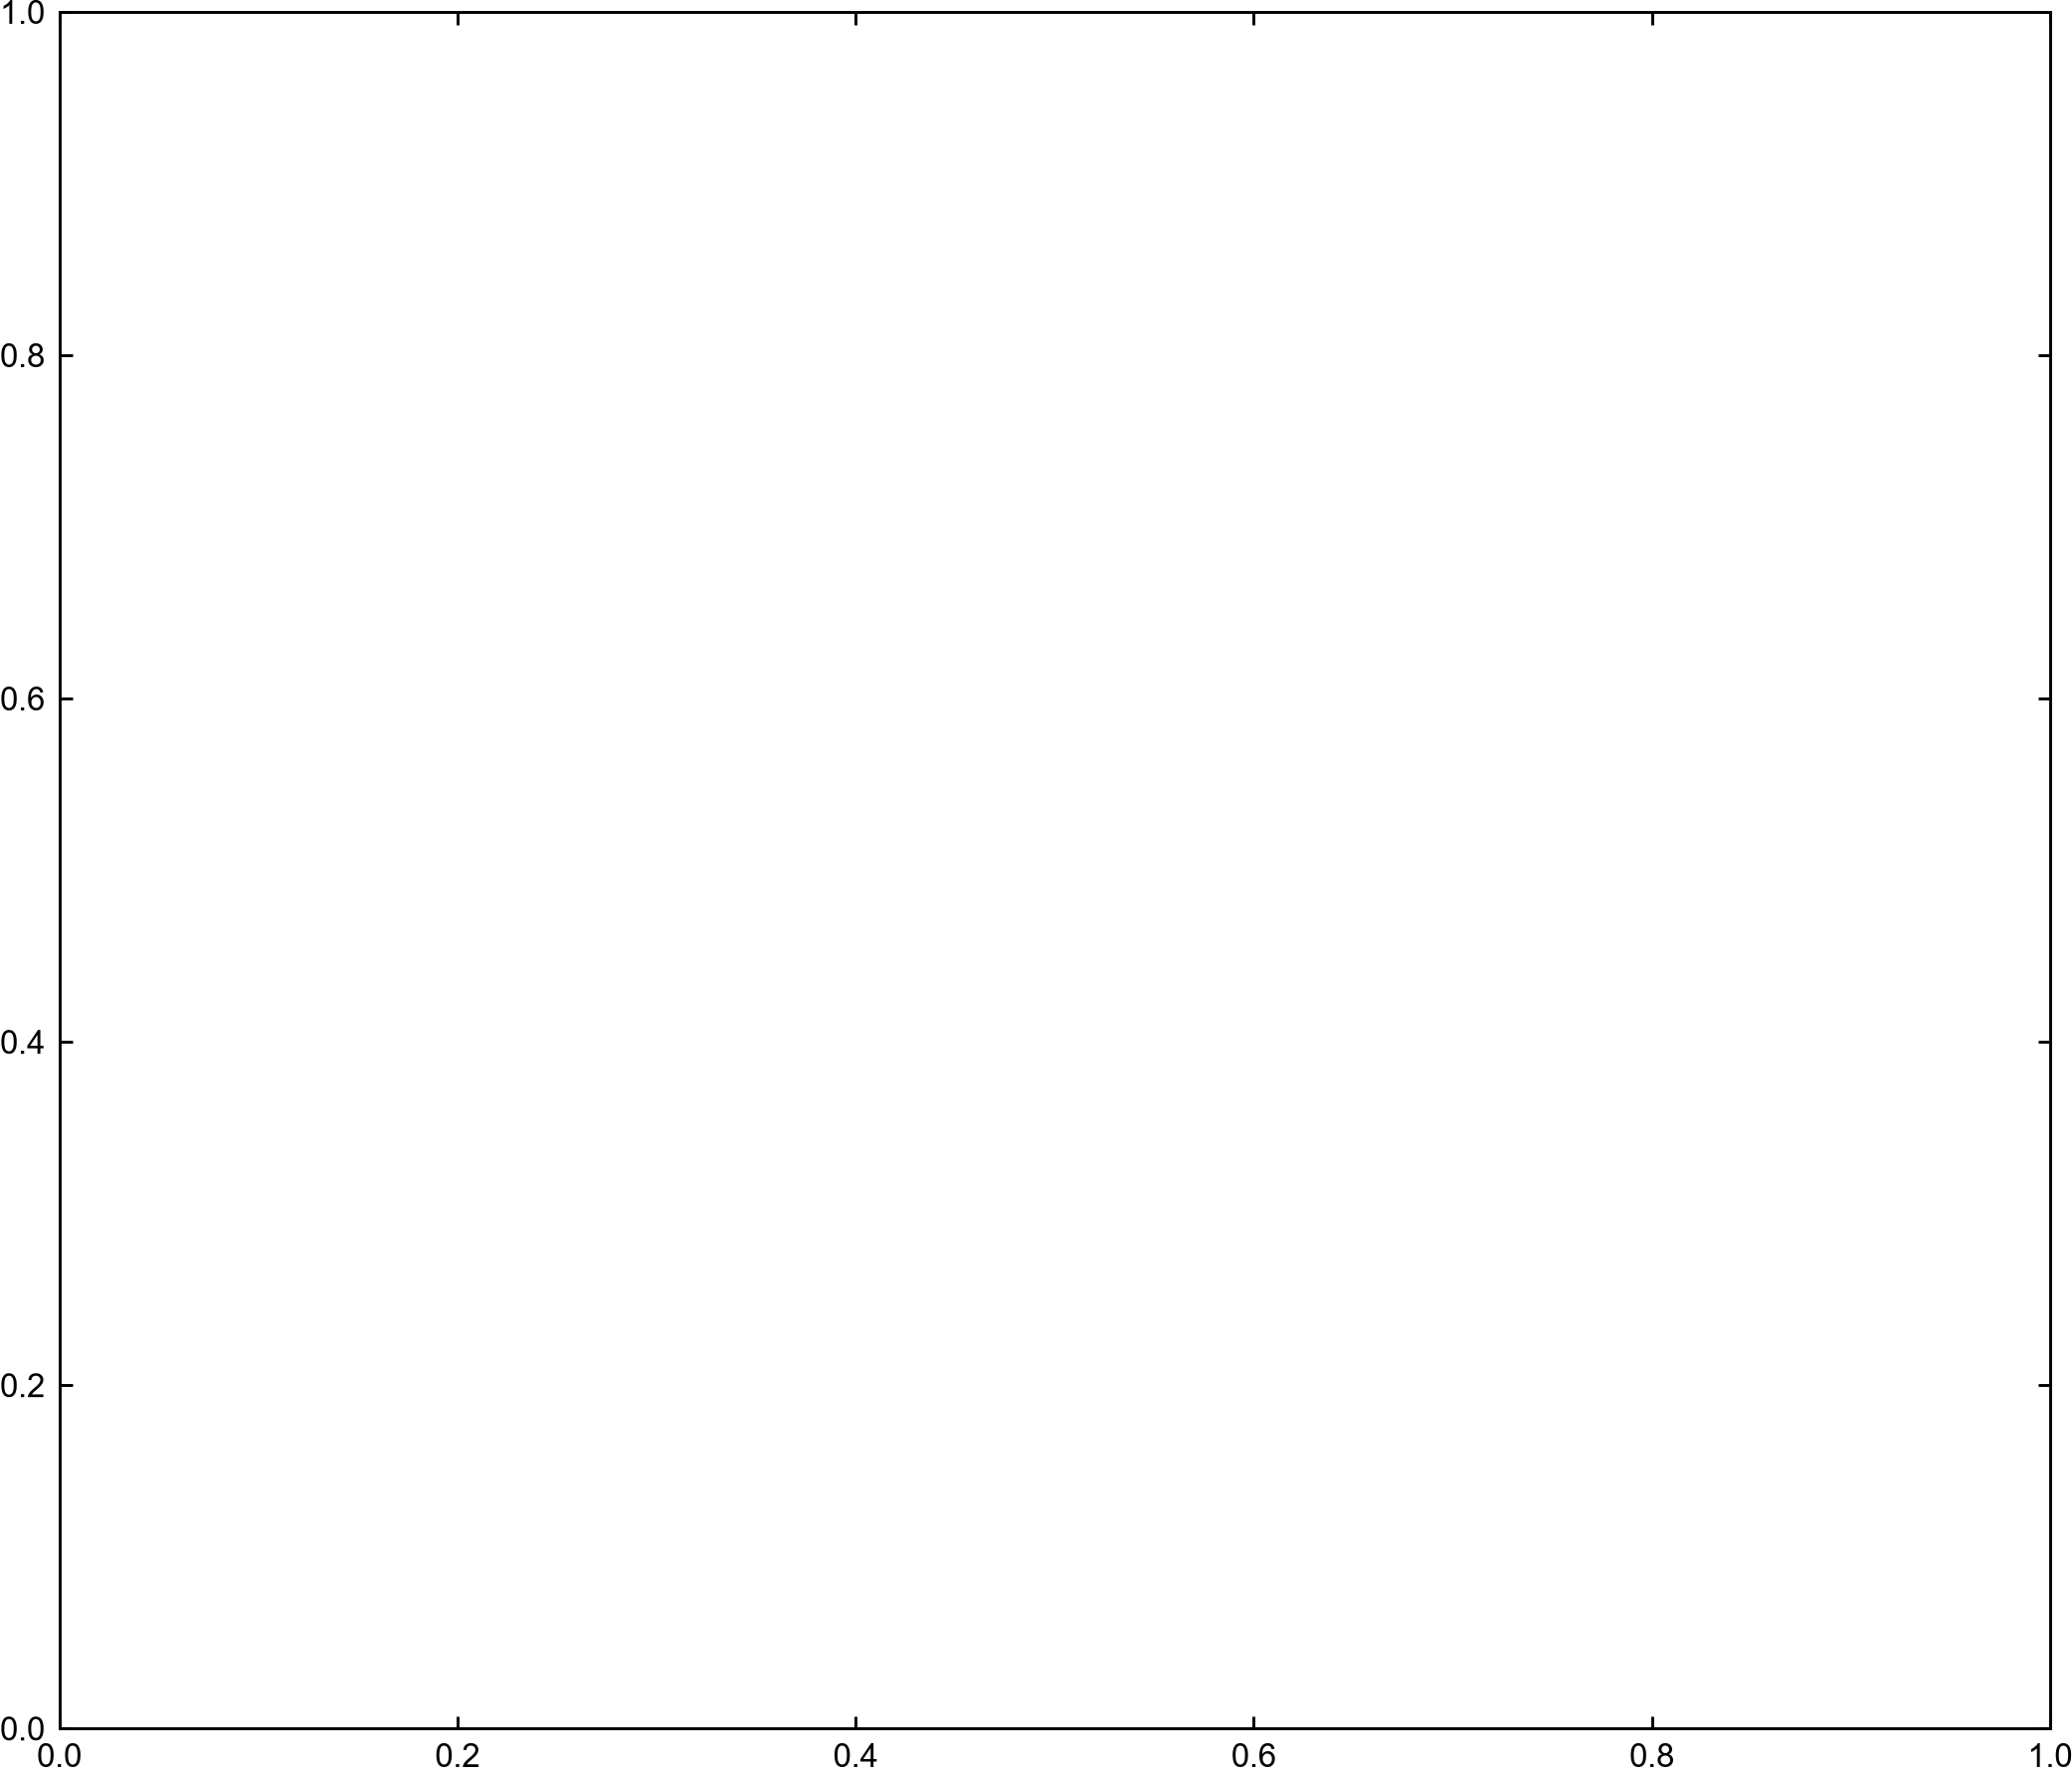

In [11]:
from matplotlib.animation import FuncAnimation, FFMpegWriter

fig, ax = plt.subplots(
    figsize=(7, 6)
)

first = np.squeeze(
    imread(files[0])
).astype(float)

display = ax.imshow(
    first[ymin:ymax, xmin:xmax],
    cmap="Blues",
    origin="upper",
    vmin=VMIN,
    vmax=VMAX
)

title = ax.set_title(
    f"10×10 axial scan — step {steps[0]:+d}"
)

ax.set_xlabel("Camera x [px]")
ax.set_ylabel("Camera y [px]")


def update(frame_index):

    img_frame = np.squeeze(
        imread(files[frame_index])
    ).astype(float)

    crop = img_frame[
        ymin:ymax,
        xmin:xmax
    ]

    display.set_data(crop)

    title.set_text(
        f"10×10 axial scan — step {steps[frame_index]:+d}"
    )

    return display, title


anim = FuncAnimation(
    fig,
    update,
    frames=len(files),
    interval=100,
    blit=False
)


VIDEO_PATH = (
    SCAN_DIR
    /
    "10x10_axial_scan.mp4"
)


writer = FFMpegWriter(
    fps=10,
    bitrate=5000
)


anim.save(
    VIDEO_PATH,
    writer=writer,
    dpi=150
)

plt.close(fig)

print("Saved video:")
print(VIDEO_PATH)

Number of frames: 100
Step range: -100 to 100
Missing nominal 2-step positions:
[np.int64(60)]
Video display range: 1.0 319.0


FileNotFoundError: [WinError 2] The system cannot find the file specified

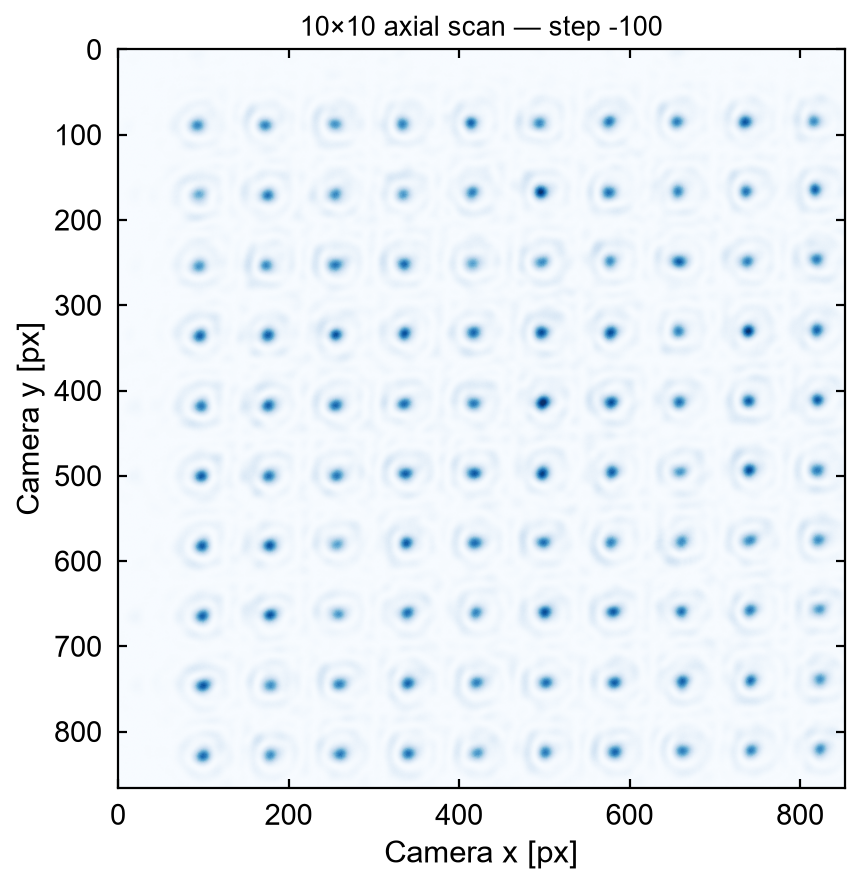

In [ ]:
# ============================================================
# AXIAL SCAN VIDEO
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from tifffile import imread


SCAN_DIR = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Data"
    r"\atom array\10x10 axial scan"
)

# ------------------------------------------------------------
# LOAD FILES IN NUMERICAL ORDER
# ------------------------------------------------------------

files = sorted(
    SCAN_DIR.glob("*.tif"),
    key=lambda p: int(p.stem)
)

steps = np.array([
    int(p.stem)
    for p in files
])

print("Number of frames:", len(files))
print("Step range:", steps.min(), "to", steps.max())

expected = np.arange(
    steps.min(),
    steps.max() + 2,
    2
)

missing = sorted(
    set(expected) - set(steps)
)

print("Missing nominal 2-step positions:")
print(missing)


# ------------------------------------------------------------
# LOAD FIRST FRAME AND CHOOSE CROP
#
# Since your 10x10 stays roughly in the same place,
# determine crop from the fitted coordinates already available
# in df from your single-image analysis.
# ------------------------------------------------------------

MARGIN = 60

xmin = int(
    np.floor(
        df["x"].min() - MARGIN
    )
)

xmax = int(
    np.ceil(
        df["x"].max() + MARGIN
    )
)

ymin = int(
    np.floor(
        df["y"].min() - MARGIN
    )
)

ymax = int(
    np.ceil(
        df["y"].max() + MARGIN
    )
)


# ------------------------------------------------------------
# GLOBAL DISPLAY SCALING
#
# Important: use the SAME intensity scale for every frame.
# Otherwise defocused frames will be auto-brightened.
# ------------------------------------------------------------

sample_imgs = []

for p in files[::max(1, len(files)//10)]:

    im = np.squeeze(
        imread(p)
    ).astype(float)

    sample_imgs.append(
        im[ymin:ymax, xmin:xmax]
    )

sample_stack = np.concatenate([
    x.ravel()
    for x in sample_imgs
])

VMIN = np.percentile(
    sample_stack,
    1
)

VMAX = np.percentile(
    sample_stack,
    99.9
)

print("Video display range:", VMIN, VMAX)


# ------------------------------------------------------------
# CREATE VIDEO
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 6)
)

first = np.squeeze(
    imread(files[0])
).astype(float)

display = ax.imshow(
    first[ymin:ymax, xmin:xmax],
    cmap="Blues",
    origin="upper",
    vmin=VMIN,
    vmax=VMAX
)

title = ax.set_title(
    f"Axial scan — step {steps[0]:+d}"
)

ax.set_xlabel("Camera x [px]")
ax.set_ylabel("Camera y [px]")


def update(frame_index):

    img_frame = np.squeeze(
        imread(files[frame_index])
    ).astype(float)

    crop = img_frame[
        ymin:ymax,
        xmin:xmax
    ]

    display.set_data(
        crop
    )

    title.set_text(
        f"10×10 axial scan — step {steps[frame_index]:+d}"
    )

    return display, title


anim = FuncAnimation(
    fig,
    update,
    frames=len(files),
    interval=100,
    blit=False
)


VIDEO_PATH = (
    SCAN_DIR
    /
    "10x10_axial_scan.mp4"
)

writer = FFMpegWriter(
    fps=10,
    bitrate=5000
)

anim.save(
    VIDEO_PATH,
    writer=writer,
    dpi=150
)

plt.close(fig)

print("Saved video:")
print(VIDEO_PATH)

In [ ]:
# ============================================================
# ANALYZE FULL AXIAL SCAN
# ============================================================

from scipy.ndimage import gaussian_filter, maximum_filter
import pandas as pd


scan_results = []


for frame_number, (step, file) in enumerate(
    zip(steps, files)
):

    print(
        f"[{frame_number+1:3d}/{len(files)}] "
        f"step = {step:+4d}"
    )

    img_z = np.squeeze(
        imread(file)
    ).astype(float)


    # ========================================================
    # DETECT THE 100 TWEEZERS IN THIS FRAME
    # ========================================================

    smooth = gaussian_filter(
        img_z,
        sigma=2
    )

    local_max = (
        smooth
        ==
        maximum_filter(
            smooth,
            size=35
        )
    )

    threshold = max(
        5 * np.median(smooth),
        np.percentile(smooth, 97)
    )

    coords_yx = np.argwhere(
        local_max
        &
        (smooth > threshold)
    )

    brightness = smooth[
        coords_yx[:, 0],
        coords_yx[:, 1]
    ]

    order = np.argsort(
        brightness
    )[::-1]

    coords_yx = coords_yx[
        order[:100]
    ]


    if len(coords_yx) != 100:

        print(
            "WARNING:",
            len(coords_yx),
            "spots detected"
        )

        continue


    initial_peaks_z = np.column_stack([
        coords_yx[:, 1],
        coords_yx[:, 0]
    ])


    # ========================================================
    # FIT ALL 100
    # ========================================================

    frame_fits = []

    for xg, yg in initial_peaks_z:

        try:

            fit = fit_spot(
                img_z,
                xg,
                yg
            )

            frame_fits.append(
                fit
            )

        except Exception as e:

            print(
                "Fit failed:",
                e
            )


    if len(frame_fits) != 100:
        continue


    df_z = pd.DataFrame(
        frame_fits
    )


    # geometric mean FWHM
    fwhm_geo = np.sqrt(
        df_z["fwhm_x"]
        *
        df_z["fwhm_y"]
    )


    # --------------------------------------------------------
    # STORE FRAME SUMMARY
    # --------------------------------------------------------

    scan_results.append({

        "step": step,

        "mean_fwhm_geo":
            fwhm_geo.mean(),

        "std_fwhm_geo":
            fwhm_geo.std(ddof=1),

        "median_fwhm_geo":
            np.median(fwhm_geo),

        "mean_fwhm_x":
            df_z["fwhm_x"].mean(),

        "mean_fwhm_y":
            df_z["fwhm_y"].mean(),

        "mean_x":
            df_z["x"].mean(),

        "mean_y":
            df_z["y"].mean(),

        "mean_power":
            df_z["power"].mean(),
    })


scan_df = pd.DataFrame(
    scan_results
).sort_values(
    "step"
).reset_index(
    drop=True
)


print("\nFrames successfully analyzed:")
print(len(scan_df))

[  1/100] step = -100
[  2/100] step =  -98
[  3/100] step =  -96
[  4/100] step =  -94
[  5/100] step =  -92
[  6/100] step =  -90
[  7/100] step =  -88
[  8/100] step =  -86
[  9/100] step =  -84
[ 10/100] step =  -82
[ 11/100] step =  -80
[ 12/100] step =  -78
[ 13/100] step =  -76
[ 14/100] step =  -74
[ 15/100] step =  -72
[ 16/100] step =  -70
[ 17/100] step =  -68
[ 18/100] step =  -66
[ 19/100] step =  -64
[ 20/100] step =  -62
[ 21/100] step =  -60
[ 22/100] step =  -58
[ 23/100] step =  -56
[ 24/100] step =  -54
[ 25/100] step =  -52
[ 26/100] step =  -50
[ 27/100] step =  -48
[ 28/100] step =  -46
[ 29/100] step =  -44
[ 30/100] step =  -42
[ 31/100] step =  -40
[ 32/100] step =  -38
[ 33/100] step =  -36
[ 34/100] step =  -34
[ 35/100] step =  -32
[ 36/100] step =  -30
[ 37/100] step =  -28
[ 38/100] step =  -26
[ 39/100] step =  -24
[ 40/100] step =  -22
[ 41/100] step =  -20
[ 42/100] step =  -18
[ 43/100] step =  -16
[ 44/100] step =  -14
[ 45/100] step =  -12
[ 46/100] 

In [ ]:
# ============================================================
# ANALYZE FULL AXIAL SCAN
# ============================================================

from scipy.ndimage import gaussian_filter, maximum_filter
import pandas as pd


scan_results = []


for frame_number, (step, file) in enumerate(
    zip(steps, files)
):

    print(
        f"[{frame_number+1:3d}/{len(files)}] "
        f"step = {step:+4d}"
    )

    img_z = np.squeeze(
        imread(file)
    ).astype(float)


    # ========================================================
    # DETECT THE 100 TWEEZERS IN THIS FRAME
    # ========================================================

    smooth = gaussian_filter(
        img_z,
        sigma=2
    )

    local_max = (
        smooth
        ==
        maximum_filter(
            smooth,
            size=35
        )
    )

    threshold = max(
        5 * np.median(smooth),
        np.percentile(smooth, 97)
    )

    coords_yx = np.argwhere(
        local_max
        &
        (smooth > threshold)
    )

    brightness = smooth[
        coords_yx[:, 0],
        coords_yx[:, 1]
    ]

    order = np.argsort(
        brightness
    )[::-1]

    coords_yx = coords_yx[
        order[:100]
    ]


    if len(coords_yx) != 100:

        print(
            "WARNING:",
            len(coords_yx),
            "spots detected"
        )

        continue


    initial_peaks_z = np.column_stack([
        coords_yx[:, 1],
        coords_yx[:, 0]
    ])


    # ========================================================
    # FIT ALL 100
    # ========================================================

    frame_fits = []

    for xg, yg in initial_peaks_z:

        try:

            fit = fit_spot(
                img_z,
                xg,
                yg
            )

            frame_fits.append(
                fit
            )

        except Exception as e:

            print(
                "Fit failed:",
                e
            )


    if len(frame_fits) != 100:
        continue


    df_z = pd.DataFrame(
        frame_fits
    )


    # geometric mean FWHM
    fwhm_geo = np.sqrt(
        df_z["fwhm_x"]
        *
        df_z["fwhm_y"]
    )


    # --------------------------------------------------------
    # STORE FRAME SUMMARY
    # --------------------------------------------------------

    scan_results.append({

        "step": step,

        "mean_fwhm_geo":
            fwhm_geo.mean(),

        "std_fwhm_geo":
            fwhm_geo.std(ddof=1),

        "median_fwhm_geo":
            np.median(fwhm_geo),

        "mean_fwhm_x":
            df_z["fwhm_x"].mean(),

        "mean_fwhm_y":
            df_z["fwhm_y"].mean(),

        "mean_x":
            df_z["x"].mean(),

        "mean_y":
            df_z["y"].mean(),

        "mean_power":
            df_z["power"].mean(),
    })


scan_df = pd.DataFrame(
    scan_results
).sort_values(
    "step"
).reset_index(
    drop=True
)


print("\nFrames successfully analyzed:")
print(len(scan_df))

[  1/100] step = -100
[  2/100] step =  -98
[  3/100] step =  -96
[  4/100] step =  -94
[  5/100] step =  -92
[  6/100] step =  -90
[  7/100] step =  -88
[  8/100] step =  -86
[  9/100] step =  -84
[ 10/100] step =  -82
[ 11/100] step =  -80
[ 12/100] step =  -78
[ 13/100] step =  -76
[ 14/100] step =  -74
[ 15/100] step =  -72
[ 16/100] step =  -70
[ 17/100] step =  -68
[ 18/100] step =  -66
[ 19/100] step =  -64
[ 20/100] step =  -62
[ 21/100] step =  -60
[ 22/100] step =  -58
[ 23/100] step =  -56
[ 24/100] step =  -54
[ 25/100] step =  -52
[ 26/100] step =  -50
[ 27/100] step =  -48
[ 28/100] step =  -46
[ 29/100] step =  -44
[ 30/100] step =  -42
[ 31/100] step =  -40
[ 32/100] step =  -38
[ 33/100] step =  -36
[ 34/100] step =  -34
[ 35/100] step =  -32
[ 36/100] step =  -30
[ 37/100] step =  -28
[ 38/100] step =  -26
[ 39/100] step =  -24
[ 40/100] step =  -22
[ 41/100] step =  -20
[ 42/100] step =  -18
[ 43/100] step =  -16
[ 44/100] step =  -14
[ 45/100] step =  -12
[ 46/100] 

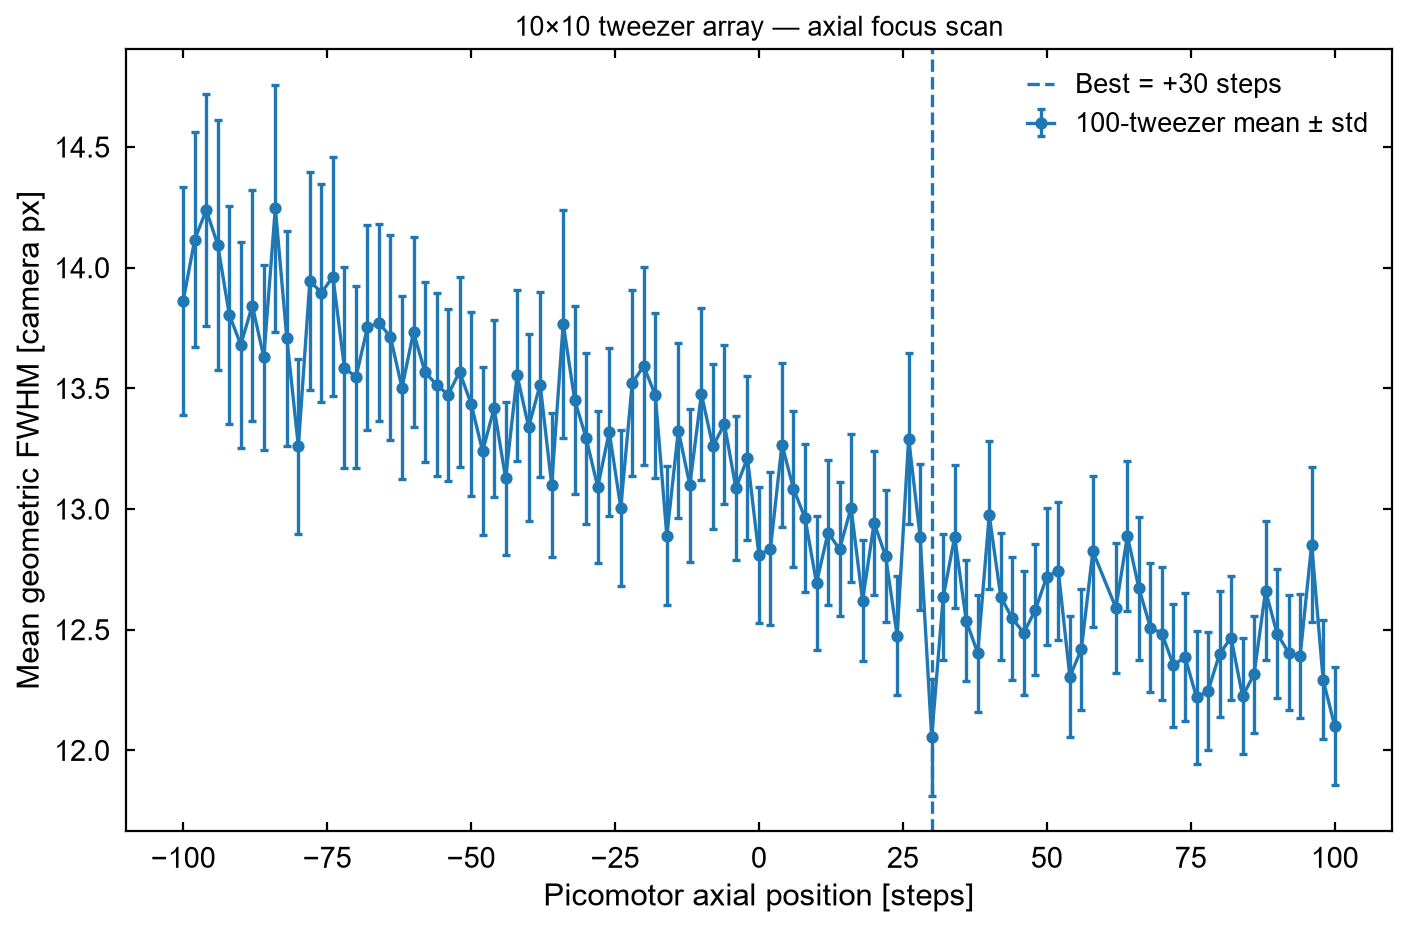

BEST GLOBAL FOCUS
Best step:
30

Mean geometric FWHM [px]:
12.055031247380427

Mean geometric FWHM [nm]:
684.7944885293183


In [ ]:
# ============================================================
# MEAN PSF SIZE VS AXIAL STEP
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.errorbar(
    scan_df["step"],
    scan_df["mean_fwhm_geo"],
    yerr=scan_df["std_fwhm_geo"],
    fmt="o-",
    markersize=4,
    capsize=2,
    label="100-tweezer mean ± std"
)

best_idx = scan_df[
    "mean_fwhm_geo"
].idxmin()

best_step = scan_df.loc[
    best_idx,
    "step"
]

best_fwhm = scan_df.loc[
    best_idx,
    "mean_fwhm_geo"
]

plt.axvline(
    best_step,
    linestyle="--",
    label=f"Best = {best_step:+d} steps"
)

plt.xlabel(
    "Picomotor axial position [steps]"
)

plt.ylabel(
    "Mean geometric FWHM [camera px]"
)

plt.title(
    "10×10 tweezer array — axial focus scan"
)

plt.legend()

plt.tight_layout()
plt.show()


print("====================================")
print("BEST GLOBAL FOCUS")
print("====================================")

print("Best step:")
print(best_step)

print("\nMean geometric FWHM [px]:")
print(best_fwhm)

if PIXEL_NM is not None:

    print("\nMean geometric FWHM [nm]:")
    print(
        best_fwhm
        * PIXEL_NM
    )

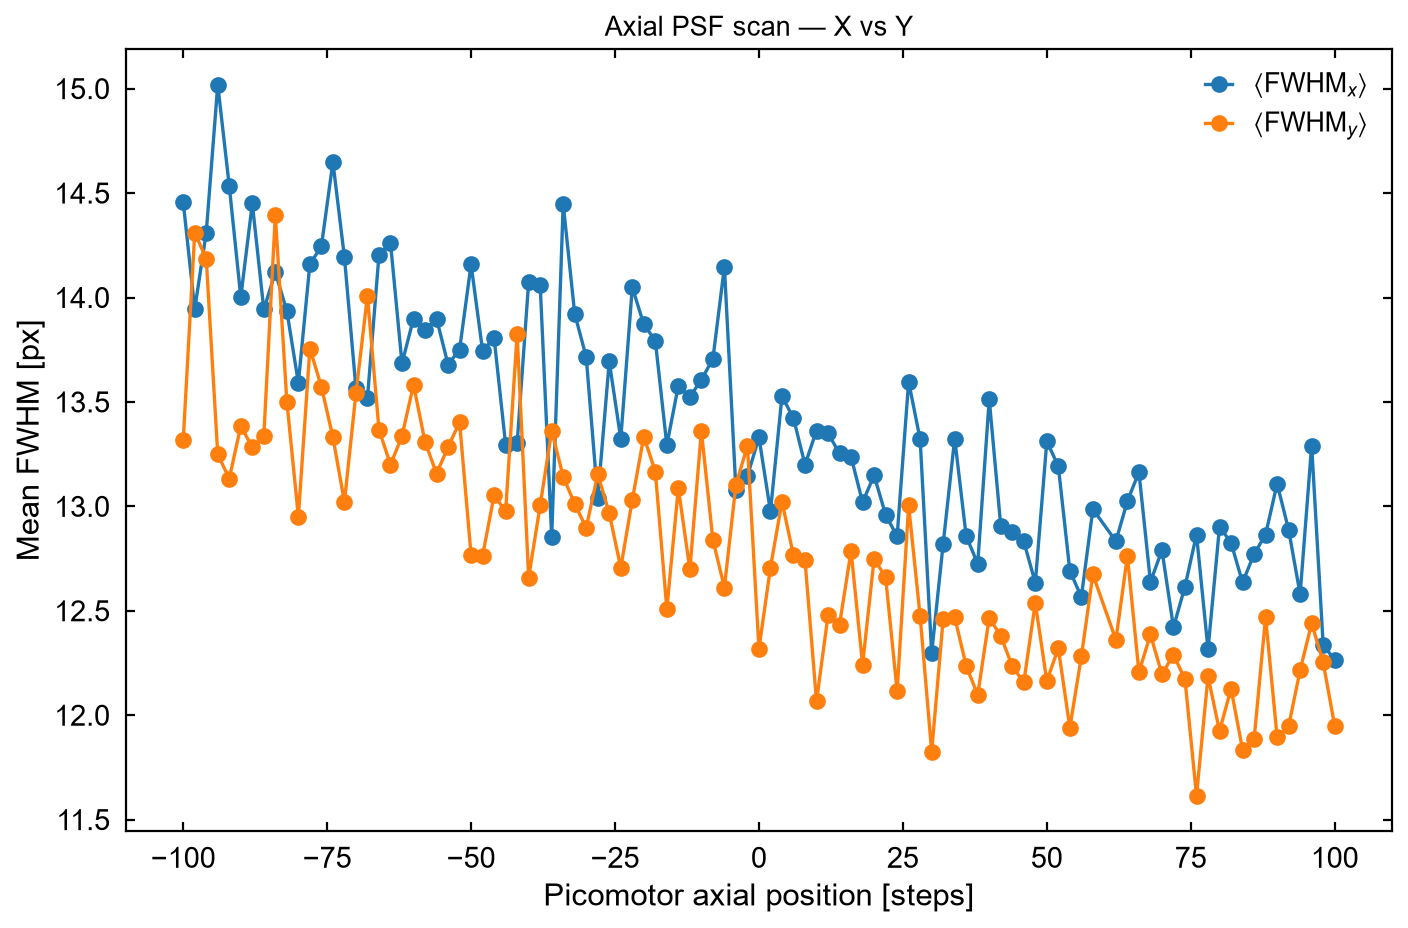

In [ ]:
plt.figure(
    figsize=(9, 6)
)

plt.plot(
    scan_df["step"],
    scan_df["mean_fwhm_x"],
    "o-",
    label=r"$\langle\mathrm{FWHM}_x\rangle$"
)

plt.plot(
    scan_df["step"],
    scan_df["mean_fwhm_y"],
    "o-",
    label=r"$\langle\mathrm{FWHM}_y\rangle$"
)

plt.xlabel(
    "Picomotor axial position [steps]"
)

plt.ylabel(
    "Mean FWHM [px]"
)

plt.title(
    "Axial PSF scan — X vs Y"
)

plt.legend()

plt.tight_layout()
plt.show()

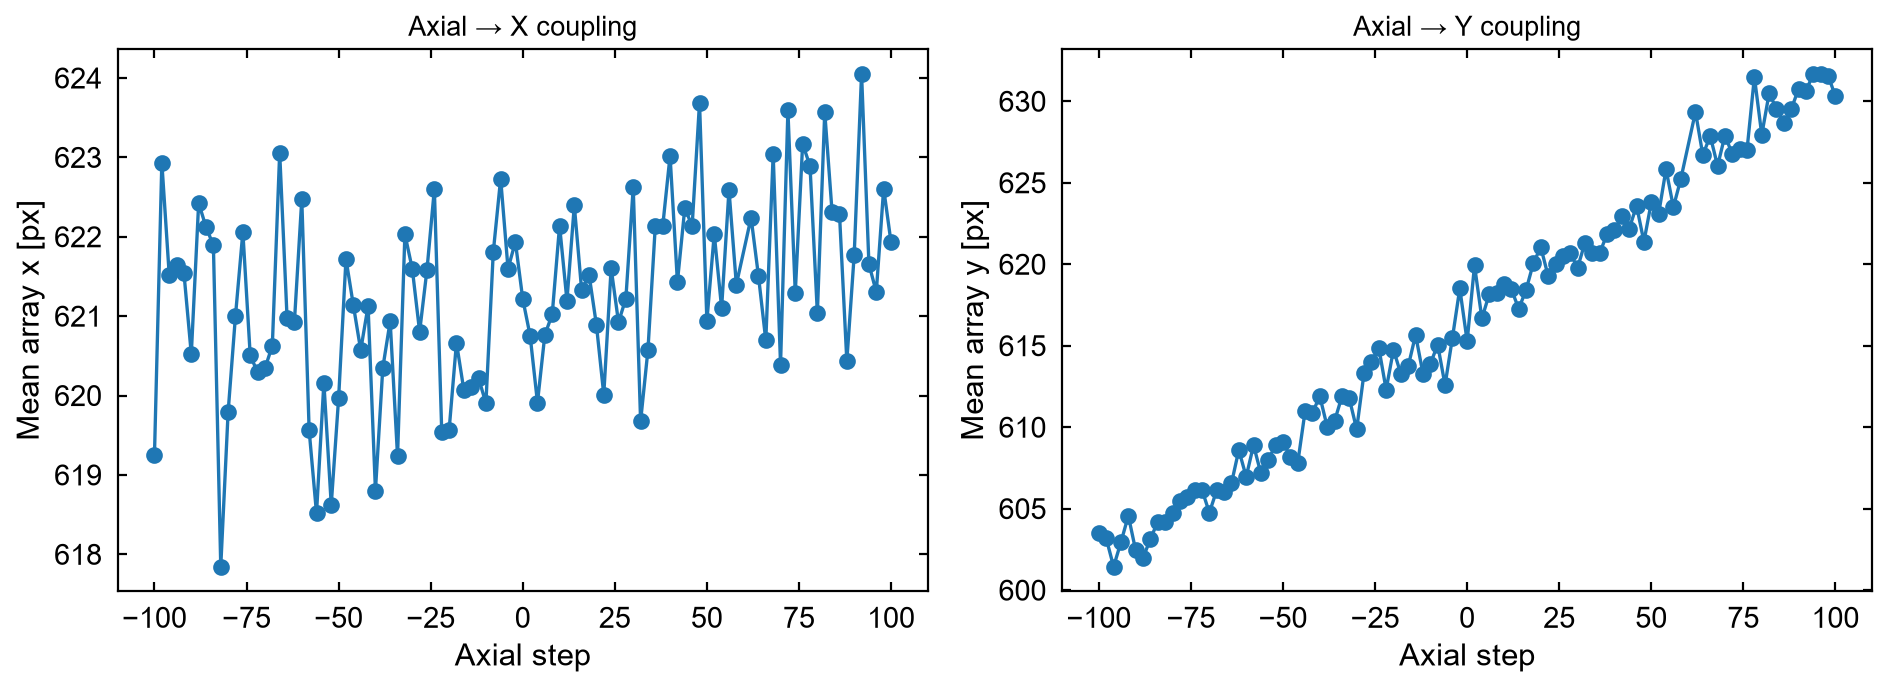

In [ ]:
# ============================================================
# ARRAY CENTROID MOTION DURING AXIAL SCAN
# ============================================================

fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 4.5)
)

ax[0].plot(
    scan_df["step"],
    scan_df["mean_x"],
    "o-"
)

ax[0].set_xlabel(
    "Axial step"
)

ax[0].set_ylabel(
    "Mean array x [px]"
)

ax[0].set_title(
    "Axial → X coupling"
)


ax[1].plot(
    scan_df["step"],
    scan_df["mean_y"],
    "o-"
)

ax[1].set_xlabel(
    "Axial step"
)

ax[1].set_ylabel(
    "Mean array y [px]"
)

ax[1].set_title(
    "Axial → Y coupling"
)

plt.tight_layout()
plt.show()